# Formula 1 Podium Prediction — Milestone 1

**Task:** for every driver who starts a Grand Prix, predict **before the race** (after qualifying) whether he finishes on the podium (top 3).
The notebook runs top to bottom (Run All) on the Ergast F1 dataset (14 CSVs).

| Part | What it does | Sections |
|---|---|---|
| **1. Audit & cleaning** | find every data problem, fix it, show before/after | 1.0 setup · 1.1 load · 1.2 EDA before · 1.3 cleaning · 1.4 EDA after · 1.5 decision log |
| **2. Data-engineering questions** | Q1 front row → podium per circuit · Q2 home advantage · Q3 mechanical retirements | Q1 · Q2 · Q3 · summary |
| **3. Features & split** | modeling table, time split, candidate features, leakage test, evidence, trials, preprocessing | 3.1–3.11 |
| **4. Models** | baselines, logistic regression, random forest, gradient boosting, shallow neural network | 4.0–4.12 |
| **5. Feature-group ablation** | retrain without each group; paired race bootstrap | 5.0–5.10 |
| **6. Explainability (XAI)** | permutation importance, SHAP, LIME | 6.0–6.6 |
| **7. Inference function** | `predict_podium_for(record)` on a complete and a partially-missing record | 7.1–7.3 |

**Conventions used everywhere**
* Each step reads **why → code → result**. Numbers in the text are the outputs directly above them.
* Section references include the part number (`§1.2.7` = Part 1, section 2.7; `3.8` = Part 3, section 8).
* The **test seasons (2022–24) are never used to choose anything**; they are only reported.

---

# Part 1: Audit & Cleaning

**Goal:** turn the 14 raw CSVs into clean, correctly typed tables, with `results` at **one row per driver per race**.

**How this notebook is organised**
1. Load the raw files untouched
2. EDA **before** cleaning: find every problem and measure it
3. Cleaning: fix each problem, explaining why
4. EDA **after** cleaning: same plots, to show the effect
5. Decision log + export

Every step follows the same pattern: **why → code → what we found / did**.

## 1.0 Setup

In [ ]:
import os, sys, glob, html, re, json, unicodedata, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import StratifiedTable
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             precision_recall_curve, roc_curve)
try:
    import lime
except ModuleNotFoundError:                      # Colab does not ship LIME; install it only if missing
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])
from lime.lime_tabular import LimeTabularExplainer
import shap
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras

warnings.filterwarnings("ignore")
SEED = 42
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
BEFORE, AFTER, ACCENT, GREY = "#B4552D", "#2F6B9A", "#D9A441", "#9AA0A6"
SPLIT_COLORS = {"train": AFTER, "validation": ACCENT, "test": BEFORE}

# find the data folder (Kaggle input, or any folder below the current one)
found = glob.glob("/kaggle/input/**/results.csv", recursive=True) + glob.glob("./**/results.csv", recursive=True)
if not found:
    raise FileNotFoundError("results.csv not found. Attach the F1 dataset (Kaggle: Add Input) or put the 14 CSVs "
                            "in a folder next to this notebook (Colab: upload or unzip them), then run again.")
DATA_DIR = os.path.dirname(found[0])
OUT_DIR = "/kaggle/working/clean" if os.path.exists("/kaggle/working") else "./clean"
os.makedirs(OUT_DIR, exist_ok=True)

TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "sprint_results", "seasons", "status"]

def text_columns(df):
    return [c for c in df.columns if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c])]

print("data:", DATA_DIR, "| output:", OUT_DIR)
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | tensorflow {tf.__version__} | shap {shap.__version__}")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


I0000 00:00:1792414680.208904   10268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


data: ./data | output: ./clean
pandas 3.0.5 | scikit-learn 1.9.1 | tensorflow 2.21.0 | shap 0.54.1


I0000 00:00:1792414681.545528   10268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1.1 Load the raw files

load eveyrthing as test instead of guessing the type.

`raw` is never modified. All cleaning happens on a copy (`clean`).

In [ ]:
raw = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}
naive = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv") for t in TABLES}   # what a normal read_csv gives, for comparison

pd.DataFrame({"rows": {t: len(raw[t]) for t in TABLES},
              "columns": {t: raw[t].shape[1] for t in TABLES}}).sort_values("rows", ascending=False)

,rows,columns
lap_times,589081,6
driver_standings,34863,7
results,26759,18
constructor_standings,13391,7
constructor_results,12625,5
pit_stops,11371,7
qualifying,10494,9
races,1125,18
drivers,861,9
sprint_results,360,16


## 1.2 EDA before cleaning

### 1.2.1 Hidden missing values
Missing values in these files are written as the text `\N`, not left empty. We also check for empty strings.

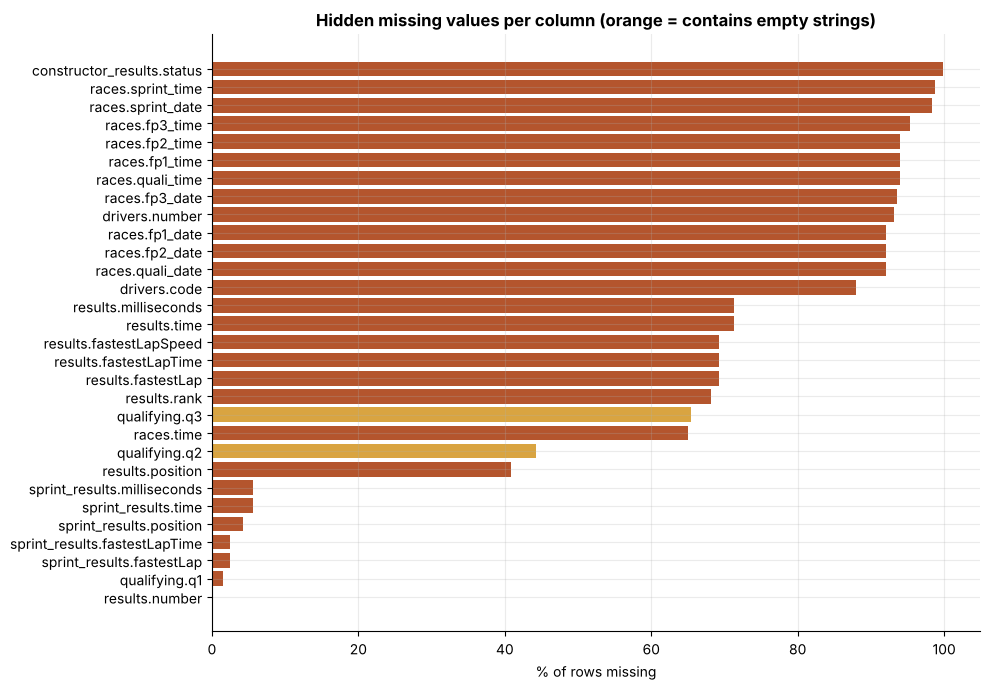

,table,column,\N,empty string,% missing
0,constructor_results,status,12608,0,99.9
1,races,sprint_time,1110,0,98.7
2,races,sprint_date,1107,0,98.4
3,races,fp3_time,1072,0,95.3
4,races,fp2_time,1057,0,94.0
5,races,fp1_time,1057,0,94.0
6,races,quali_time,1057,0,94.0
7,races,fp3_date,1053,0,93.6
8,drivers,number,802,0,93.1
9,races,fp1_date,1035,0,92.0


In [ ]:
rows = []
for t in TABLES:
    for c in raw[t].columns:
        n_N = (raw[t][c] == r"\N").sum()
        n_empty = (raw[t][c].str.strip() == "").sum()
        if n_N + n_empty > 0:
            rows.append({"table": t, "column": c, r"\N": n_N, "empty string": n_empty,
                         "% missing": round(100 * (n_N + n_empty) / len(raw[t]), 1)})
placeholders = pd.DataFrame(rows).sort_values("% missing", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 7))
p = placeholders.iloc[::-1]
ax.barh(p.table + "." + p.column, p["% missing"], color=[ACCENT if e > 0 else BEFORE for e in p["empty string"]])
ax.set_xlabel("% of rows missing"); ax.set_title(r"Hidden missing values per column (orange = contains empty strings)")
plt.tight_layout(); plt.show()
placeholders

`\N` appears in 30 columns across 6 tables. Empty strings are found only in `qualifying.q2` and `q3`. Both are changed to real missing values (`NaN`).

### 1.2.2 Numbers stored as text
Because of `\N`, a normal `read_csv` loads these number columns as text so `position <= 3` would compare text, not numbers.

In [ ]:
rows = []
for t in TABLES:
    for c in raw[t].columns:
        values = raw[t][c][~raw[t][c].isin([r"\N", ""])]
        all_numbers = len(values) > 0 and pd.to_numeric(values, errors="coerce").notna().all()
        if all_numbers and not pd.api.types.is_numeric_dtype(naive[t][c]):
            rows.append({"table": t, "column": c, "loaded as": "text"})
pd.DataFrame(rows)

,table,column,loaded as
0,drivers,number,text
1,results,number,text
2,results,position,text
3,results,milliseconds,text
4,results,fastestLap,text
5,results,rank,text
6,results,fastestLapSpeed,text
7,sprint_results,position,text
8,sprint_results,milliseconds,text
9,sprint_results,fastestLap,text


### 1.2.3 Times stored as text
Lap and qualifying times look like `"1:23.456"`. A model can't compare these until they become seconds (83.456).

In [ ]:
time_columns = [("qualifying", "q1"), ("qualifying", "q2"), ("qualifying", "q3"), ("results", "fastestLapTime"),
                ("sprint_results", "fastestLapTime"), ("lap_times", "time"), ("pit_stops", "duration")]
pd.DataFrame([{"table": t, "column": c, "example": raw[t][c][raw[t][c].str.contains(":")].iloc[0]}
              for t, c in time_columns])

,table,column,example
0,qualifying,q1,1:26.572
1,qualifying,q2,1:25.187
2,qualifying,q3,1:26.714
3,results,fastestLapTime,1:27.452
4,sprint_results,fastestLapTime,1:30.013
5,lap_times,time,1:38.109
6,pit_stops,duration,16:44.718


**Note:** `pit_stops.duration` is mostly plain seconds (`"23.2"`), but some rows are minutes (`"16:44.718"`). One parser must handle both formats.

### 1.2.4 Duplicates: is there one row per driver per race?
Each row will be one prediction ("will this driver podium in this race?"), so a driver must appear once per race.

driver-race pairs that appear more than once: 85
extra rows to remove: 91


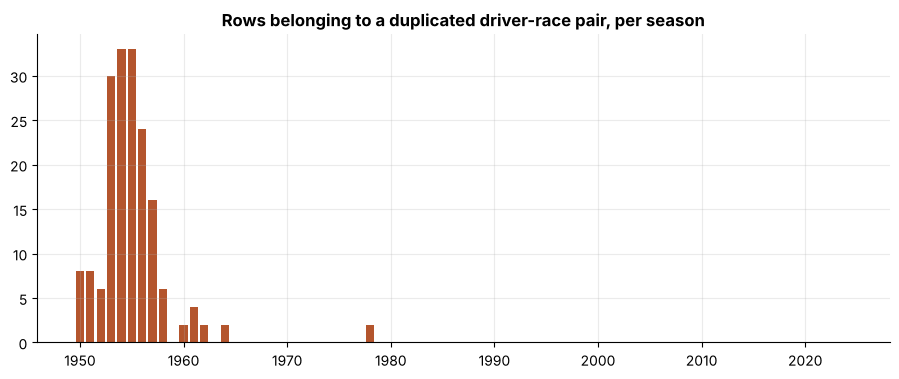

In [ ]:
res_raw = naive["results"].merge(naive["races"][["raceId", "year"]], on="raceId")
is_dup = res_raw.duplicated(["raceId", "driverId"], keep=False)
dups_per_year_before = res_raw[is_dup].groupby("year").size().reindex(range(1950, 2025), fill_value=0)

print("driver-race pairs that appear more than once:", res_raw[is_dup].groupby(["raceId", "driverId"]).ngroups)
print("extra rows to remove:", is_dup.sum() - res_raw[is_dup].groupby(["raceId", "driverId"]).ngroups)

fig, ax = plt.subplots()
ax.bar(dups_per_year_before.index, dups_per_year_before.values, color=BEFORE)
ax.set_title("Rows belonging to a duplicated driver-race pair, per season"); plt.show()

85 duplicated pairs (91 extra rows), all between 1950 and 1978. This is the era of shared drives, when drivers swapped cars mid-race. Fixed in 1.3.6.

### 1.2.5 Verifying `grid = 0` & pit-lane starts
We check what actually happened to those drivers.

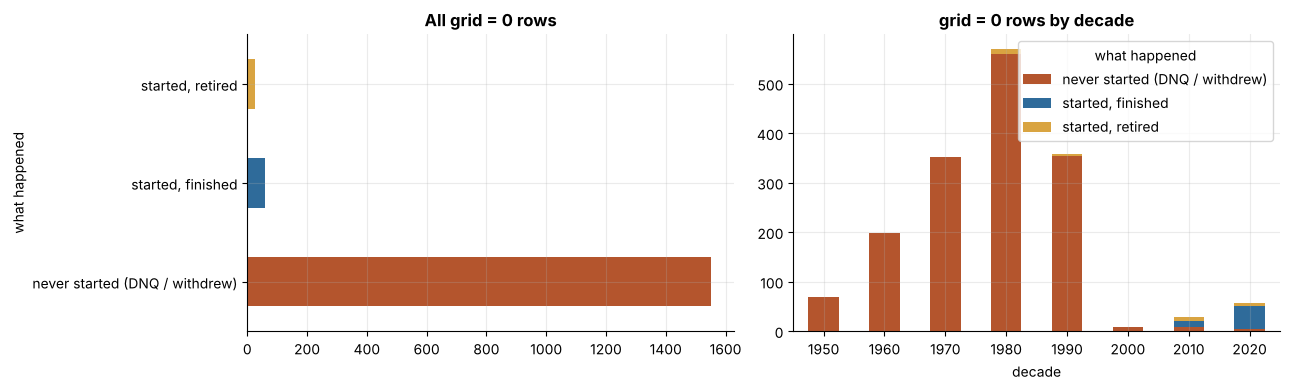

,rows
what happened,
never started (DNQ / withdrew),1551
"started, finished",60
"started, retired",27


In [ ]:
g0 = res_raw[res_raw.grid == 0].copy()
g0["what happened"] = "started, retired"
g0.loc[g0.positionText.str.isdigit(), "what happened"] = "started, finished"
g0.loc[g0.positionText.isin(["F", "W"]), "what happened"] = "never started (DNQ / withdrew)"

counts = g0["what happened"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts.plot(kind="barh", ax=axes[0], color=[BEFORE, AFTER, ACCENT]); axes[0].set_title("All grid = 0 rows")
pd.crosstab(g0.year // 10 * 10, g0["what happened"]).plot(kind="bar", stacked=True, ax=axes[1], rot=0,
                                                         color=[BEFORE, AFTER, ACCENT])
axes[1].set_title("grid = 0 rows by decade"); axes[1].set_xlabel("decade")
plt.tight_layout(); plt.show()
counts.to_frame("rows")

`grid = 0` is **mostly not a pit-lane start**. 1,551 of 1,638 rows are drivers who **never started** (failed to qualify or withdrew). Only 87 started the race from the pit lane. So we must first separate out non-starters so that `grid = 0` refers to "pit-lane start".

### 1.2.6 Field size and podium rate per season
Codes in `positionText`: **F** = failed to qualify, **W** = withdrew, R = retired, D = disqualified, E = excluded, N = not classified.

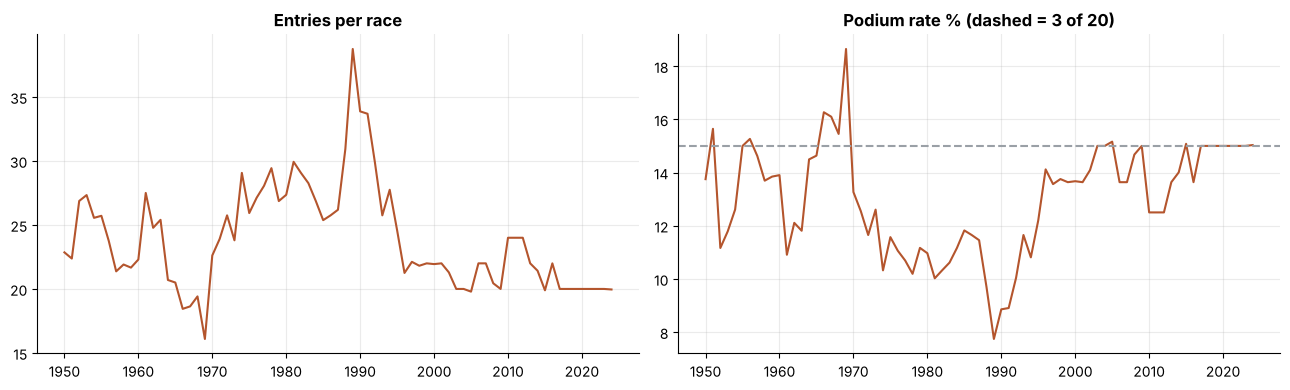

,rows
positionText,
R,8897
F,1368
W,336
N,190
D,151
E,9


In [ ]:
cars_per_race = res_raw.groupby(["year", "raceId"]).size().groupby("year").mean()
podium_rate = (res_raw.positionOrder <= 3).groupby(res_raw.year).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(cars_per_race, color=BEFORE); axes[0].set_title("Entries per race")
axes[1].plot(podium_rate, color=BEFORE); axes[1].axhline(15, ls="--", color=GREY)
axes[1].set_title("Podium rate % (dashed = 3 of 20)")
plt.tight_layout(); plt.show()

res_raw.positionText[~res_raw.positionText.astype(str).str.isdigit()].value_counts().to_frame("rows")

Around 1989 there were up to ~39 *entries* per race, but at most 26 could start. Entries that never started (F, W) can never podium, so they push the podium rate down artificially. they are flagged for now and resolved later (1.3.7).

### 1.2.7 Qualifying coverage per season
The descriptiong says that qualifying data is missing for older years. Coverage = % of race entries that have a qualifying row.

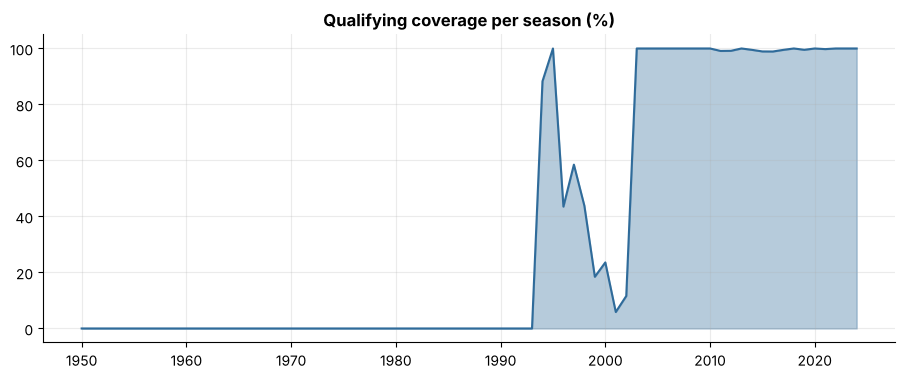

,avg coverage %,worst season %
1950–1993,0.0,0.0
1994–1995,94.1,88.3
1996–2002,29.3,5.9
2003–2024,99.7,98.9


In [ ]:
has_quali = naive["qualifying"][["raceId", "driverId"]].drop_duplicates().assign(has_quali=1)
coverage = (res_raw.merge(has_quali, on=["raceId", "driverId"], how="left")
            .fillna({"has_quali": 0}).groupby("year").has_quali.mean() * 100)

fig, ax = plt.subplots()
ax.fill_between(coverage.index, coverage.values, color=AFTER, alpha=0.35); ax.plot(coverage, color=AFTER)
ax.set_title("Qualifying coverage per season (%)"); plt.show()

periods = {"1950–1993": (1950, 1993), "1994–1995": (1994, 1995), "1996–2002": (1996, 2002), "2003–2024": (2003, 2024)}
pd.DataFrame({"avg coverage %": {k: round(coverage.loc[a:b].mean(), 1) for k, (a, b) in periods.items()},
              "worst season %": {k: round(coverage.loc[a:b].min(), 1) for k, (a, b) in periods.items()}})

Coverage has **4 periods** with no clean starts:

| Period | Coverage |
|---|---|
| before 1994 | none |
| 1994–95 | almost full |
| 1996–2002 | patchy (6–60% per season) |
| from 2003 | ~100% |

This decides later how we handle missing qualifying features (training window, imputation, or falling back to grid).

### 1.2.8 Text problems

Text was cleaned in different ways :

| Kind | Example | Is the data wrong? | Fix |
|---|---|---|---|
| **1. Same thing, two spellings** | `"USA"` and `"United States"` | **Yes** | unify the spelling |
| **2. Different words for linked things** | driver is `"American"`, circuit is in `"USA"` | **No**, both are correct | a translation table (1.3.4), don't edit the data |

to start we shrink every value to a bare form (lowercase, no accents, no spaces or punctuation).

In [ ]:
def bare(x):
    x = unicodedata.normalize("NFKD", str(x)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]", "", x)

def find_spelling_variants(tables):
    rows = []
    for t, df in tables.items():
        if t == "lap_times":
            continue
        for c in text_columns(df):
            if c == "url":
                continue
            values = pd.Series(df[c].dropna().unique()).astype(str)
            values = values[~values.str.fullmatch(r"[\d.:+\- ]*")]          # skip numbers and times
            for _, group in values.groupby(values.map(bare)):
                if len(group) > 1:
                    rows.append({"table": t, "column": c, "variants": list(group)})
    return pd.DataFrame(rows)

find_spelling_variants(raw)

,table,column,variants
0,drivers,forename,"[Adrian, Adrián]"
1,drivers,forename,"[Antônio, Antonio]"
2,drivers,forename,"[Éric, Eric]"
3,drivers,forename,"[Oscar, Óscar]"


The bare-form search only finds variants that differ by accents, spaces or punctuation. `"USA"` vs `"United States"` are completely different words, so we also list the country and nationality columns in full and read them:

In [ ]:
for t, c in [("circuits", "country"), ("drivers", "nationality"), ("constructors", "nationality")]:
    values = sorted(raw[t][c].unique())
    print(f"{t}.{c}  ({len(values)} values)\n{values}\n")

circuits.country  (35 values)
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']

drivers.nationality  (43 values)
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

constructo

**Verdict: what is an error and what isn't**

| Found | Error? | Action | Why |
|---|---|---|---|
| `USA` / `United States` | **yes** | → `USA` | Same country. Only the 2023 Las Vegas circuit uses the long name |
| `Argentine` / `Argentinian ` | **yes** | → `Argentine` | Same nationality. Only Colapinto (2024) has the 2nd spelling, plus a trailing space |
| `Lotus-Pratt &amp; Whitney` | **yes** | → `&` | Web-encoding leftover |
| `Adrian`/`Adrián`, `Eric`/`Éric`, … | no | keep | **Different people**, e.g. Adrian Sutil vs Adrián Campos |
| `American` vs `USA`, `Monegasque` vs `Monaco`, … | no | translation table (1.3.4) | Kind 2: different vocabularies, both correct |
| `American-Italian`, `Argentine-Italian` | no | keep | Real dual nationalities (2 drivers) |
| `East German`, `Rhodesian`, `Liechtensteiner` | no | keep | Real nationalities for their time |
| Status `Injury`/`Injured`, `Puncture`/`Tyre puncture`, … | no | keep | Similar meanings are grouped later in Q3. Merging now would hide detail |

## 1.3 Cleaning

### 1.3.1 Missing placeholders → NaN, numbers → numeric
**Rule:** turn `\N` and empty strings into `NaN`. Then convert a column to numbers only if every remaining value is a number. That way no real value can be lost by mistake.

Integer columns use `Int64` (capital I), which can hold missing values. A normal `int` column can't, and would silently turn into float.

In [ ]:
clean = {t: df.copy() for t, df in raw.items()}

converted = []
for t, df in clean.items():
    for c in df.columns:
        df[c] = df[c].replace({r"\N": np.nan, "": np.nan})
        as_number = pd.to_numeric(df[c], errors="coerce")
        if df[c].notna().any() and as_number.notna().sum() == df[c].notna().sum():   # every value converted
            whole = (as_number.dropna() % 1 == 0).all()
            df[c] = as_number.astype("Int64") if whole else as_number
            converted.append({"table": t, "column": c, "type": str(df[c].dtype), "missing": df[c].isna().sum()})

converted = pd.DataFrame(converted)
print("columns converted to numbers:", len(converted))
converted[converted.missing > 0].reset_index(drop=True)       # only the ones that had placeholders

columns converted to numbers: 73


,table,column,type,missing
0,drivers,number,Int64,802
1,results,number,Int64,6
2,results,position,Int64,10953
3,results,milliseconds,Int64,19079
4,results,fastestLap,Int64,18507
5,results,rank,Int64,18249
6,results,fastestLapSpeed,float64,18507
7,sprint_results,position,Int64,15
8,sprint_results,milliseconds,Int64,20
9,sprint_results,fastestLap,Int64,9


### 1.3.2 Dates and times
* Date columns → real dates.
* All time strings → seconds, with one parser: `"1:23.456"` → 83.456, `"23.456"` → 23.456.
* **Check:** `lap_times` and `pit_stops` also store the time in milliseconds, so our parsed seconds must match exactly.
* `results.time` is renamed to `time_text`. It mixes two things: the winner's total time (`"1:34:50.6"`) and everyone else's *gap* (`"+5.4"`). The clean numeric version already exists in `milliseconds`.

In [ ]:
def to_seconds(text):
    if pd.isna(text):
        return np.nan
    seconds = 0.0
    for part in str(text).split(":"):          # "1:23.456" -> 1*60 + 23.456
        seconds = seconds * 60 + float(part)
    return seconds

# dates
for c in ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    clean["races"][c] = pd.to_datetime(clean["races"][c])
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"])

# times -> seconds
for c in ["q1", "q2", "q3"]:
    clean["qualifying"][c + "_s"] = clean["qualifying"][c].map(to_seconds)
for t in ["results", "sprint_results"]:
    clean[t]["fastestLapTime_s"] = clean[t]["fastestLapTime"].map(to_seconds)
    clean[t] = clean[t].rename(columns={"time": "time_text"})
clean["lap_times"]["time_s"] = clean["lap_times"]["time"].map(to_seconds)
clean["pit_stops"]["duration_s"] = clean["pit_stops"]["duration"].map(to_seconds)

# checks
lt, ps, rc = clean["lap_times"], clean["pit_stops"], clean["races"]
age = (clean["results"].merge(rc[["raceId", "date"]], on="raceId").merge(clean["drivers"][["driverId", "dob"]], on="driverId")
       .eval("(date - dob).dt.days / 365.25"))
pd.DataFrame({"result": {
    "lap times matching milliseconds": f"{((lt.time_s * 1000 - lt.milliseconds).abs() < 1).mean():.2%}",
    "pit durations matching milliseconds": f"{((ps.duration_s * 1000 - ps.milliseconds).abs() < 1).mean():.2%}",
    "race dates outside their season": int((rc.date.dt.year != rc.year).sum()),
    "driver age at race (min–max)": f"{age.min():.1f} – {age.max():.1f} years",
}})

,result
lap times matching milliseconds,100.00%
pit durations matching milliseconds,100.00%
race dates outside their season,0
driver age at race (min–max),17.5 – 58.8 years


### 1.3.3 Fix the text errors (kind 1 only)
We strip spaces and decode `&amp;` everywhere, then unify the two real spelling pairs found in 1.2.8.

In [ ]:
before = {t: df.copy() for t, df in clean.items() if t in ("circuits", "drivers", "constructors")}

for t, df in clean.items():
    for c in text_columns(df):
        df[c] = df[c].str.strip().map(html.unescape, na_action="ignore")
clean["circuits"]["country"] = clean["circuits"]["country"].replace({"United States": "USA"})
clean["drivers"]["nationality"] = clean["drivers"]["nationality"].replace({"Argentinian": "Argentine"})

# show exactly what changed
changes = []
for t, df in before.items():
    for c in text_columns(df):
        diff = df[c] != clean[t][c]
        for (old, new), n in pd.DataFrame({"before": df[c][diff], "after": clean[t][c][diff]}).value_counts().items():
            changes.append({"table": t, "column": c, "before": repr(old), "after": repr(new), "rows": n})
pd.DataFrame(changes)

,table,column,before,after,rows
0,circuits,country,'United States','USA',1
1,constructors,name,'Lotus-Pratt &amp; Whitney','Lotus-Pratt & Whitney',1
2,drivers,nationality,'Argentinian ','Argentine',1


In [ ]:
# re-run the search on the cleaned data: only the accented first names (different people) may remain
left = find_spelling_variants(clean)
assert set(left.column) == {"forename"}, "a spelling variant is still left"
left

,table,column,variants
0,drivers,forename,"[Adrian, Adrián]"
1,drivers,forename,"[Antônio, Antonio]"
2,drivers,forename,"[Éric, Eric]"
3,drivers,forename,"[Oscar, Óscar]"


### 1.3.4 Translation table: nationality → country (needed for Q2)
Drivers have a nationality (`British`), circuits have a country (`UK`). To know if a race is a home race we need a dictionary between the two.

**Rules we chose:**
* **Use the circuit's country, never the race name.** Race names are misleading (see the table below): the 1982 *Swiss* GP was held in France.
* **Dual nationality → both countries.** The driver really held both. This affects 2 drivers.
* **East German → Germany.** Same territory; 3 drivers, 5 entries.
* **Rhodesian → Zimbabwe, Liechtensteiner → Liechtenstein.** Neither country ever hosted a race, so these drivers have no home race. That's correct, not missing.

In [ ]:
NATIONALITY_TO_COUNTRY = {
    "American": ["USA"], "American-Italian": ["USA", "Italy"], "Argentine": ["Argentina"],
    "Argentine-Italian": ["Argentina", "Italy"], "Australian": ["Australia"], "Austrian": ["Austria"],
    "Belgian": ["Belgium"], "Brazilian": ["Brazil"], "British": ["UK"], "Canadian": ["Canada"],
    "Chilean": ["Chile"], "Chinese": ["China"], "Colombian": ["Colombia"], "Czech": ["Czech Republic"],
    "Danish": ["Denmark"], "Dutch": ["Netherlands"], "East German": ["Germany"], "Finnish": ["Finland"],
    "French": ["France"], "German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"],
    "Indonesian": ["Indonesia"], "Irish": ["Ireland"], "Italian": ["Italy"], "Japanese": ["Japan"],
    "Liechtensteiner": ["Liechtenstein"], "Malaysian": ["Malaysia"], "Mexican": ["Mexico"],
    "Monegasque": ["Monaco"], "New Zealander": ["New Zealand"], "Polish": ["Poland"],
    "Portuguese": ["Portugal"], "Rhodesian": ["Zimbabwe"], "Russian": ["Russia"],
    "South African": ["South Africa"], "Spanish": ["Spain"], "Swedish": ["Sweden"], "Swiss": ["Switzerland"],
    "Thai": ["Thailand"], "Uruguayan": ["Uruguay"], "Venezuelan": ["Venezuela"],
}
missing = set(clean["drivers"].nationality) - set(NATIONALITY_TO_COUNTRY)
assert not missing, f"no country for: {missing}"

nat_country = pd.DataFrame([(n, c) for n, countries in NATIONALITY_TO_COUNTRY.items() for c in countries],
                           columns=["nationality", "country"])
nat_country["hosted a race"] = nat_country.country.isin(clean["circuits"].country)
clean["nationality_country"] = nat_country

entries = clean["results"].merge(clean["drivers"], on="driverId").nationality.value_counts()
nat_country["driver entries"] = nat_country.nationality.map(entries).fillna(0).astype(int)
nat_country.sort_values("driver entries", ascending=False).reset_index(drop=True)

,nationality,country,hosted a race,driver entries
0,British,UK,True,4559
1,Italian,Italy,True,3418
2,French,France,True,3095
3,German,Germany,True,2430
4,Brazilian,Brazil,True,1953
5,American,USA,True,1315
6,Finnish,Finland,False,1193
7,Spanish,Spain,True,913
8,Australian,Australia,True,893
9,Austrian,Austria,True,690


In [ ]:
# Evidence: the race name is not the host country
races_countries = clean["races"].merge(clean["circuits"][["circuitId", "country"]], on="circuitId")
misleading = races_countries[races_countries.name.str.contains("European|San Marino|Luxembourg|Pacific|Swiss|Caesars")]
misleading.groupby(["name", "country"]).size().to_frame("races")

races
name                      country           
Caesars Palace Grand Prix USA              2
European Grand Prix       Azerbaijan       1
                          Germany         12
                          Spain            7
                          UK               3
Luxembourg Grand Prix     Germany          2
Pacific Grand Prix        Japan            2
San Marino Grand Prix     Italy           26
Swiss Grand Prix          France           1
                          Switzerland      5

### 1.3.5 Key checks
* **Primary key** (the ID of a row): must be unique and never empty.
* **Foreign key** (an ID pointing to another table): every value must exist in that table. For example, every `driverId` in `results` must exist in `drivers`.

In [ ]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"], "races": ["raceId"],
    "seasons": ["year"], "status": ["statusId"], "results": ["resultId"], "sprint_results": ["resultId"],
    "qualifying": ["qualifyId"], "driver_standings": ["driverStandingsId"],
    "constructor_standings": ["constructorStandingsId"], "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
pk = pd.DataFrame([{"table": t, "key": " + ".join(k),
                    "empty": clean[t][k].isna().any(axis=1).sum(),
                    "duplicates": clean[t].duplicated(k).sum()} for t, k in PRIMARY_KEYS.items()])
pk["ok"] = (pk.empty == 0) & (pk.duplicates == 0)
pk

,table,key,empty,duplicates,ok
0,circuits,circuitId,0,0,True
1,constructors,constructorId,0,0,True
2,drivers,driverId,0,0,True
3,races,raceId,0,0,True
4,seasons,year,0,0,True
5,status,statusId,0,0,True
6,results,resultId,0,0,True
7,sprint_results,resultId,0,0,True
8,qualifying,qualifyId,0,0,True
9,driver_standings,driverStandingsId,0,0,True


In [ ]:
FOREIGN_KEYS = [  # (table, column(s), points to table)
    ("races", ["circuitId"], "circuits"), ("races", ["year"], "seasons"),
    ("results", ["raceId"], "races"), ("results", ["driverId"], "drivers"),
    ("results", ["constructorId"], "constructors"), ("results", ["statusId"], "status"),
    ("qualifying", ["raceId"], "races"), ("qualifying", ["driverId"], "drivers"), ("qualifying", ["constructorId"], "constructors"),
    ("sprint_results", ["raceId"], "races"), ("sprint_results", ["driverId"], "drivers"),
    ("sprint_results", ["constructorId"], "constructors"), ("sprint_results", ["statusId"], "status"),
    ("driver_standings", ["raceId"], "races"), ("driver_standings", ["driverId"], "drivers"),
    ("constructor_standings", ["raceId"], "races"), ("constructor_standings", ["constructorId"], "constructors"),
    ("constructor_results", ["raceId"], "races"), ("constructor_results", ["constructorId"], "constructors"),
    ("lap_times", ["raceId"], "races"), ("lap_times", ["driverId"], "drivers"),
    ("pit_stops", ["raceId"], "races"), ("pit_stops", ["driverId"], "drivers"),
    # a driver's qualifying / laps / pit stops / sprint must belong to a race he has a result in
    ("qualifying", ["raceId", "driverId"], "results"), ("lap_times", ["raceId", "driverId"], "results"),
    ("pit_stops", ["raceId", "driverId"], "results"), ("sprint_results", ["raceId", "driverId"], "results"),
]
rows = []
for child, cols, parent in FOREIGN_KEYS:
    found = clean[child][cols].merge(clean[parent][cols].drop_duplicates(), on=cols, how="left", indicator=True)
    rows.append({"link": f"{child}.{'+'.join(cols)} → {parent}", "not found": (found._merge == "left_only").sum()})
fk = pd.DataFrame(rows)
fk["ok"] = fk["not found"] == 0
print(f"{fk.ok.sum()} of {len(fk)} links ok")
fk

27 of 27 links ok


,link,not found,ok
0,races.circuitId → circuits,0,True
1,races.year → seasons,0,True
2,results.raceId → races,0,True
3,results.driverId → drivers,0,True
4,results.constructorId → constructors,0,True
5,results.statusId → status,0,True
6,qualifying.raceId → races,0,True
7,qualifying.driverId → drivers,0,True
8,qualifying.constructorId → constructors,0,True
9,sprint_results.raceId → races,0,True


In [ ]:
# The one key that must hold for modeling: one row per driver per race
print("results: extra rows for the same driver in the same race =", clean["results"].duplicated(["raceId", "driverId"]).sum())

results: extra rows for the same driver in the same race = 91


All IDs are unique and every link points to an existing row. The only problem left is the duplicated driver-race pairs in `results` (1.2.4). That's next.

### 1.3.6 Removing duplicates

duplicates mean drivers appearing twice in the same race. Every driver keeps exactly one row. We only decide which of his two rows to keep.

Drivers appeared twice since in the 1950s a driver could start in one car, have it break, then take over a teammate's car and keep racing. The data records one row per car he drove. Two kinds:
* **Shared drive:** he raced in two cars in the same race. 82 cases.
* **Double entry:** entered with two teams, started with neither. 3 cases.

In [ ]:
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
dups = res[res.duplicated(["raceId", "driverId"], keep=False)]

started = ~dups.positionText.isin(["F", "W"])
cars_started = started.groupby([dups.raceId, dups.driverId]).sum()
print("shared drives (started in 2+ cars):", (cars_started >= 2).sum())
print("double entries (never started):   ", (cars_started == 0).sum())

# example: driver 475 at race 746 (1960) drove two cars, one retired and one finished 3rd
dups[(dups.raceId == 746)][["year", "driverId", "constructorId", "grid", "laps", "positionText", "positionOrder"]]

shared drives (started in 2+ cars): 82
double entries (never started):    3


,year,driverId,constructorId,grid,laps,positionText,positionOrder
18082,1960,475,170,1,40,R,17
20295,1960,475,170,8,80,3,3


**Which row to keep?** Three options:

| Rule | Keep | For | Against |
|---|---|---|---|
| **A** | the best finishing position | matches the official record: the driver was credited with that result | grid comes from that car, not necessarily his first car |
| **B** | the car with the most laps | "the car he mostly raced" | arbitrary when laps are close |
| **C** | drop both rows | no choice needed | deletes real results |

We test what each rule does to the **podium labels**, since that's what matters for the target:

In [ ]:
rule_A = res.sort_values("positionOrder").drop_duplicates(["raceId", "driverId"])
rule_B = res.sort_values(["laps", "positionOrder"], ascending=[False, True]).drop_duplicates(["raceId", "driverId"])
rule_C = res[~res.duplicated(["raceId", "driverId"], keep=False)]

def podiums(d):
    return d.set_index(["raceId", "driverId"]).positionOrder <= 3

A, B = podiums(rule_A), podiums(rule_B)
pd.DataFrame({
    "rows removed": [len(res) - len(r) for r in (rule_A, rule_B, rule_C)],
    "podium rows": [podiums(r).sum() for r in (rule_A, rule_B, rule_C)],
    "labels different from A": [0, (A != B.reindex(A.index)).sum(), A.sum() - podiums(rule_C).sum()],
}, index=["A best position", "B most laps", "C drop both"])

,rows removed,podium rows,labels different from A
A best position,91,3395,0
B most laps,91,3395,0
C drop both,176,3373,22


**Decision: Rule A, keep the row with the driver's best finishing position.**

Example from the table above (1960, driver 475):

| Car | Grid | Laps | Result | Kept? |
|---|---|---|---|---|
| Car 1 | 1 | 40 | retired (17th) | dropped |
| Car 2 | 8 | 80 | **finished 3rd** | **kept** |

He stays in the table once, as a podium finisher.

**Why Rule A:**
* **It matches the official record.** He was credited with 3rd place, so "did he podium?" should say yes.
* **It doesn't affect the labels.** Rule B (most laps) gives exactly the same podium labels for every driver, so the choice cannot bias the target.
* **Rule C (drop both rows) is worse.** It erases 22 real podium results.

the other drivers who shared that car have their own `driverId`, so they are not duplicates and none of their rows are touched. If three drivers shared a car that finished 2nd, all three keep their row, each credited with P2 (see 1.3.9).

this barely affects the model as all removed rows are from 1950–1978. If we train on recent seasons, they never reach the model. The rule mainly keeps the full-history table correct for Q1/Q2.

In [ ]:
print("rows before:", len(clean["results"]))
clean["results"] = (clean["results"].sort_values("positionOrder")
                    .drop_duplicates(["raceId", "driverId"]).sort_values("resultId").reset_index(drop=True))
print("rows after: ", len(clean["results"]))
assert not clean["results"].duplicated(["raceId", "driverId"]).any()

rows before: 26759
rows after:  26668


### 1.3.7 Flags: mark rows, don't delete them
Whether these rows belong in the modeling table is a modeling decision done later, so here we only add yes/no columns.

In [ ]:
R = clean["results"].merge(clean["races"][["raceId", "year", "circuitId"]], on="raceId")
R["did_not_start"] = R.positionText.isin(["F", "W"])
R["pitlane_start"] = (R.grid == 0) & ~R.did_not_start
R["is_indy500"] = (R.circuitId == 19) & (R.year <= 1960)
R["podium"] = (R.positionOrder <= 3).astype(int)
clean["results"] = R.drop(columns=["year", "circuitId"])

pd.DataFrame({
    "rows": R[["did_not_start", "pitlane_start", "is_indy500", "podium"]].sum(),
    "meaning": ["failed to qualify (F) or withdrew (W): can never podium",
                "grid = 0 but actually raced (1.2.5)",
                "Indy 500, 1950–60: separate race with its own drivers. Circuit 19 is also the 2000–07 US GP, so we check year too",
                "TARGET: positionOrder ≤ 3 (the only position column that's never empty)"],
})

,rows,meaning
did_not_start,1701,failed to qualify (F) or withdrew (W): can nev...
pitlane_start,87,grid = 0 but actually raced (1.2.5)
is_indy500,381,"Indy 500, 1950–60: separate race with its own ..."
podium,3395,TARGET: positionOrder ≤ 3 (the only position c...


### 1.3.8 Outliers: check before deciding
**1- Pit stops.** A normal stop takes ~20–30 s. Stops lasting several minutes are red-flag stoppages (the race was paused). They're real, and pit data is not a model feature, so we flag them and keep them.

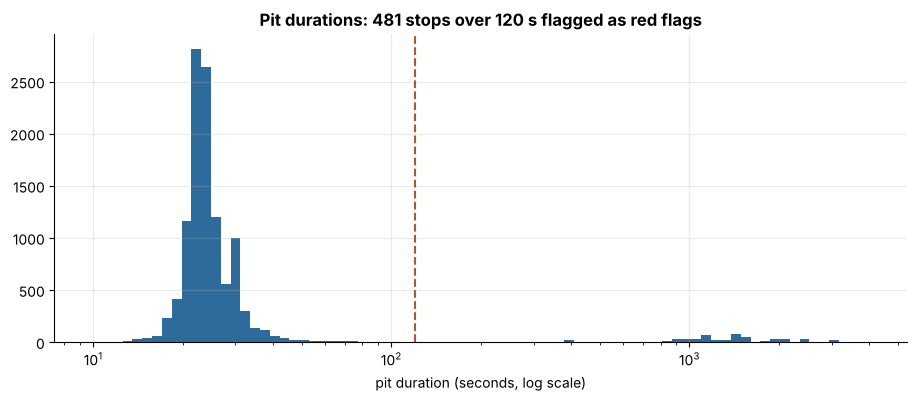

In [ ]:
ps = clean["pit_stops"]
ps["red_flag"] = ps.duration_s > 120

fig, ax = plt.subplots()
ax.hist(ps.duration_s, bins=np.logspace(1, 3.6, 80), color=AFTER); ax.set_xscale("log")
ax.axvline(120, ls="--", color=BEFORE); ax.set_xlabel("pit duration (seconds, log scale)")
ax.set_title(f"Pit durations: {ps.red_flag.sum()} stops over 120 s flagged as red flags"); plt.show()

**2- Qualifying times.** We compare each driver's best lap to the pole lap of the same session. Slow laps happen (rain, a car breaking down), but a lap many times slower than pole is impossible.

In [ ]:
q = clean["qualifying"]
q["best_s"] = q[["q1_s", "q2_s", "q3_s"]].min(axis=1)
q["vs_pole"] = q.best_s / q.groupby("raceId").best_s.transform("min")

fig, ax = plt.subplots()
ax.hist(q.vs_pole.clip(upper=1.6), bins=120, color=AFTER)
ax.axvline(1.07, ls="--", color=GREY); ax.set_xlabel("best lap ÷ pole lap (values above 1.6 shown at 1.6)")
ax.set_title("Qualifying laps compared to pole"); plt.show()

q[q.vs_pole > 1.3].merge(clean["races"][["raceId", "year", "name"]], on="raceId")[
    ["year", "name", "driverId", "q1", "q2", "q3", "vs_pole"]].sort_values("vs_pole", ascending=False).round(2)

NameError: name 'clean' is not defined

One lap is **10× slower than pole** (1995 Japan, `"16:42.640"`). That's a recording error (probably `1:42.640`), so we set it to missing. The other slow laps (1.3–1.5× pole) are real wet sessions and are kept.

In [ ]:
error = q.vs_pole > 2
q.loc[error, ["q1_s", "q2_s", "q3_s"]] = np.nan
q["time_error"] = error
q.drop(columns=["best_s", "vs_pole"], inplace=True)
print("qualifying times set to missing:", error.sum())

qualifying times set to missing: 1


### 1.3.9 Final checks

In [ ]:
R = clean["results"]
podium_positions = R[R.podium == 1].groupby("raceId").positionOrder.apply(set)
qt = clean["qualifying"][["q1_s", "q2_s", "q3_s"]]

final = pd.DataFrame({"passed": {
    "one row per driver per race": not R.duplicated(["raceId", "driverId"]).any(),
    "no \\N or empty strings left": all((d.astype(str).isin([r"\N", ""])).sum().sum() == 0 for d in clean.values()),
    "positionOrder never empty": R.positionOrder.notna().all(),
    "every race has positions 1, 2, 3 on the podium": (podium_positions == {1, 2, 3}).all() and len(podium_positions) == R.raceId.nunique(),
    "no podium for a driver who never started": R.loc[R.did_not_start, "podium"].sum() == 0,
    "qualifying times positive": ((qt > 0) | qt.isna()).all().all(),
    "all primary keys ok": pk.ok.all(),
    "all foreign keys ok": fk.ok.all(),
}})
final

,passed
one row per driver per race,True
no \N or empty strings left,True
positionOrder never empty,True
"every race has positions 1, 2, 3 on the podium",True
no podium for a driver who never started,True
qualifying times positive,True
all primary keys ok,True
all foreign keys ok,True


In [ ]:
# Some 1950s races have more than 3 podium rows. Why?
per_race = R[R.podium == 1].groupby("raceId").size()
example = R[(R.raceId == 792) & (R.podium == 1)][["raceId", "driverId", "constructorId", "positionOrder", "points"]]
print(f"{(per_race > 3).sum()} races have more than 3 podium rows. Example (1955):")
example

18 races have more than 3 podium rows. Example (1955):


,raceId,driverId,constructorId,positionOrder,points
19030,792,579,131,1,9.00
19031,792,498,6,2,2.00
20161,792,642,6,2,2.00
20162,792,427,6,2,2.00
20163,792,620,6,3,1.33


**Explanation:** in shared drives, all co-drivers of the car were credited with **the same position** (above: three drivers all at P2, splitting the points). That is the official result, so they all count as podiums. It is consistent with Rule A.

## 1.4 EDA after cleaning: before vs after

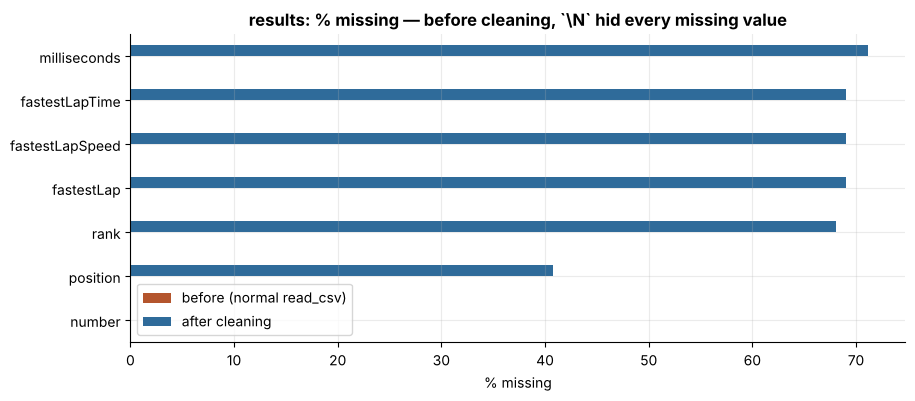

In [ ]:
# Missing values: hidden before (stored as text), visible after
cols = ["position", "milliseconds", "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "number"]
missing_compare = pd.DataFrame({"before (normal read_csv)": naive["results"][cols].isna().mean() * 100,
                        "after cleaning": clean["results"][cols].isna().mean() * 100}).sort_values("after cleaning")
missing_compare.plot(kind="barh", color=[BEFORE, AFTER], figsize=(10, 4))
plt.title("results: % missing — before cleaning, `\\N` hid every missing value"); plt.xlabel("% missing"); plt.show()

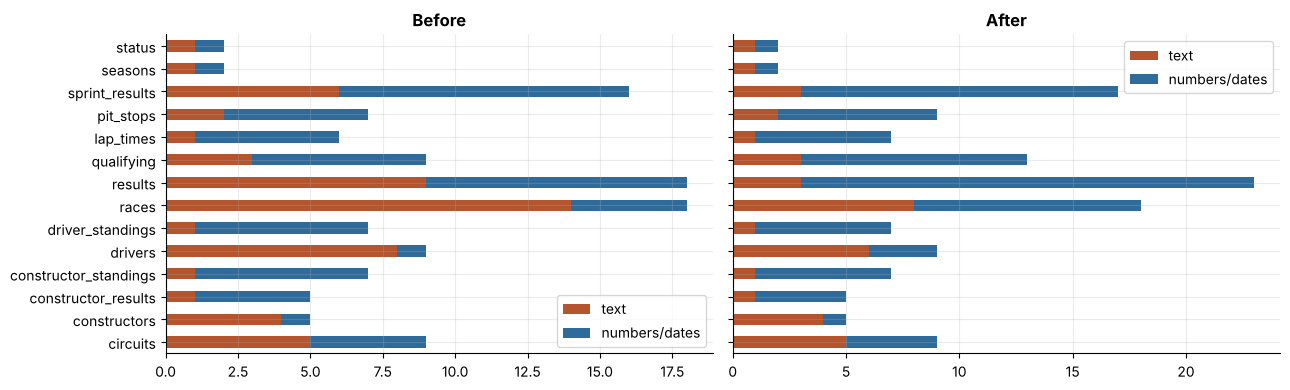

In [ ]:
# Column types: text vs typed (numbers / dates)
def type_counts(tables):
    return pd.DataFrame({t: {"text": len(text_columns(d)), "numbers/dates": d.shape[1] - len(text_columns(d))}
                         for t, d in tables.items() if t in TABLES}).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
type_counts(naive).plot(kind="barh", stacked=True, ax=axes[0], color=[BEFORE, AFTER], title="Before")
type_counts(clean).plot(kind="barh", stacked=True, ax=axes[1], color=[BEFORE, AFTER], title="After")
plt.tight_layout(); plt.show()

The text columns left after cleaning are real text: names, codes, URLs, `positionText` (letter codes) and the original time strings kept next to their new `_s` columns.

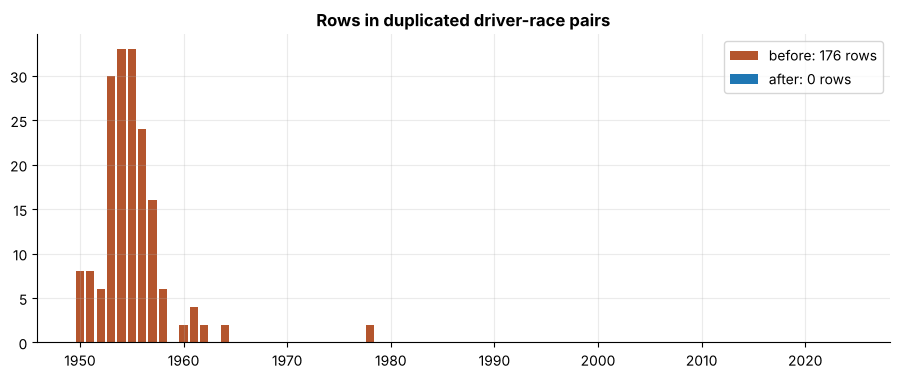

In [ ]:
# Duplicates per season: before vs after
after = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
dups_per_year_after = after[after.duplicated(["raceId", "driverId"], keep=False)].groupby("year").size()
fig, ax = plt.subplots()
ax.bar(dups_per_year_before.index, dups_per_year_before.values, color=BEFORE, label=f"before: {dups_per_year_before.sum()} rows")
ax.bar([], [], color=AFTER, label=f"after: {len(dups_per_year_after)} rows")
ax.set_title("Rows in duplicated driver-race pairs"); ax.legend(); plt.show()

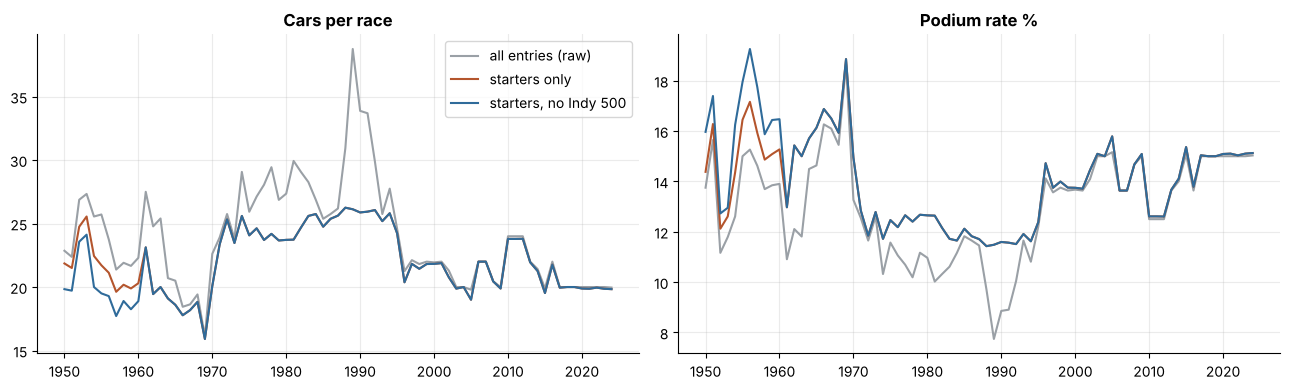

,rows,podium rate %
all entries (raw),26759,12.7
starters only,24967,13.6
"starters, no Indy 500",24586,13.7


In [ ]:
# Effect of the flags on field size and podium rate
views = {"all entries (raw)": res_raw.assign(podium=(res_raw.positionOrder <= 3).astype(int)),
         "starters only": after[~after.did_not_start],
         "starters, no Indy 500": after[~after.did_not_start & ~after.is_indy500]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (name, d), color in zip(views.items(), [GREY, BEFORE, AFTER]):
    axes[0].plot(d.groupby(["year", "raceId"]).size().groupby("year").mean(), color=color, label=name)
    axes[1].plot(d.groupby("year").podium.mean() * 100, color=color, label=name)
axes[0].set_title("Cars per race"); axes[1].set_title("Podium rate %"); axes[0].legend()
plt.tight_layout(); plt.show()

pd.DataFrame({"rows": {n: len(d) for n, d in views.items()},
              "podium rate %": {n: round(d.podium.mean() * 100, 1) for n, d in views.items()}})

**Effect:** removing non-starters takes the 1980s–90s fields from ~30–39 entries down to the real ~26 starters, and the podium rate moves closer to the true "3 of N starters".

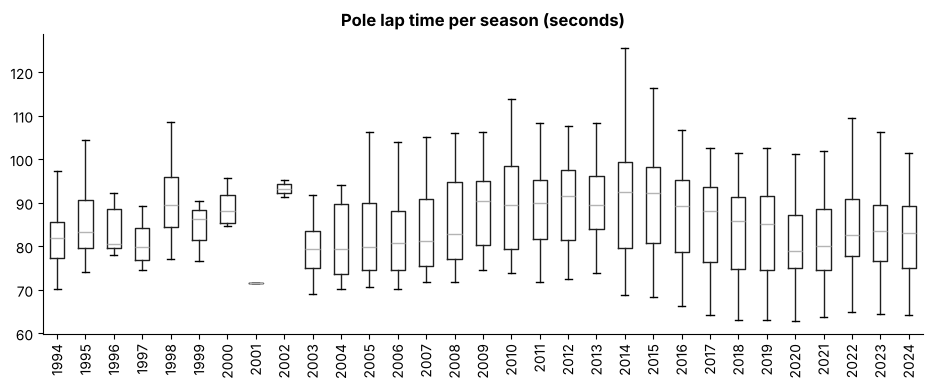

qualifying position ≠ grid position in 23.3% of starts (penalties) → they are two different features, which matters for Q1


In [ ]:
# Times are now numbers: pole lap per season
q = clean["qualifying"].merge(clean["races"][["raceId", "year"]], on="raceId")
pole = q.assign(best=q[["q1_s", "q2_s", "q3_s"]].min(axis=1)).groupby(["year", "raceId"]).best.min().reset_index()
pole.boxplot(column="best", by="year", rot=90, grid=False, showfliers=False, figsize=(11, 4))
plt.suptitle(""); plt.title("Pole lap time per season (seconds)"); plt.xlabel(""); plt.show()

qg = q.merge(clean["results"][["raceId", "driverId", "grid"]], on=["raceId", "driverId"])
qg = qg[qg.grid > 0]
print(f"qualifying position ≠ grid position in {(qg.position != qg.grid).mean():.1%} of starts (penalties) "
      "→ they are two different features, which matters for Q1")

## 1.5 Decision log

| # | Problem | Decision | Evidence |
|---|---|---|---|
| 1 | Raw files must stay untouched | load as text, clean a copy | §1.1 |
| 2 | `\N` and empty strings mean "missing" | → `NaN` | §1.2.1 |
| 3 | Numbers stored as text | convert only if *every* value is a number; `Int64` for whole numbers | §1.2.2, §1.3.1 |
| 4 | Times stored as text | one parser → seconds; matches milliseconds 100% | §1.2.3, §1.3.2 |
| 5 | `results.time` mixes total time and gaps | keep as `time_text`; use `milliseconds` | §1.3.2 |
| 6 | Spelling errors | only 3 real ones fixed: `United States→USA`, `Argentinian→Argentine`, `&amp;→&` | §1.2.8, §1.3.3 |
| 7 | Nationality ≠ country words | translation table, circuit country, dual → both | §1.3.4 |
| 8 | Keys | all primary and foreign keys pass | §1.3.5 |
| 9 | Same driver twice in one race (1950s shared drives) | keep his row with the best finishing position (Rule A); same labels as Rule B; other co-drivers untouched | §1.3.6 |
| 10 | Never-started entries (F/W) | flagged, decided at modeling | §1.2.6, §1.3.7 |
| 11 | `grid = 0` | mostly non-starters; real pit-lane starts flagged | §1.2.5, §1.3.7 |
| 12 | Indy 500 | flagged by circuit **and** year | §1.3.7 |
| 13 | Red-flag pit stops | flagged, kept | §1.3.8 |
| 14 | Impossible qualifying time (1) | set to missing | §1.3.8 |
| 15 | > 3 podium rows in 18 early races | kept: official shared positions | §1.3.9 |
| 16 | Qualifying coverage (4 periods) | input for the modeling window | §1.2.7 |

In [ ]:
for t, df in clean.items():
    df.to_pickle(f"{OUT_DIR}/{t}.pkl")      # pickle keeps the types (Int64, dates)

pd.DataFrame({"rows before": {t: len(raw[t]) for t in clean if t in raw},
              "rows after": {t: len(clean[t]) for t in clean if t in raw}}).query("`rows before` != `rows after`")

,rows before,rows after
results,26759,26668


Only `results` changed size (−91 duplicate rows). All other tables keep every row, we only edited types and added flags. Clean tables are saved for the next part (feature engineering).

# Part 2: Data-Engineering Questions

Uses the `clean` tables from Part 1 above.

For each question:
1. **Joins:** which tables we combine, and why one table isn't enough.
2. **Definitions:** each choice, with the reason for it.
3. **Answer:** a table and a plot.
4. **Robustness check:** does the answer survive a different reasonable choice?
5. **Grain, missingness, pre-race cutoff:** short notes, as the brief requires.


In [ ]:
# `clean` comes from Part 1 (cleaning) earlier in this notebook - no reloading needed

# rows used by all questions: drivers who actually STARTED a race (Part 1, flag did_not_start),
# without the 1950-60 Indy 500 (separate race with its own field of drivers)
starts = (clean["results"][~clean["results"].did_not_start & ~clean["results"].is_indy500]
          .merge(clean["races"][["raceId", "year", "circuitId"]], on="raceId", validate="many_to_one"))
print("race starts:", len(starts), "| races:", starts.raceId.nunique(), "| seasons:", starts.year.min(), "-", starts.year.max())

race starts: 24586 | races: 1114 | seasons: 1950 - 2024


**Why starters only?** A driver who never started (failed to qualify or withdrew) can't have a front row, a home podium or a mechanical failure *during* the race. Keeping them would add zeros that aren't real outcomes.

**Why drop the Indy 500?** In 1950–60 it counted for the championship, but it was a separate race, run almost entirely by American drivers who never raced other Grands Prix. It would distort the circuit and home-race statistics.

---
## Q1. Which circuits turn a front-row start into a podium most often, and did that change after 2014?

### Joins
| Table | Gives us |
|---|---|
| `results` | grid position, finishing position (podium) |
| `races` | year and circuit of each race |
| `circuits` | circuit name |
| `qualifying` | qualifying position (before penalties) |

`results` alone doesn't know the circuit name or the qualifying position, so we need 3 hops.

### Definitions
* **Front row, two versions** :
  * **by grid**: the driver actually *started* in P1 or P2 (after penalties).
  * **by qualifying**: the driver *qualified* P1 or P2 (before penalties).
* **Conversion rate** = podiums ÷ front-row starters. A front-row starter who crashed out counts as "no podium"; that's part of conversion.
* **Periods:** **2003–2013** (before the hybrid era) vs **2014–2024** (hybrid era and after).
  * Why start at 2003? Qualifying data is complete only from 2003 (§1.2.7). Starting earlier would make the "by qualifying" version use a different set of races than the "by grid" version.
  * Bonus: both periods are 11 seasons long, so neither has a sample-size advantage.
* **Minimum sample:** a circuit needs **≥ 10 front-row starts in a period** (≈ 5 races). A circuit with 2 races and 4/4 podiums would otherwise top the ranking by luck.

In [ ]:
q1 = (starts.merge(clean["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId")
            .merge(clean["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
                   on=["raceId", "driverId"], how="left", validate="one_to_one"))
q1 = q1[q1.year.between(2003, 2024)].copy()
q1["period"] = np.where(q1.year <= 2013, "2003–2013", "2014–2024")
q1["front_row_grid"] = q1.grid.isin([1, 2])
q1["front_row_quali"] = q1.quali_pos.isin([1, 2])

print("missing qualifying position in 2003–2024 starts:", q1.quali_pos.isna().sum(), "of", len(q1))

missing qualifying position in 2003–2024 starts: 21 of 8910


**Overall first:** how often does a front-row start become a podium?

In [ ]:
q1_overall = []
for period, d in q1.groupby("period"):
    for version, col in [("by grid", "front_row_grid"), ("by qualifying", "front_row_quali")]:
        fr = d[d[col]]
        q1_overall.append({"period": period, "front row": version, "front-row starts": len(fr),
                        "podiums": fr.podium.sum(), "conversion %": round(100 * fr.podium.mean(), 1)})
pd.DataFrame(q1_overall)

,period,front row,front-row starts,podiums,conversion %
0,2003–2013,by grid,398,272,68.3
1,2003–2013,by qualifying,398,269,67.6
2,2014–2024,by grid,453,345,76.2
3,2014–2024,by qualifying,454,336,74.0


In [ ]:
# How different are the two definitions? Cases where qualifying and grid disagree (penalties / pit-lane starts)
moved_back = q1[q1.front_row_quali & ~q1.front_row_grid]
moved_up = q1[q1.front_row_grid & ~q1.front_row_quali]
pd.DataFrame({
    "rows": [len(moved_back), len(moved_up)],
    "podium %": [round(100 * moved_back.podium.mean(), 1), round(100 * moved_up.podium.mean(), 1)],
    "avg grid": [round(moved_back.grid.mean(), 1), round(moved_up.grid.mean(), 1)],
}, index=["qualified front row, but started further back (penalty)", "started front row, but didn't qualify there (others penalised)"])

,rows,podium %,avg grid
"qualified front row, but started further back (penalty)",37,29.7,8.6
"started front row, but didn't qualify there (others penalised)",36,63.9,1.9


**Why the distinction matters:** a driver who qualified on the front row but got a grid penalty starts further back and podiums much less often. The "by grid" version measures where they *started*; the "by qualifying" version measures their *pace*, including races ruined by penalties.

### Per-circuit conversion

In [ ]:
MIN_FRONT_ROW_STARTS = 10

def conversion_by_circuit(df, col):
    fr = df[df[col]]
    t = fr.groupby(["period", "circuit"]).podium.agg(podiums="sum", starts="size").reset_index()
    t["rate %"] = 100 * t.podiums / t.starts
    low, high = proportion_confint(t.podiums, t.starts, method="wilson")      # 95% interval, reliable for small n
    t["95% CI"] = [f"{100*l:.0f}–{100*h:.0f}" for l, h in zip(low, high)]
    return t[t.starts >= MIN_FRONT_ROW_STARTS]

by_grid = conversion_by_circuit(q1, "front_row_grid")
by_quali = conversion_by_circuit(q1, "front_row_quali")

# Top 5 circuits for BOTH definitions of "front row" and both periods: rate % [95% interval]
top5 = {}
for version, t in [("by grid", by_grid), ("by qualifying", by_quali)]:
    for period in ["2003–2013", "2014–2024"]:
        best = t[t.period == period].sort_values("rate %", ascending=False).head(5)
        top5[f"{version}, {period}"] = [f"{c} {r:.0f}% [{ci}]" for c, r, ci in zip(best.circuit, best["rate %"], best["95% CI"])]
pd.DataFrame(top5, index=pd.Index(range(1, 6), name="rank"))

,"by grid, 2003–2013","by grid, 2014–2024","by qualifying, 2003–2013","by qualifying, 2014–2024"
rank,,,,
1,Circuit de Nevers Magny-Cours 92% [65–99],Circuit de Monaco 89% [69–97],Circuit de Nevers Magny-Cours 92% [65–99],Circuit de Monaco 89% [69–97]
2,Istanbul Park 79% [52–92],Suzuka Circuit 89% [67–97],Istanbul Park 79% [52–92],Suzuka Circuit 89% [67–97]
3,Autodromo Nazionale di Monza 77% [57–90],Yas Marina Circuit 86% [67–95],Silverstone Circuit 77% [57–90],Circuit de Spa-Francorchamps 82% [61–93]
4,Circuit de Monaco 77% [57–90],Circuit de Spa-Francorchamps 82% [61–93],Autodromo Nazionale di Monza 73% [52–87],Yas Marina Circuit 82% [61–93]
5,Silverstone Circuit 73% [52–87],Circuit de Barcelona-Catalunya 82% [61–93],Suzuka Circuit 72% [49–88],Circuit de Barcelona-Catalunya 82% [61–93]


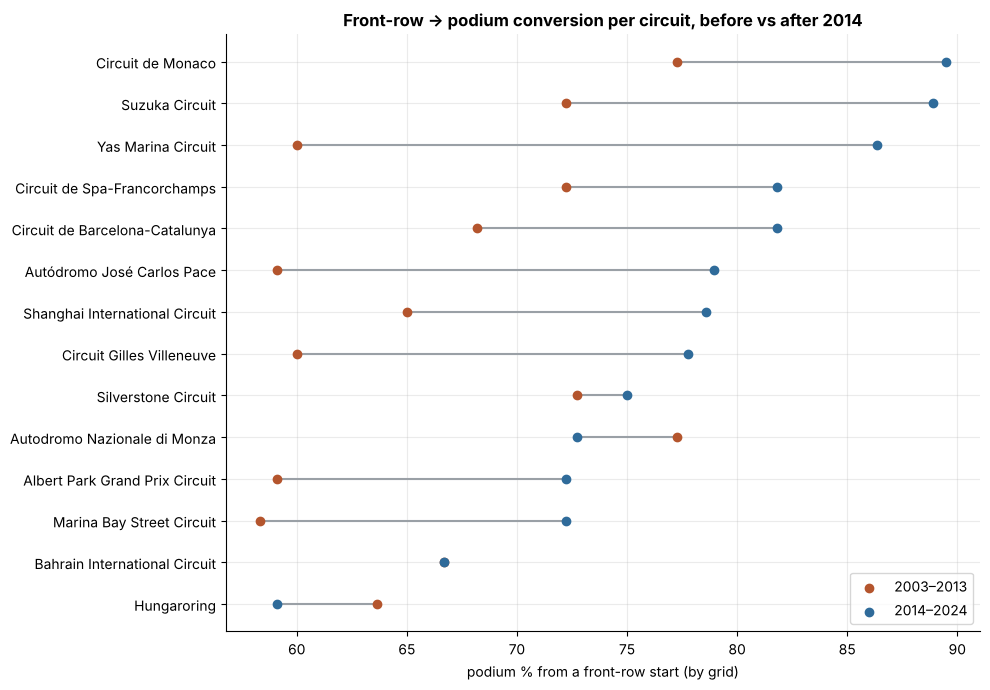

circuits shown (≥ 10 front-row starts in both periods): 14


In [ ]:
# Plot: conversion by grid front row, both periods, circuits present in BOTH periods
wide = by_grid.pivot(index="circuit", columns="period", values="rate %").dropna().sort_values("2014–2024")
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(wide))
ax.hlines(y, wide["2003–2013"], wide["2014–2024"], color=GREY, lw=1.5)
ax.scatter(wide["2003–2013"], y, color=BEFORE, label="2003–2013", zorder=3)
ax.scatter(wide["2014–2024"], y, color=AFTER, label="2014–2024", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(wide.index)
ax.set_xlabel("podium % from a front-row start (by grid)")
ax.set_title("Front-row → podium conversion per circuit, before vs after 2014"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"circuits shown (≥ {MIN_FRONT_ROW_STARTS} front-row starts in both periods):", len(wide))

### Did the ranking change after 2014?
We compare the two periods' rankings with the **Spearman rank correlation** (1 = same order, 0 = no relation, negative = flipped).

**But a correlation alone can mislead here.** Each circuit has only 12–22 front-row starts per period, so every rate is noisy, and even a ranking that did *not* change would not give 1. The cell therefore simulates two reference worlds with the **real number of starts per circuit**:
* **"nothing changed":** both periods are drawn from the same pooled starts of each circuit;
* **"fully reshuffled":** the 2014–24 rates are randomly re-assigned to the circuits.

If the observed correlation fits inside both ranges, the data cannot tell the two worlds apart.

In [ ]:
def rho_by_chance(df, col, n_resamples=2000):
    # What rank correlation would chance alone produce, with the real number of front-row starts per circuit?
    #   "nothing changed":  both periods drawn from the SAME pooled starts of each circuit (true rates identical)
    #   "fully reshuffled": the 2014-24 rates randomly re-assigned to the circuits (no relation at all)
    cells = {k: g.podium.values for k, g in df[df[col]].groupby(["period", "circuit"])}
    ok = {k for k, v in cells.items() if len(v) >= MIN_FRONT_ROW_STARTS}
    circuits = sorted(c for p, c in ok if p == "2003–2013" and ("2014–2024", c) in ok)
    before = pd.Series([cells[("2003–2013", c)].mean() for c in circuits])
    after = pd.Series([cells[("2014–2024", c)].mean() for c in circuits])
    pooled = {c: np.concatenate([cells[("2003–2013", c)], cells[("2014–2024", c)]]) for c in circuits}
    rng = np.random.default_rng(SEED)
    unchanged, reshuffled = [], []
    for _ in range(n_resamples):
        a = pd.Series([rng.choice(pooled[c], len(cells[("2003–2013", c)])).mean() for c in circuits])
        b = pd.Series([rng.choice(pooled[c], len(cells[("2014–2024", c)])).mean() for c in circuits])
        unchanged.append(a.corr(b, method="spearman"))
        reshuffled.append(before.corr(pd.Series(rng.permutation(after.values)), method="spearman"))
    return np.nanpercentile(unchanged, [2.5, 50, 97.5]), np.nanpercentile(reshuffled, [2.5, 97.5])

rho_rows = []
for version, t, col in [("by grid", by_grid, "front_row_grid"), ("by qualifying", by_quali, "front_row_quali")]:
    w = t.pivot(index="circuit", columns="period", values="rate %").dropna()
    rho = w["2003–2013"].corr(w["2014–2024"], method="spearman")
    (u_low, u_mid, u_high), (s_low, s_high) = rho_by_chance(q1, col)
    top_before, top_after = w["2003–2013"].nlargest(5).index, w["2014–2024"].nlargest(5).index
    rho_rows.append({"front row": version, "circuits in both": len(w), "rank correlation": round(rho, 2),
                     "if nothing changed: typical [95% range]": f"{u_mid:.2f} [{u_low:.2f} to {u_high:.2f}]",
                     "if fully reshuffled: 95% range": f"{s_low:.2f} to {s_high:.2f}",
                     "top-5 kept": len(set(top_before) & set(top_after)),
                     "top 5 (2003–13)": ", ".join(top_before), "top 5 (2014–24)": ", ".join(top_after)})
pd.DataFrame(rho_rows).set_index("front row").T

front row,by grid,by qualifying
circuits in both,14,14
rank correlation,0.36,0.54
if nothing changed: typical [95% range],0.29 [-0.21 to 0.73],0.28 [-0.23 to 0.73]
if fully reshuffled: 95% range,-0.53 to 0.55,-0.54 to 0.56
top-5 kept,3,2
top 5 (2003–13),"Autodromo Nazionale di Monza, Circuit de Monac...","Silverstone Circuit, Autodromo Nazionale di Mo..."
top 5 (2014–24),"Circuit de Monaco, Suzuka Circuit, Yas Marina ...","Circuit de Monaco, Suzuka Circuit, Circuit de ..."


In [ ]:
# Robustness: does the answer depend on the minimum-sample cutoff?
cutoff_rows = []
for m in [6, 10, 16]:
    fr = q1[q1.front_row_grid].groupby(["period", "circuit"]).podium.agg(["sum", "size"]).reset_index()
    fr = fr[fr["size"] >= m]
    fr["rate"] = fr["sum"] / fr["size"]
    w = fr.pivot(index="circuit", columns="period", values="rate").dropna()
    cutoff_rows.append({"min front-row starts": m, "circuits": len(w),
                "rank correlation": round(w["2003–2013"].corr(w["2014–2024"], method="spearman"), 2)})
pd.DataFrame(cutoff_rows).set_index("min front-row starts")

,circuits,rank correlation
min front-row starts,,
6,17,0.22
10,14,0.36
16,11,0.40


### Q1 answer
* **Front-row starts convert more often since 2014:** 68% → 76% by grid, and 68% → 74% by qualifying. One car dominated most seasons (Mercedes, then Red Bull), so its front-row starts rarely failed.
* **Best circuits 2014–2024:** Monaco 89% [69–97] and Suzuka 89% [67–97], then Yas Marina, Spa and Barcelona (82–86%). The **qualifying** definition gives the same five. Monaco fits: overtaking is nearly impossible, so the start decides the race.
* **Best circuits 2003–2013:** Magny-Cours 92% [65–99] and Istanbul 79%, then Monza, Monaco and Silverstone by grid (Silverstone, Monza and Suzuka by qualifying). Magny-Cours and Istanbul are not on the calendar after 2013.
* **Did the ranking change? The data cannot tell.**
  * The rank correlation between the periods is 0.36 by grid and 0.54 by qualifying (14 circuits).
  * If **nothing** had changed, noise alone would typically give **0.29** (95% range −0.21 to 0.73). If the ranking had been **completely reshuffled**, it would give −0.53 to 0.55.
  * Both observed values fit both worlds. So we can claim neither "the ranking changed" nor "it stayed the same": **this data has no stable circuit ranking.** The cutoff check (0.22–0.40 for minimum samples of 6–16) agrees.
  * Per circuit, the 95% intervals are 30+ points wide, so gaps of a few points between circuits mean nothing.
* **Grid vs qualifying:**
  * 37 drivers qualified P1/P2 but started further back after a penalty; they podiumed only **30%** of the time, against ~70% for real front-row starters.
  * The two definitions share 4 of their top 5 circuits before 2014 and all 5 after, so they agree on the leaders. Grid is the better pre-race signal for where a driver actually starts; qualifying adds information about pure pace.

**Grain:** one row per driver start. **Missingness:** qualifying is complete from 2003, which is why the window starts there. **Pre-race cutoff:** grid and qualifying position are both known before the start; the podium is the outcome.

---
## Q2. Do drivers podium more often at home, once we compare drivers who started from similar positions?

### Joins
| Table | Gives us |
|---|---|
| `results` | grid, podium |
| `races` → `circuits` | the **country** where the race was held |
| `drivers` | nationality |
| `nationality_country` (built in §1.3.4) | translates "British" → "UK", etc. |

Home race = the circuit's country is one of the driver's countries. We always use the circuit's country, never the race name (the 1982 "Swiss GP" was in France).

### Why we must control for starting position
If home drivers simply qualify better (or worse), a raw comparison would show a "home effect" that is really a grid effect. So we compare home vs away **within the same group of grid positions**.

**Grid groups:** 1–3, 4–6, 7–10, 11+ (pit-lane starts go into 11+). Within each group the podium chance is fairly similar, and each group still has enough home starts (100+).

In [ ]:
q2 = (starts.merge(clean["circuits"][["circuitId", "country"]], on="circuitId")
            .merge(clean["drivers"][["driverId", "nationality"]], on="driverId"))
home_pairs = q2.merge(clean["nationality_country"][["nationality", "country"]], on=["nationality", "country"])
q2["home"] = q2.set_index(["raceId", "driverId"]).index.isin(home_pairs.set_index(["raceId", "driverId"]).index)
q2["grid group"] = pd.cut(q2.grid.replace(0, 99), bins=[0, 3, 6, 10, 999], labels=["1–3", "4–6", "7–10", "11+"])

print("home starts:", q2.home.sum(), "| away starts:", (~q2.home).sum())

home starts: 1932 | away starts: 22654


**Step 1: the raw comparison (no control).**

In [ ]:
raw_cmp = q2.groupby("home").agg(starts=("podium", "size"), podium_pct=("podium", "mean"), avg_grid=("grid", "mean"))
raw_cmp["podium_pct"] = (100 * raw_cmp.podium_pct).round(1)
raw_cmp.index = raw_cmp.index.map({True: "home", False: "away"})
raw_cmp.round(1)

,starts,podium_pct,avg_grid
home,,,
away,22654,13.8,11.6
home,1932,11.9,12.7


Raw, home drivers podium **less** often. But they also start further back on average. Many home starts are local drivers in slower cars (especially in older eras, when local one-off entries were common). That's exactly the confounding the brief warns about, so we control for grid.

**Step 2: compare within grid groups.**

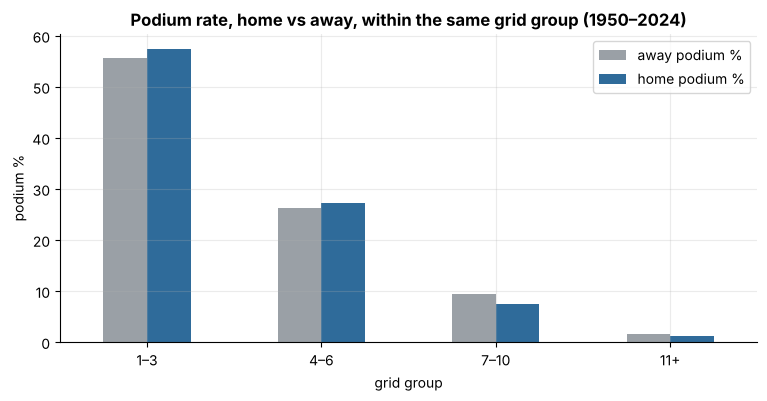

,away starts,home starts,away podium %,home podium %,difference (home − away)
grid group,,,,,
1–3,3095,228,55.7,57.5,1.7
4–6,3102,224,26.2,27.2,1.1
7–10,4101,336,9.4,7.4,-1.9
11+,12356,1144,1.7,1.1,-0.5


In [ ]:
within = q2.groupby(["grid group", "home"], observed=True).podium.agg(["mean", "size"]).unstack()
within.columns = [f"{'home' if h else 'away'} {m}" for m, h in within.columns]
within = within.rename(columns={"away mean": "away podium %", "home mean": "home podium %",
                                "away size": "away starts", "home size": "home starts"})
within["away podium %"] *= 100; within["home podium %"] *= 100
within["difference (home − away)"] = within["home podium %"] - within["away podium %"]

ax = within[["away podium %", "home podium %"]].plot(kind="bar", color=[GREY, AFTER], rot=0, figsize=(9, 4))
ax.set_ylabel("podium %"); ax.set_title("Podium rate, home vs away, within the same grid group (1950–2024)")
plt.show()
within[["away starts", "home starts", "away podium %", "home podium %", "difference (home − away)"]].round(1)

**Step 3: one number for "home effect".** We combine the four grid groups with the **Mantel–Haenszel odds ratio**, a standard way to merge the comparison across groups. It compares home vs away inside each grid group, then averages.
* **1.0** = no home effect;
* **> 1** = home helps;
* **< 1** = home hurts.

We run it on all seasons and on 2003+ (modern era, 20-car fields).

In [ ]:
def home_effect(d):
    tables = [pd.crosstab(g.home, g.podium).reindex(index=[True, False], columns=[1, 0], fill_value=0).values
              for _, g in d.groupby("grid group", observed=True)]
    st = StratifiedTable(tables)
    low, high = st.oddsratio_pooled_confint()
    return {"home starts": int(d.home.sum()), "odds ratio": round(st.oddsratio_pooled, 2),
            "95% CI": f"{low:.2f}–{high:.2f}", "p-value": round(st.test_null_odds().pvalue, 3)}

pd.DataFrame({"1950–2024": home_effect(q2), "1950–2002": home_effect(q2[q2.year < 2003]),
              "2003–2024": home_effect(q2[q2.year >= 2003])}).T

,home starts,odds ratio,95% CI,p-value
1950–2024,1932,0.96,0.81–1.14,0.617
1950–2002,1568,0.97,0.80–1.18,0.778
2003–2024,364,0.83,0.57–1.23,0.357


### Q2 answer
* **No measurable home advantage** once starting position is accounted for.
  * Pooled odds ratio **0.96**, with a 95% interval of 0.81–1.14 that includes 1.0 (p = 0.62).
  * Same result in the old era (0.97) and the modern era (0.83, interval 0.57–1.23). Neither is significant.
* **The raw numbers mislead:**
  * Overall, home drivers podium *less* (11.9% vs 13.8%), because they start further back (average grid 12.7 vs 11.6).
  * Within the same grid group the difference is only −1.9 to +1.7 points, with no consistent direction.
* **For the model:** a "home race" feature is unlikely to add much. We can still confirm this in the ablation.

**Grain:** one row per driver start; a dual-nationality driver is "home" if the race is in either country. **Missingness:** none. Grid and nationality are filled for every start. Drivers from countries that never hosted a race are always "away", which is correct. **Pre-race cutoff:** home status and grid are known before the start.

---
## Q3. Which constructors had the highest mechanical-retirement rate, 2014–2021 vs 2022–2024?

### Joins
| Table | Gives us |
|---|---|
| `results` | who started, with which constructor, and the `statusId` |
| `status` | *why* the race ended ("Engine", "Collision", …) |
| `constructors` | team name |
| `races` | the year (for the periods) |

### Definitions
* **Denominator = race starts.** Mechanical retirement is defined as "a race start that ended early".
  * Cars that broke **before** the start (`positionText = W`, 22 cases in 2014–24) are not starts, so they're excluded.
  * Sprint races are not included; only Grand Prix results.
* **Mechanical** = a car component failed. **Not mechanical:** crashes, driver errors, regulation decisions (disqualified, excluded) and driver illness.
* The 66 different statuses that occur in 2014–2024 starts are sorted into 4 groups below. Every label is listed, so the mapping can be checked.


In [ ]:
MECHANICAL = {"Engine", "Gearbox", "Power Unit", "Brakes", "Suspension", "Hydraulics", "Electrical", "Power loss",
              "Oil leak", "Overheating", "Mechanical", "Water pressure", "Turbo", "ERS", "Exhaust", "Battery",
              "Fuel pressure", "Water leak", "Electronics", "Transmission", "Radiator", "Oil pressure", "Technical",
              "Clutch", "Throttle", "Vibrations", "Driveshaft", "Steering", "Fuel leak", "Drivetrain", "Fuel system",
              "Brake duct", "Spark plugs", "Cooling system", "Water pump", "Fuel pump", "Differential", "Seat", "Undertray"}
NOT_MECHANICAL = {"Collision", "Collision damage", "Accident", "Spun off", "Disqualified", "Excluded", "Illness",
                  "Withdrew"}   # withdrawn by the team mid-race (3 starts): a decision, not a failure
# no clear cause: a failure OR contact / debris / a pit-stop error (wheel nut = pit crew) / strategy (fuel)
UNCLEAR = {"Retired", "Out of fuel", "Damage", "Debris", "Puncture", "Tyre", "Wheel", "Wheel nut", "Front wing", "Rear wing"}

def status_group(s):
    if s == "Finished" or re.fullmatch(r"\+\d+ Laps?", s):
        return "finished"
    if s in MECHANICAL: return "mechanical"
    if s in NOT_MECHANICAL: return "not mechanical"
    if s in UNCLEAR: return "unclear"
    return "UNMAPPED"

q3 = (starts[starts.year.between(2014, 2024)]
      .merge(clean["status"], on="statusId").merge(clean["constructors"][["constructorId", "name"]], on="constructorId"))
q3["group"] = q3.status.map(status_group)
assert (q3.group != "UNMAPPED").all(), q3.loc[q3.group == "UNMAPPED", "status"].unique()

mapping = (q3.groupby("group").status.value_counts().rename("starts").reset_index()
             .groupby("group").apply(lambda g: ", ".join(f"{s} ({n})" for s, n in zip(g.status, g.starts)), include_groups=False))
pd.DataFrame({"starts": q3.group.value_counts(), "statuses (count)": mapping})

,starts,statuses (count)
group,,
finished,3825,"Finished (2403), +1 Lap (1178), +2 Laps (208),..."
mechanical,367,"Engine (79), Brakes (48), Gearbox (40), Power ..."
not mechanical,322,"Collision (150), Accident (85), Collision dama..."
unclear,84,"Retired (49), Wheel (11), Puncture (7), Tyre (..."


**Why some statuses are "unclear":**
* **`Retired` (49)** gives no reason at all.
* **`Out of fuel`** is usually a strategy or fuel-calculation error.
* **`Puncture`, `Tyre`, `Wheel`, `Front wing`, `Rear wing`, `Damage`, `Debris`** often come from contact or debris on track, not from a part failing on its own.
* **`Wheel nut`** is usually a pit-stop error by the crew.

**Main answer:** unclear = **not mechanical**, the strict reading of "a component of the car failed". The robustness check below counts all of them as mechanical (the broad reading), so both readings are shown.

**Team identity:** several teams changed name in this period while keeping the same factory and staff:
* Toro Rosso → AlphaTauri → RB;
* Force India → Racing Point → Aston Martin;
* Lotus F1 → Renault → Alpine;
* Sauber → Alfa Romeo → Sauber;
* Marussia → Manor.

We count each of these as **one team**. Otherwise 2022–24 would split into fragments of 48 starts (e.g. "RB F1 Team", 2024 only), too small for a stable rate, and the two periods couldn't be compared team by team. The label shows every name the team used. Part 3 reuses this mapping for the team-form features.

In [ ]:
LINEAGE = {"Toro Rosso": "Toro Rosso / AlphaTauri / RB", "AlphaTauri": "Toro Rosso / AlphaTauri / RB",
           "RB F1 Team": "Toro Rosso / AlphaTauri / RB",
           "Force India": "Force India / Racing Point / Aston Martin", "Racing Point": "Force India / Racing Point / Aston Martin",
           "Aston Martin": "Force India / Racing Point / Aston Martin",
           "Lotus F1": "Lotus F1 / Renault / Alpine", "Renault": "Lotus F1 / Renault / Alpine",
           "Alpine F1 Team": "Lotus F1 / Renault / Alpine",
           "Sauber": "Sauber / Alfa Romeo", "Alfa Romeo": "Sauber / Alfa Romeo",
           "Marussia": "Marussia / Manor", "Manor Marussia": "Marussia / Manor"}
q3["team"] = q3.name.replace(LINEAGE)
q3["period"] = np.where(q3.year <= 2021, "2014–2021", "2022–2024")

def mech_rates(d, count_unclear_as_mechanical=False):
    mech_groups = ["mechanical", "unclear"] if count_unclear_as_mechanical else ["mechanical"]
    t = d.groupby(["period", "team"]).agg(starts=("group", "size"),
                                          mechanical=("group", lambda g: g.isin(mech_groups).sum())).reset_index()
    t["rate %"] = 100 * t.mechanical / t.starts
    low, high = proportion_confint(t.mechanical, t.starts, method="wilson")    # 95% interval, as in Q1
    t["low %"], t["high %"] = 100 * low, 100 * high
    return t

MIN_TEAM_STARTS = 40   # ≈ 1 season of 2 cars; below this one or two failures swing the rate by several points
rates = mech_rates(q3)
print("teams below the minimum (excluded from the ranking):")
print(rates[rates.starts < MIN_TEAM_STARTS][["period", "team", "starts", "mechanical"]].to_string(index=False))
rates = rates[rates.starts >= MIN_TEAM_STARTS]

teams below the minimum (excluded from the ranking):
   period     team  starts  mechanical
2014–2021 Caterham      33           7


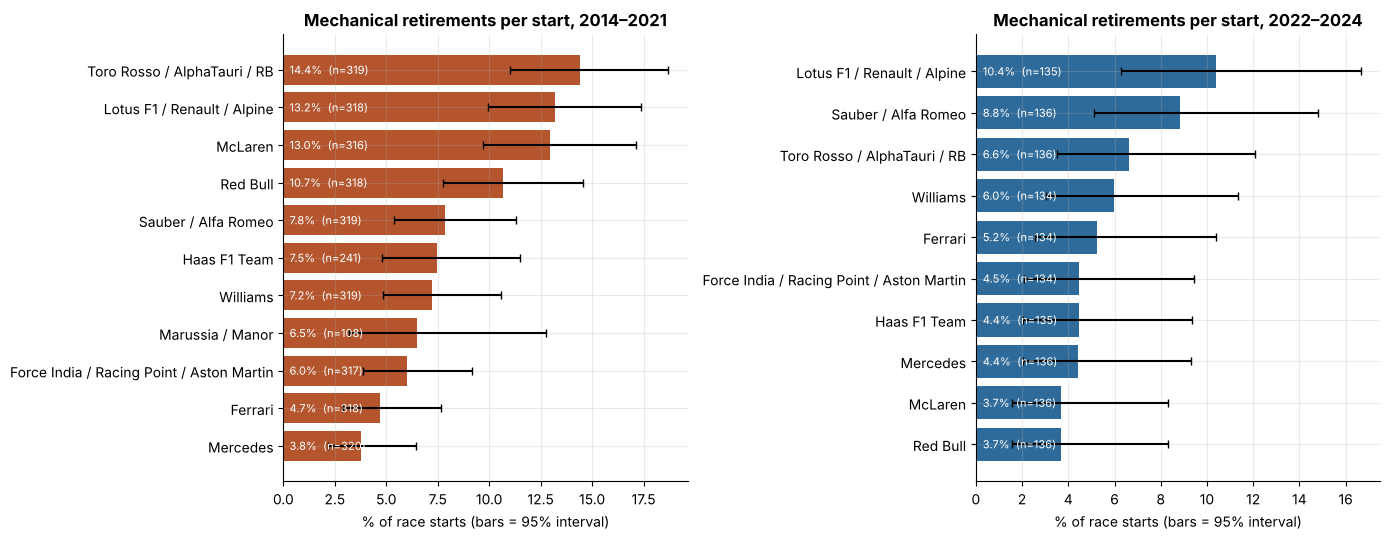

,2014–2021 rate %,2014–2021 95% CI,2022–2024 rate %,2022–2024 95% CI,change
Toro Rosso / AlphaTauri / RB,14.4,11.0–18.7,6.6,3.5–12.1,-7.8
Lotus F1 / Renault / Alpine,13.2,9.9–17.4,10.4,6.3–16.7,-2.8
McLaren,13.0,9.7–17.1,3.7,1.6–8.3,-9.3
Red Bull,10.7,7.8–14.6,3.7,1.6–8.3,-7.0
Sauber / Alfa Romeo,7.8,5.4–11.3,8.8,5.1–14.8,1.0
Haas F1 Team,7.5,4.8–11.5,4.4,2.1–9.4,-3.1
Williams,7.2,4.9–10.6,6.0,3.1–11.3,-1.2
Marussia / Manor,6.5,3.2–12.8,NaN,NaN,NaN
Force India / Racing Point / Aston Martin,6.0,3.9–9.2,4.5,2.1–9.4,-1.5
Ferrari,4.7,2.9–7.6,5.2,2.6–10.4,0.5


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (period, d), color in zip(axes, rates.groupby("period"), [BEFORE, AFTER]):
    d = d.sort_values("rate %")
    ax.barh(d.team, d["rate %"], xerr=[d["rate %"] - d["low %"], d["high %"] - d["rate %"]], color=color, capsize=3)
    for y, (r, n) in enumerate(zip(d["rate %"], d.starts)):
        ax.text(0.3, y, f"{r:.1f}%  (n={n})", va="center", fontsize=8, color="white")
    ax.set_title(f"Mechanical retirements per start, {period}"); ax.set_xlabel("% of race starts (bars = 95% interval)")
plt.tight_layout(); plt.show()

ranking = pd.DataFrame(index=sorted(rates.team.unique()))
for period in ["2014–2021", "2022–2024"]:
    p = rates[rates.period == period].set_index("team")
    ranking[f"{period} rate %"] = p["rate %"].round(1)
    ranking[f"{period} 95% CI"] = pd.Series([f"{l:.1f}–{h:.1f}" for l, h in zip(p["low %"], p["high %"])], index=p.index)
ranking["change"] = (ranking["2022–2024 rate %"] - ranking["2014–2021 rate %"]).round(1)
ranking.sort_values("2014–2021 rate %", ascending=False)

**Robustness check:** count the unclear statuses as mechanical and see whether the ranking survives.

In [ ]:
loose = mech_rates(q3, count_unclear_as_mechanical=True)
loose = loose[loose.starts >= MIN_TEAM_STARTS]
strict_vs_loose = []
for period in ["2014–2021", "2022–2024"]:
    a = rates[rates.period == period].set_index("team")["rate %"]
    b = loose[loose.period == period].set_index("team")["rate %"]
    strict_vs_loose.append({"period": period, "rank correlation (strict vs loose)": round(a.corr(b, method="spearman"), 2),
                "highest (strict)": a.idxmax(), "highest (loose)": b.idxmax(),
                "lowest (strict)": a.idxmin(), "lowest (loose)": b.idxmin()})
pd.DataFrame(strict_vs_loose).set_index("period")

,rank correlation (strict vs loose),highest (strict),highest (loose),lowest (strict),lowest (loose)
period,,,,,
2014–2021,0.96,Toro Rosso / AlphaTauri / RB,Lotus F1 / Renault / Alpine,Mercedes,Mercedes
2022–2024,0.99,Lotus F1 / Renault / Alpine,Lotus F1 / Renault / Alpine,McLaren,McLaren


In [ ]:
# Overall reliability per period (all teams together)
q3_overall = q3.groupby("period").group.value_counts(normalize=True).unstack().mul(100).round(1)
q3_overall[["finished", "mechanical", "not mechanical", "unclear"]]

group,finished,mechanical,not mechanical,unclear
period,,,,
2014–2021,81.9,8.9,7.0,2.2
2022–2024,86.2,5.8,7.0,1.0


### Q3 answer
* **2014–2021, highest mechanical-retirement rate** (95% interval in brackets):
  * **Toro Rosso / AlphaTauri** 14.4% [11.0–18.7];
  * **Lotus / Renault / Alpine** 13.2% [9.9–17.4];
  * **McLaren** 13.0% [9.7–17.1] (the unreliable McLaren-Honda years, 2015–17).

  These three are **tied**: their intervals overlap almost completely. What is clear is the gap to the most reliable teams, **Mercedes** 3.8% [2.2–6.4] and **Ferrari** 4.7% [2.9–7.6]. Caterham (2014 only, 33 starts) is below the minimum sample.
* **2022–2024, highest rate:** **Alpine** 10.4% [6.3–16.7], **Sauber / Alfa Romeo** 8.8% [5.1–14.8], **AlphaTauri / RB** 6.6%. Lowest: **McLaren** and **Red Bull**, 3.7% [1.6–8.3]. With only ~135 starts per team, the intervals overlap heavily, so this ranking is **suggestive, not clear**.
* **Biggest changes:** McLaren −9.3 points, Toro Rosso −7.8, Red Bull −7.0. **Overall, mechanical retirements fell from 8.9% to 5.8% of starts.** That drop is based on thousands of starts and is the most solid result here.
* **Robustness:** counting the unclear statuses as mechanical barely changes the ranking (rank correlation 0.96 and 0.99). Only the top two of 2014–21 swap places, which fits them being tied.

**Grain:** one row per race start, grouped to team × period. **Missingness:** every start has a status; no gaps in 2014–2024. Unclear statuses are handled explicitly and tested both ways. **Pre-race cutoff:** status is **post-race** information. It answers this question, but it must **never** be used as a model feature for the same race. Only a *past* failure rate (from earlier races) would be allowed.

---
# Part 3: Feature Selection & Engineering

Uses the `clean` tables from Part 1 (and the Q1/Q2 findings from Part 2).

Goal: one row per driver start

**Two rules run through this whole part**
1. Prediction cutoff = after qualifying, before the race. A feature is allowed only if it is known at that moment. Anything from the current race (finishing position, points, status, laps, pit stops, fastest lap, post-race standings) is *leakage*.
2. The test seasons are never used to choose anything. All evidence below comes from training rows, or from validation rows when we say so.

## 3.1 The modeling table: which rows, and what one row means

1. Starts from cleaned `results` and keeps only drivers who **actually started** (drops `did_not_start`) and drops the 1950–60 Indy 500 (`is_indy500`).
2. Joins race date / year / circuit and the status label.
3. Sorts by date and builds `race_order` (1 = earliest race) so every later “past only” feature has a clear time order.
4. Builds helper columns from *this* race’s outcome (`finished`, `rel_finish`) — these are **not** model features; they exist so we can shift them later for form.
5. Asserts the grain: one row per `(raceId, driverId)`, and prints how many rows we kept and the podium rate.

**Why these row choices**
* Non-starters cannot podium and have no real grid — they would distort the target.
* Indy 500 in that era is not a normal F1 race (same choice as Part 2).
* Pit-lane starters stay in; we re-encode `grid = 0` later.


In [ ]:
R, RA = clean["results"], clean["races"]

M = (R[~R.did_not_start & ~R.is_indy500]
     .merge(RA[["raceId", "year", "round", "circuitId", "date"]], on="raceId", validate="many_to_one")
     .merge(clean["status"][["statusId", "status"]], on="statusId", validate="many_to_one"))
M = M.sort_values(["date", "raceId", "resultId"]).reset_index(drop=True)      # time order: needed for "past races only"
M["race_order"] = M.date.rank(method="dense").astype(int)                       # 1 = first race ever, increasing with date
assert RA.date.is_unique, "two races on the same date would make race_order ambiguous"

M["finished"] = (M.status == "Finished") | M.status.str.match(r"^\+\d+ Laps?$")
M["n_starters"] = M.groupby("raceId").raceId.transform("size")
M["rel_finish"] = M.positionOrder / M.n_starters   # THIS race's outcome: only ever used after shift(1), never as a feature itself

assert not M.duplicated(["raceId", "driverId"]).any(), "grain broken: more than one row per driver per race"
pd.DataFrame({"rows": {"all result rows (after Part 1 cleaning)": len(R),
                       "− never started (F / W)": -int(R.did_not_start.sum()),
                       "− Indy 500 1950–60": -int((R.is_indy500 & ~R.did_not_start).sum()),
                       "= modeling table (one row per driver start)": len(M)},
              "podium rate %": {"all result rows (after Part 1 cleaning)": round(100 * R.podium.mean(), 1),
                                "− never started (F / W)": np.nan, "− Indy 500 1950–60": np.nan,
                                "= modeling table (one row per driver start)": round(100 * M.podium.mean(), 1)}})

,rows,podium rate %
all result rows (after Part 1 cleaning),26668,12.7
− never started (F / W),-1701,NaN
− Indy 500 1950–60,-381,NaN
= modeling table (one row per driver start),24586,13.7


About **24,586** driver starts remain (non-starters and Indy 500 removed). Podium rate ≈ **13.7%** (imbalanced: roughly 1 in 7). The assert confirms one row per driver per race — the unit of analysis the brief requires.


## 3.2 Train / validation / test split

* Assigns each row a `split` label from its season year:
  * **train** ≤ 2019 · **validation** 2020–2021 · **test** 2022–2024
* Plots rows per season (coloured by split) and podium rate over time.
* Measures how often validation/test drivers or constructors never appear in train (so we know ID-based features would break).

**Why split by season in time order**
This matches the real task (predict future races from the past). We never use the test seasons to choose features or hyperparameters.


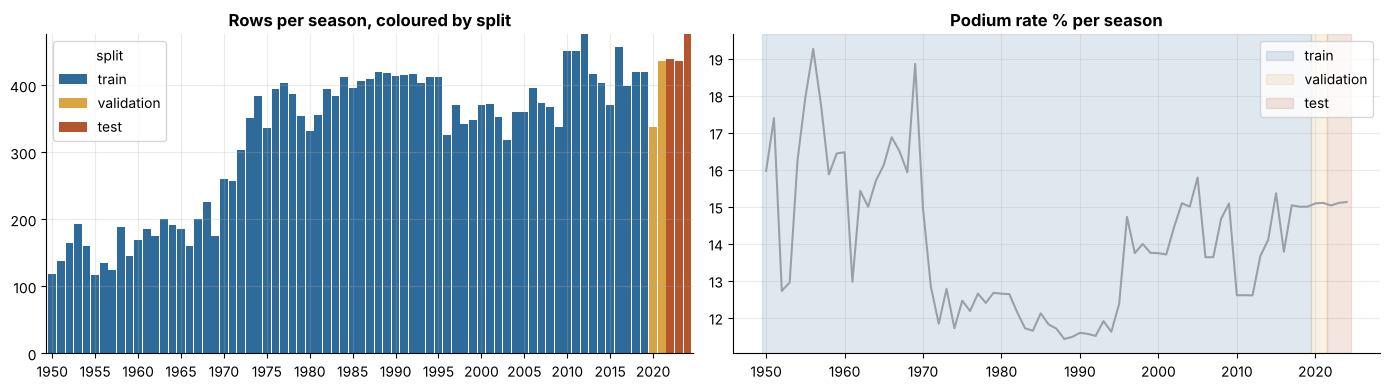

,seasons,races,rows,podiums,podium_rate
split,,,,,
train,1950–2019,1007,22459,3038,13.5
validation,2020–2021,39,775,117,15.1
test,2022–2024,68,1352,204,15.1


,driver never seen in train %,constructor never seen in train %
validation,13.7,15.6
test,21.9,20.0


In [ ]:
M["split"] = np.select([M.year <= 2019, M.year <= 2021], ["train", "validation"], default="test")

summary = M.groupby("split").agg(seasons=("year", lambda s: f"{s.min()}–{s.max()}"), races=("raceId", "nunique"),
                                 rows=("podium", "size"), podiums=("podium", "sum"), podium_rate=("podium", "mean"))
summary["podium_rate"] = (100 * summary.podium_rate).round(1)
summary = summary.loc[["train", "validation", "test"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
per_year = M.groupby(["year", "split"]).size().unstack(fill_value=0)
per_year[["train", "validation", "test"]].plot(kind="bar", stacked=True, ax=axes[0], width=0.9,
                                                color=[SPLIT_COLORS[s] for s in ["train", "validation", "test"]])
axes[0].set_xticks(range(0, len(per_year), 5)); axes[0].set_xticklabels(per_year.index[::5], rotation=0)
axes[0].set_title("Rows per season, coloured by split"); axes[0].set_xlabel("")
rate = M.groupby("year").podium.mean() * 100
axes[1].plot(rate.index, rate.values, color=GREY)
for s, (a, b) in {"train": (1950, 2019), "validation": (2020, 2021), "test": (2022, 2024)}.items():
    axes[1].axvspan(a - .5, b + .5, color=SPLIT_COLORS[s], alpha=.15, label=s)
axes[1].set_title("Podium rate % per season"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

train_ids = M.loc[M.split == "train"]
unseen = pd.DataFrame({
    "driver never seen in train %": {s: round(100 * (~M.loc[M.split == s, "driverId"].isin(train_ids.driverId)).mean(), 1) for s in ["validation", "test"]},
    "constructor never seen in train %": {s: round(100 * (~M.loc[M.split == s, "constructorId"].isin(train_ids.constructorId)).mean(), 1) for s in ["validation", "test"]}})
display(summary); display(unseen)

Rough sizes: ~22k train / ~0.8k validation / ~1.4k test rows. A non-trivial share of validation/test rows involve drivers or constructors unseen in train (team renames inflate that). That is why we later use **form + lineage**, not raw IDs.


## 3.3 Candidate features

Before coding columns, we list **candidates that are known at the pre-race cutoff** (after qualifying / grid, before lights out). Later cells *build* these columns; sections 3.6–3.9 *test* which ones to keep.

| Group | Examples | Known before the race because… |
|---|---|---|
| grid | `grid_eff`, `grid_rel`, … | the starting grid is fixed |
| qualifying | `quali_pos`, `quali_gap_pct`, … | qualifying has finished |
| driver / constructor form | rolling podium rate, etc. | computed only from **earlier** races |
| standings | points share **before** this race | table after the previous race |
| circuit / home / field size | conversion rate, `home_race`, `n_starters` | known in advance or from past races |

### Deliberately excluded

- **Driver and constructor IDs:** About 1 in 5 test rows involve unseen drivers or teams, and constructors can be renamed (3.2).
- **Year / season:** Test years fall outside the training range, requiring extrapolation. `n_starters` and relative features capture era differences instead.
- **Sprint results (2021+):** Available for only a few weekends, and early sprints already influenced Sunday's grid, which `grid` captures. We maintain a consistent pre-race definition, as noted in the brief.
- **Banned features:** All features listed in Section 3.4 are excluded.

### 3.3a Grid and qualifying features

* **`grid_eff`:** if `grid == 0` (pit lane), replace with `max(grid in that race) + 1` so 0 is not treated as pole.
* **`grid_rel`:** `grid_eff / n_starters` (capped at 1) so “10th of 14” ≠ “10th of 34”.
* **`grid_log`, `front_row`:** other shapes of the same idea (tested later in Trial 1).
* Loads qualifying times, takes each driver’s best of Q1/Q2/Q3, compares to pole → **`quali_gap_pct`**, keeps **`quali_pos`**.
* Checks the 2006–09 “Q3 on race fuel” era (fastest lap rarely comes from Q3 if we take the min).
* Left-joins onto `M`, sets **`quali_missing`**, and **`grid_minus_quali`** (penalty / grid vs quali difference).
* Prints a describe table for a quick sanity check.


In [ ]:
# --- grid features: known once the grid is set ---
M["pitlane_start"] = M.pitlane_start.astype(bool)
last_slot = M.groupby("raceId").grid.transform("max")
M["grid_eff"] = np.where(M.grid == 0, last_slot + 1, M.grid).astype(float)   # pit-lane start = behind the whole grid
M["grid_rel"] = (M.grid_eff / M.n_starters).clip(upper=1.0)                  # 0..1 position within the field (grid numbers can have gaps in early years)
M["grid_log"] = np.log(M.grid_eff)                                           # podium chance falls steeply then flattens (see 3.5)
M["front_row"] = (M.grid_eff <= 2).astype(int)

# --- qualifying features: known after qualifying ---
qf = clean["qualifying"][["raceId", "driverId", "position", "q1_s", "q2_s", "q3_s"]].copy()
qf["best_s"] = qf[["q1_s", "q2_s", "q3_s"]].min(axis=1)                    # driver's fastest lap of the day
qf["pole_s"] = qf.groupby("raceId").best_s.transform("min")
qf["quali_gap_pct"] = 100 * (qf.best_s / qf.pole_s - 1)                         # % slower than pole, comparable across circuits and eras
# 2006-09: Q3 was run on race fuel (slow laps). Does the fastest lap of the day come from Q3 in those seasons?
fuel_era = qf.merge(RA[["raceId", "year"]], on="raceId")
fuel_era = fuel_era[fuel_era.year.between(2006, 2009) & fuel_era.q3_s.notna()]
print(f"2006–09, drivers who reached Q3: their fastest lap was set in Q3 in {(fuel_era.q3_s < fuel_era[['q1_s', 'q2_s']].min(axis=1)).mean():.0%} of rows")

qf = qf.rename(columns={"position": "quali_pos"})[["raceId", "driverId", "quali_pos", "quali_gap_pct"]]
M = M.merge(qf, on=["raceId", "driverId"], how="left", validate="one_to_one")
M["quali_pos"] = M.quali_pos.astype(float)
M["quali_missing"] = M.quali_pos.isna().astype(int)
M["grid_minus_quali"] = M.grid_eff - M.quali_pos                             # > 0: started behind where he qualified (penalty)

M[["grid", "grid_eff", "grid_rel", "pitlane_start", "quali_pos", "quali_gap_pct", "grid_minus_quali"]].describe().T.round(2)

2006–09, drivers who reached Q3: their fastest lap was set in Q3 in 6% of rows


,count,mean,std,min,25%,50%,75%,max
grid,24586.0,11.726999,6.759736,0.0,6.0,12.0,17.0,34.0
grid_eff,24586.0,11.8007,6.746852,1.0,6.0,12.0,17.0,34.0
grid_rel,24586.0,0.524608,0.289543,0.029412,0.272727,0.526316,0.772727,1.0
quali_pos,10418.0,11.168842,6.249907,1.0,6.0,11.0,16.0,26.0
quali_gap_pct,10266.0,2.390558,2.56326,0.0,0.903493,1.835927,3.062447,45.595649
grid_minus_quali,10418.0,0.005087,1.53406,-9.0,0.0,0.0,0.0,23.0


### 3.3b Form features (past races only)

1. **Driver form** — within each `driverId`, `shift(1)` the outcome *first*, then rolling/expanding means:
   * last-5 podium rate and relative finish, career podium rate, prior start count.
2. **Team identity** — map renamed modern teams to one `team_key` (lineage) so history is not broken by a rebrand; prints unseen-% for raw ID vs lineage.
3. **Constructor form** — collapse to one row per team-race, again `shift(1)` then roll podium / finish / DNF rate; merge back to every driver row.
4. Reports % missing for the new form columns (debuts / first races are empty by design).

**Leakage rule:** the current race must never enter its own form feature. Section 3.5 re-checks this the slow way.


In [ ]:
# --- driver form: only his PAST starts. shift(1) removes the current race before any rolling window is applied ---
g = M.groupby("driverId", sort=False)
M["driver_prior_starts"] = g.cumcount()                                                                   # career starts before this race
M["driver_form_podium5"] = g.podium.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())      # podium rate, last 5 starts
M["driver_form_relpos5"] = g.rel_finish.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())  # avg finish (0=win, 1=last), last 5
M["driver_career_podium"] = g.podium.transform(lambda s: s.shift(1).expanding().mean())                   # career podium rate

# --- team identity: a renamed team (same factory and staff, Q3 lineage) keeps its history ---
CONSTRUCTOR_NAME = clean["constructors"].set_index("constructorId").name
def team_key(constructor_ids, years):
    # renames are linked only from 2010 on, so old teams that reused a name (Alfa Romeo 1950s, Aston Martin 1959-60) stay separate
    names = constructor_ids.map(CONSTRUCTOR_NAME)
    return pd.Series(np.where((years >= 2010) & names.isin(list(LINEAGE)), names.map(LINEAGE), "id " + constructor_ids.astype(str)),
                     index=constructor_ids.index)
M["team_key"] = team_key(M.constructorId, M.year)

seen = M[M.split == "train"]
print(pd.DataFrame({"constructorId never seen in train %": {s: round(100 * (~M.loc[M.split == s, "constructorId"].isin(seen.constructorId)).mean(), 1) for s in ["validation", "test"]},
                    "team (lineage) never seen in train %": {s: round(100 * (~M.loc[M.split == s, "team_key"].isin(seen.team_key)).mean(), 1) for s in ["validation", "test"]}}))

# --- constructor form: one row per team-race, rolled over that team's PREVIOUS races ---
team = (M.groupby(["team_key", "raceId", "race_order"])
          .agg(c_podium=("podium", "mean"), c_relpos=("rel_finish", "mean"), c_dnf=("finished", lambda s: 1 - s.mean()))
          .reset_index().sort_values(["team_key", "race_order"]))
tg = team.groupby("team_key", sort=False)
team["con_form_podium5"] = tg.c_podium.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
team["con_form_relpos5"] = tg.c_relpos.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
team["con_dnf_rate10"] = tg.c_dnf.transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())       # share of cars NOT finishing, any cause
M = M.merge(team[["team_key", "raceId", "con_form_podium5", "con_form_relpos5", "con_dnf_rate10"]],
            on=["team_key", "raceId"], how="left", validate="many_to_one")

form_cols = ["driver_form_podium5", "driver_form_relpos5", "driver_career_podium", "con_form_podium5", "con_form_relpos5", "con_dnf_rate10"]
pd.DataFrame({"% missing": (100 * M[form_cols].isna().mean()).round(1)})

            constructorId never seen in train %  \
validation                                 15.6   
test                                       20.0   

            team (lineage) never seen in train %  
validation                                   0.0  
test                                         0.0  


,% missing
driver_form_podium5,2.8
driver_form_relpos5,2.8
driver_career_podium,2.8
con_form_podium5,1.1
con_form_relpos5,1.1
con_dnf_rate10,1.1


### 3.3c Standings, circuit and home features

1. Builds `prev_raceId` (previous race in calendar order; round 1 → last race of previous season).
2. Joins **driver** and **constructor** standings on that previous race; converts points/rank to shares so eras with different scoring stay comparable.
3. Drivers/teams missing from an existing previous table get 0 points / worst relative rank (debut / no points yet).
4. **`circuit_front_conv`:** past front-row → podium rate at this circuit (strictly earlier races), shrunk toward the global past rate (K = 8).
5. **`home_race`:** 1 if circuit country matches the driver’s nationality via the translation table from Part 1.
6. Asserts merges did not duplicate rows; describes the new columns.


In [ ]:
# --- standings BEFORE the race = standings recorded after the PREVIOUS race (for round 1: the last race of last season) ---
order = RA[["raceId", "year", "round"]].sort_values(["year", "round"]).copy()
order["prev_raceId"] = order.raceId.shift(1)             # NaN only for the very first race (1950)
M = M.merge(order[["raceId", "prev_raceId"]], on="raceId", how="left", validate="many_to_one")

ds = clean["driver_standings"][["raceId", "driverId", "points", "position"]].copy()
ds["drv_stand_points_share"] = np.where(ds.groupby("raceId").points.transform("max") > 0,
                                        ds.points / ds.groupby("raceId").points.transform("max"), 0.0)   # share of the leader's points: comparable across scoring systems
ds["drv_stand_rank_rel"] = ds.position / ds.groupby("raceId").position.transform("max")   # rank as a share of ranked drivers (0 = leader)
M = M.merge(ds[["raceId", "driverId", "drv_stand_points_share", "drv_stand_rank_rel"]].rename(columns={"raceId": "prev_raceId"}),
            on=["prev_raceId", "driverId"], how="left", validate="many_to_one")

cs = clean["constructor_standings"][["raceId", "constructorId", "points", "position"]].merge(RA[["raceId", "year"]], on="raceId")
cs["team_key"] = team_key(cs.constructorId, cs.year)          # same team identity as constructor form
cs["con_stand_points_share"] = np.where(cs.groupby("raceId").points.transform("max") > 0,
                                        cs.points / cs.groupby("raceId").points.transform("max"), 0.0)
cs["con_stand_rank_rel"] = cs.position / cs.groupby("raceId").position.transform("max")
# late 2018: Force India (frozen points) and its successor Racing Point are both in the table -> keep the stronger entry
cs = cs.sort_values("con_stand_points_share", ascending=False).drop_duplicates(["raceId", "team_key"])
M = M.merge(cs[["raceId", "team_key", "con_stand_points_share", "con_stand_rank_rel"]].rename(columns={"raceId": "prev_raceId"}),
            on=["prev_raceId", "team_key"], how="left", validate="many_to_one")

# Not in the previous table, although that table exists = no points yet (debutant, or did not race last season).
# Still NaN: the first race of 1950, and teams before 1958 (no constructors' championship yet).
for table, share, rank in [(ds, "drv_stand_points_share", "drv_stand_rank_rel"), (cs, "con_stand_points_share", "con_stand_rank_rel")]:
    absent = M.prev_raceId.isin(table.raceId) & M[share].isna()
    M.loc[absent, share], M.loc[absent, rank] = 0.0, 1.0

# --- circuit: how often front-row starters converted at this circuit in EARLIER races (Q1), shrunk towards the global past rate ---
fr = (M[M.grid_eff <= 2].groupby("raceId").podium.agg(fr_pod="sum", fr_n="size").reset_index())
races_in_order = M.groupby("raceId").agg(race_order=("race_order", "first"), circuitId=("circuitId", "first")).reset_index()
fr = races_in_order.merge(fr, on="raceId", how="left").fillna({"fr_pod": 0, "fr_n": 0}).sort_values("race_order")
# all earlier races, all circuits. The very first race has no past: start from 0.7, close to the long-run conversion in Q1 (68-76%)
fr["global_rate"] = (fr.fr_pod.cumsum().shift(1) / fr.fr_n.cumsum().shift(1)).fillna(0.7)
cg = fr.groupby("circuitId", sort=False)
fr["c_pod"] = cg.fr_pod.cumsum() - fr.fr_pod                                                  # this circuit, strictly earlier races
fr["c_n"] = cg.fr_n.cumsum() - fr.fr_n
K = 8                                                                                         # "worth 8 pseudo front-row starts" of the global rate
fr["circuit_front_conv"] = (fr.c_pod + K * fr.global_rate) / (fr.c_n + K)
M = M.merge(fr[["raceId", "circuit_front_conv"]], on="raceId", how="left", validate="many_to_one")

# --- home race (candidate): circuit country is one of the driver's countries (translation table from §1.3.4) ---
homes = (M[["raceId", "driverId", "circuitId"]].merge(clean["drivers"][["driverId", "nationality"]], on="driverId")
         .merge(clean["circuits"][["circuitId", "country"]], on="circuitId")
         .merge(clean["nationality_country"][["nationality", "country"]], on=["nationality", "country"]))
M["home_race"] = M.set_index(["raceId", "driverId"]).index.isin(homes.set_index(["raceId", "driverId"]).index).astype(int)

assert len(M) == M.groupby(["raceId", "driverId"]).ngroups, "a merge duplicated rows"
M[["drv_stand_points_share", "drv_stand_rank_rel", "con_stand_points_share", "con_stand_rank_rel", "circuit_front_conv", "home_race"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
drv_stand_points_share,24563.0,0.205349,0.28611,0.0,0.0,0.067708,0.3,1.0
drv_stand_rank_rel,24563.0,0.482304,0.301141,0.009524,0.217391,0.451613,0.730769,1.0
con_stand_points_share,23425.0,0.292211,0.336439,0.0,0.018293,0.136986,0.492958,1.0
con_stand_rank_rel,23425.0,0.495375,0.284831,0.045455,0.25,0.470588,0.727273,1.0
circuit_front_conv,24586.0,0.552197,0.093907,0.302768,0.496655,0.552306,0.615996,1.0
home_race,24586.0,0.078581,0.26909,0.0,0.0,0.0,0.0,1.0


## 3.4 Feature groups and the banned list

* Packs every candidate into named **`FEATURE_GROUPS`** and a flat **`CANDIDATES`** list (used by trials and later ablation).
* Defines **`LEAKY`**: post-race / current-race outcome columns. An **`assert`** fails if any of them slipped into `CANDIDATES`.
* Shows each candidate’s **coverage % in the training split** (how often it is non-missing).

This is the checklist that keeps the modeling table honest against the milestone cutoff.


In [ ]:
FEATURE_GROUPS = {
    "grid":             ["grid_eff", "grid_rel", "grid_log", "pitlane_start", "front_row"],
    "qualifying":       ["quali_pos", "quali_gap_pct", "quali_missing", "grid_minus_quali"],
    "driver_form":      ["driver_form_podium5", "driver_form_relpos5", "driver_career_podium", "driver_prior_starts"],
    "constructor_form": ["con_form_podium5", "con_form_relpos5", "con_dnf_rate10"],
    "standings":        ["drv_stand_points_share", "drv_stand_rank_rel", "con_stand_points_share", "con_stand_rank_rel"],
    "circuit":          ["circuit_front_conv"],
    "context":          ["n_starters"],
    "home":             ["home_race"],
}
CANDIDATES = [c for cols in FEATURE_GROUPS.values() for c in cols]
GROUP_OF = {c: g for g, cols in FEATURE_GROUPS.items() for c in cols}
TARGET = "podium"

# columns that only exist AFTER the race (or describe the current race's outcome): never allowed as features
LEAKY = {"positionOrder", "position", "positionText", "points", "laps", "time_text", "milliseconds", "fastestLap", "rank",
         "fastestLapTime", "fastestLapSpeed", "fastestLapTime_s", "statusId", "status", "finished", "rel_finish", "podium"}
assert not (set(CANDIDATES) & LEAKY), "a post-race column is in the candidate list"

tr, va, te = (M[M.split == s] for s in ["train", "validation", "test"])
pd.DataFrame({"group": GROUP_OF}).assign(coverage_in_train_pct=lambda d: [round(100 * tr[c].notna().mean(), 1) for c in d.index])

,group,coverage_in_train_pct
grid_eff,grid,100.0
grid_rel,grid,100.0
grid_log,grid,100.0
pitlane_start,grid,100.0
front_row,grid,100.0
quali_pos,qualifying,36.9
quali_gap_pct,qualifying,36.3
quali_missing,qualifying,100.0
grid_minus_quali,qualifying,36.9
driver_form_podium5,driver_form,97.0


Most features cover almost all training rows. **Qualifying is the outlier (~37% coverage)** — missing for most of early history, nearly complete from 2003. That coverage drift is why Trial 3 (training window) and the preprocessing experiments matter.


## 3.5 Leakage test: prove the history features use only the past

* Draws 400 random rows.
* For each, **recomputes** `driver_form_podium5`, `con_form_podium5`, and `drv_stand_points_share` the slow way: filter to races with `race_order` strictly smaller, then average.
* Compares slow vs fast (vectorised) values; counts mismatches.
* Also checks: every driver’s first start has empty driver form; every round-1 row (from 1951) reads last season’s final standings race.
* **`assert`s zero mismatches** — the notebook stops if the “past only” claim is false.


In [ ]:
# Brute-force re-computation: for random rows, rebuild each "history" feature the slow, obviously-correct way
# (filter the table to races strictly BEFORE this one) and compare with the fast vectorised value.
rng = np.random.default_rng(SEED)
sample = rng.choice(M.index, 400, replace=False)

def slow_driver_form(i):
    r = M.loc[i]
    past = M[(M.driverId == r.driverId) & (M.race_order < r.race_order)].sort_values("race_order")
    return past.podium.tail(5).mean() if len(past) else np.nan

def slow_constructor_form(i):
    r = M.loc[i]
    past = M[(M.team_key == r.team_key) & (M.race_order < r.race_order)]
    per_race = past.groupby("race_order").podium.mean().sort_index()        # one value per earlier team-race
    return per_race.tail(5).mean() if len(per_race) else np.nan

def slow_standings(i):
    r = M.loc[i]
    prev = order.loc[order.raceId == r.raceId, "prev_raceId"].iloc[0]
    if pd.isna(prev):
        return np.nan
    s = ds[(ds.raceId == prev) & (ds.driverId == r.driverId)]
    if len(s):
        return s.drv_stand_points_share.iloc[0]
    return 0.0 if (ds.raceId == prev).any() else np.nan       # not in an existing table = no points yet

checks = {}
for name, slow, col in [("driver_form_podium5", slow_driver_form, "driver_form_podium5"),
                        ("con_form_podium5", slow_constructor_form, "con_form_podium5"),
                        ("drv_stand_points_share", slow_standings, "drv_stand_points_share")]:
    brute = pd.Series({i: slow(i) for i in sample}, dtype=float)
    fast = M.loc[sample, col]
    checks[name] = {"rows compared": len(sample), "mismatches": int((~np.isclose(brute, fast, equal_nan=True)).sum())}

first_start = M.groupby("driverId").head(1)
checks["debut rows have no driver history"] = {"rows compared": len(first_start),
                                               "mismatches": int(first_start.driver_form_podium5.notna().sum())}
last_race_of_season = RA.sort_values("round").groupby("year").raceId.last()
round_one = M[(M["round"] == 1) & (M.year > 1950)]
checks["round-1 rows read last season's final table"] = {"rows compared": len(round_one),
                                                         "mismatches": int((round_one.prev_raceId != (round_one.year - 1).map(last_race_of_season)).sum())}
result = pd.DataFrame(checks).T
assert (result.mismatches == 0).all(), result
result

,rows compared,mismatches
driver_form_podium5,400,0
con_form_podium5,400,0
drv_stand_points_share,400,0
debut rows have no driver history,683,0
round-1 rows read last season's final table,1572,0


Zero mismatches on the sampled rows; debut and round-1 structural checks pass. So the history features are past-only in the *code*, not only in the comments.


## 3.6 Evidence for the feature choices (training rows only)

All plots and scores below use **`tr` (train seasons only)** so validation/test never shape which features we pick.

Four views:
* **3.6a** — how podium rate changes with starting slot (shape → how to encode grid).
* **3.6b** — each feature alone as a score (ROC-AUC).
* **3.6c** — podium rate across quintiles of each feature.
* **3.6d** — which features are near-duplicates of each other.


### 3.6a Starting slot vs podium rate

* Left plot: podium % by absolute `grid_eff` for all train years and for 2003–2019.
* Right plot: same idea with **relative** grid deciles, split by era.
* Table: podium % at selected slots (P1, P2, …).

We look at the *curve* first because a steep non-linear drop suggests raw slot alone may need a relative (or log) companion — tested in Trial 1.


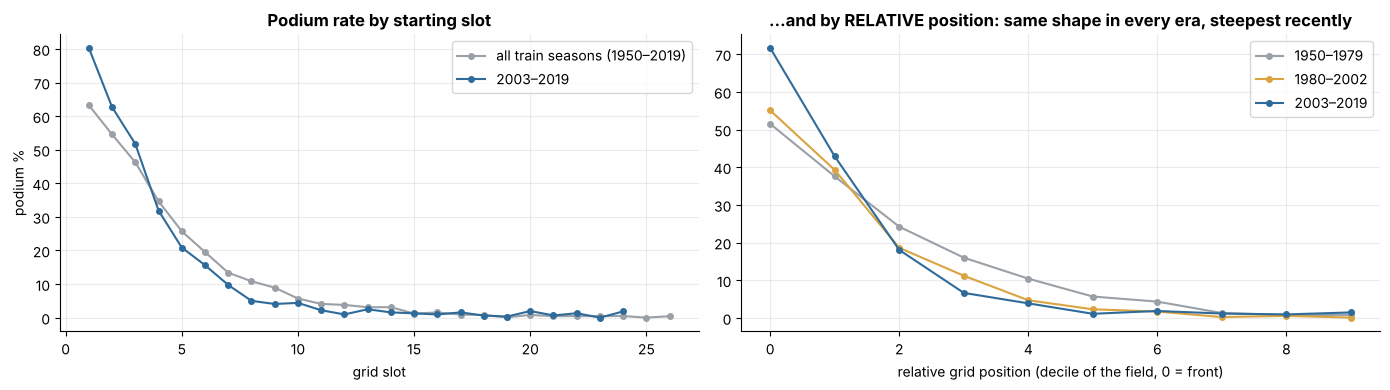

grid slot,1,2,3,5,10,12,15,20
all train seasons,63.3,54.6,46.3,25.7,5.7,3.8,1.2,0.8
2003–2019,80.3,62.7,51.7,20.9,4.4,0.9,1.3,2.0


In [ ]:
# EVIDENCE USES THE TRAINING ROWS ONLY (tr), so nothing about validation/test shapes our feature choices
d = tr[tr.grid_eff <= 26]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(d.groupby("grid_eff").podium.mean() * 100, marker="o", ms=4, color=GREY, label="all train seasons (1950–2019)")
axes[0].plot(d[d.year >= 2003].groupby("grid_eff").podium.mean() * 100, marker="o", ms=4, color=AFTER, label="2003–2019")
axes[0].set_xlabel("grid slot"); axes[0].set_ylabel("podium %"); axes[0].set_title("Podium rate by starting slot"); axes[0].legend()

bins = pd.cut(tr.grid_rel, np.linspace(0, 1, 11), include_lowest=True)
for (a, b), color in zip([(1950, 1979), (1980, 2002), (2003, 2019)], [GREY, ACCENT, AFTER]):
    s = tr[tr.year.between(a, b)]
    axes[1].plot(range(10), (s.groupby(pd.cut(s.grid_rel, np.linspace(0, 1, 11), include_lowest=True)).podium.mean() * 100).values,
                 marker="o", ms=4, color=color, label=f"{a}–{b}")
axes[1].set_xlabel("relative grid position (decile of the field, 0 = front)"); axes[1].set_title("…and by RELATIVE position: same shape in every era, steepest recently")
axes[1].legend(); plt.tight_layout(); plt.show()

# the same curve as numbers: podium % for selected starting slots
slots = [1, 2, 3, 5, 10, 12, 15, 20]
pd.DataFrame({"all train seasons": d.groupby("grid_eff").podium.mean().reindex(slots) * 100,
              "2003–2019": d[d.year >= 2003].groupby("grid_eff").podium.mean().reindex(slots) * 100}).rename_axis("grid slot").round(1).T

Podium chance falls steeply with worse grid slots (especially in the modern era: pole is often ~80% podium). The same shape appears in every era on the relative axis. A purely linear treatment of grid would fit this poorly — hence Trial 1.


### 3.6b Each candidate on its own

* For every candidate, on training rows where it is non-missing, computes ROC-AUC of that single column as a score for `podium`.
* Reports `max(AUC, 1−AUC)` so “lower is better” features (e.g. grid) still rank high, plus Spearman correlation.
* Draws a horizontal bar chart coloured by feature group.

* Qualifying AUCs are measured mostly on modern rows (low coverage), so they are not fully comparable to full-history features.


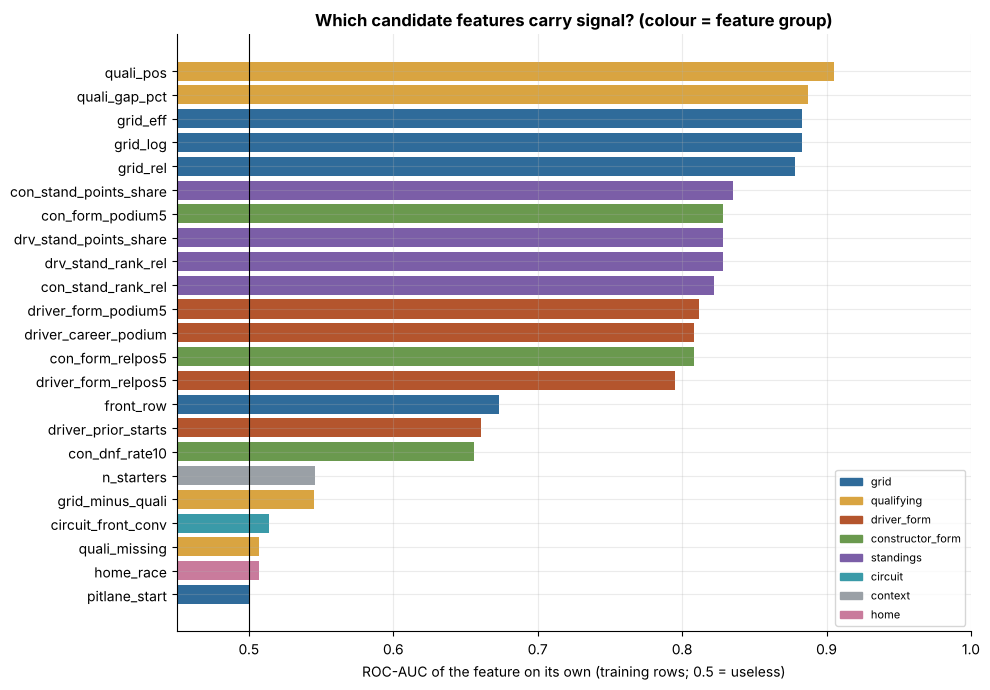

,feature,group,coverage %,AUC alone,podium when feature is,Spearman
0,quali_pos,qualifying,36.9,0.905,lower,-0.488
1,quali_gap_pct,qualifying,36.3,0.887,lower,-0.466
2,grid_eff,grid,100.0,0.883,lower,-0.454
3,grid_log,grid,100.0,0.883,lower,-0.454
4,grid_rel,grid,100.0,0.878,lower,-0.448
5,con_stand_points_share,standings,94.8,0.835,higher,0.397
6,con_form_podium5,constructor_form,98.8,0.828,higher,0.424
7,drv_stand_points_share,standings,99.9,0.828,higher,0.398
8,drv_stand_rank_rel,standings,99.9,0.828,lower,-0.389
9,con_stand_rank_rel,standings,94.8,0.822,lower,-0.380


In [ ]:
rows = []
for c in CANDIDATES:
    x = tr[[c, TARGET]].dropna()
    a = roc_auc_score(x[TARGET], x[c])
    rows.append({"feature": c, "group": GROUP_OF[c], "coverage %": round(100 * len(x) / len(tr), 1),
                 "AUC alone": round(max(a, 1 - a), 3), "podium when feature is": "higher" if a > 0.5 else "lower",
                 "Spearman": round(x[c].corr(x[TARGET], method="spearman"), 3)})
uni = pd.DataFrame(rows).sort_values("AUC alone", ascending=False).reset_index(drop=True)

palette = dict(zip(FEATURE_GROUPS, ["#2F6B9A", "#D9A441", "#B4552D", "#6A994E", "#7B5EA7", "#3A9AA8", GREY, "#C97B9C"]))
fig, ax = plt.subplots(figsize=(10, 7))
u = uni.iloc[::-1]
ax.barh(u.feature, u["AUC alone"], color=[palette[g] for g in u.group]); ax.axvline(0.5, color="k", lw=.8)
ax.set_xlim(0.45, 1); ax.set_xlabel("ROC-AUC of the feature on its own (training rows; 0.5 = useless)")
ax.set_title("Which candidate features carry signal? (colour = feature group)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], labels=list(palette), loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
uni

Strong alone: qualifying, grid, standings, constructor/driver form (AUC roughly 0.80–0.91).  
Weak alone: circuit conversion, home race, pit-lane flag, `grid_minus_quali`, `n_starters`.  

Weak alone ≠ automatically drop — a penalty feature can still help *given* the grid. Trials 2–3 decide with a real model.


### 3.6c Podium rate across each feature's range

* For several candidates, splits training rows into five equal-sized groups (quintiles) and plots podium % in each.
* Separately plots podium % vs `n_starters` against the simple baseline curve **3 / N** (three podium places).

If a feature matters, the bars should rise or fall across the range; if flat, there is little signal.


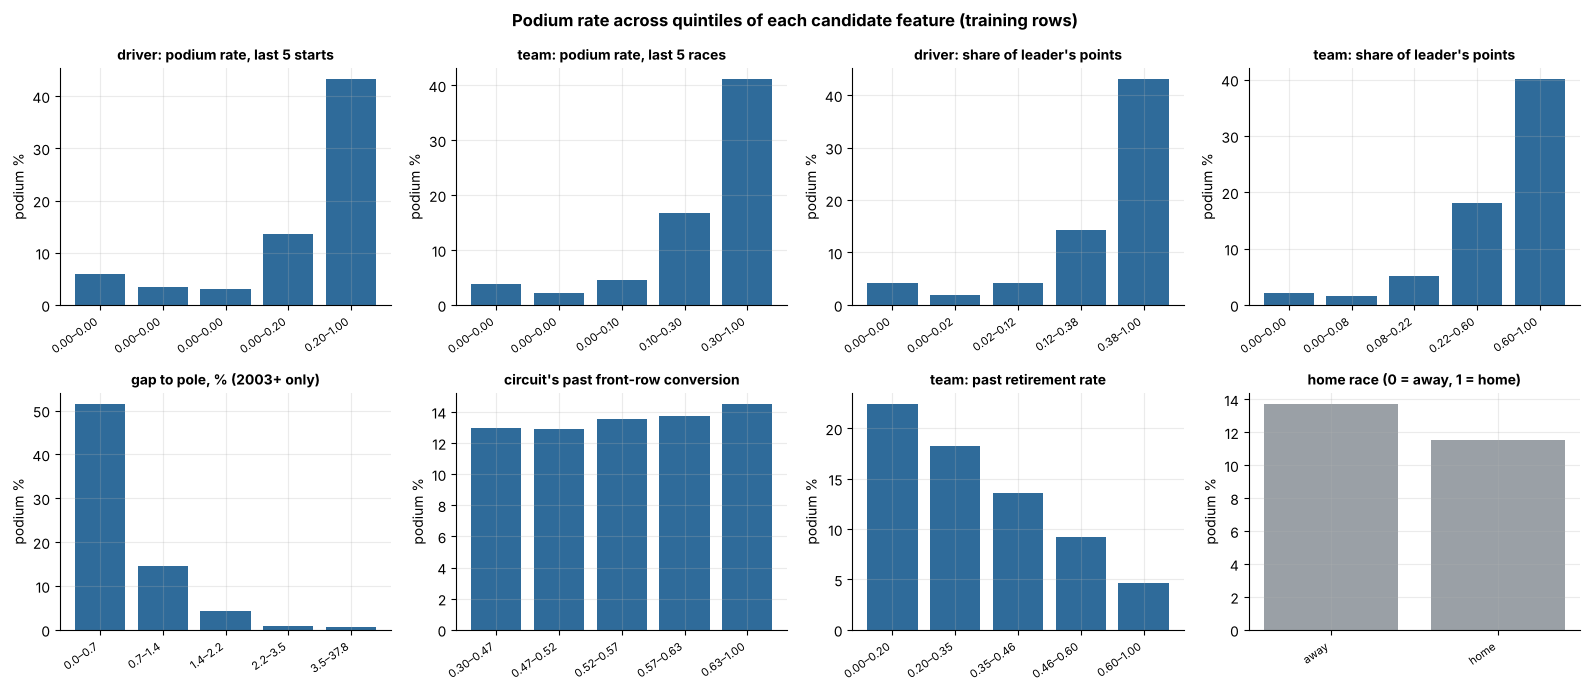

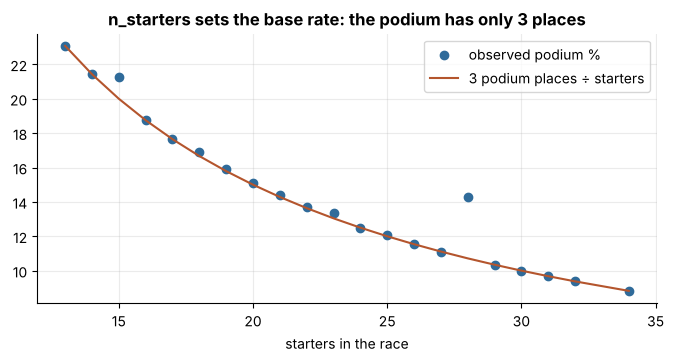

,podium % per fifth of the rows (lowest value → highest value)
driver_form_podium5,5.8 → 3.5 → 3.1 → 13.6 → 43.2
con_form_podium5,3.8 → 2.1 → 4.5 → 16.7 → 41.1
drv_stand_points_share,4.1 → 2.0 → 4.2 → 14.2 → 43.0
con_stand_points_share,2.1 → 1.5 → 5.2 → 18.1 → 40.1
quali_gap_pct,51.5 → 14.6 → 4.3 → 1.0 → 0.5
circuit_front_conv,13.0 → 12.9 → 13.5 → 13.7 → 14.5
con_dnf_rate10,22.4 → 18.3 → 13.6 → 9.2 → 4.6
home_race,13.7 → 11.5


n_starters,≤ 20 starters,21–26,> 26
podium %,16.0,12.6,10.7


In [ ]:
panels = [("driver_form_podium5", "driver: podium rate, last 5 starts"), ("con_form_podium5", "team: podium rate, last 5 races"),
          ("drv_stand_points_share", "driver: share of leader's points"), ("con_stand_points_share", "team: share of leader's points"),
          ("quali_gap_pct", "gap to pole, % (2003+ only)"), ("circuit_front_conv", "circuit's past front-row conversion"),
          ("con_dnf_rate10", "team: past retirement rate"), ("home_race", "home race (0 = away, 1 = home)")]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
quintile_rates = {}
for ax, (c, title) in zip(axes.ravel(), panels):
    x = tr[tr.year >= 2003] if c == "quali_gap_pct" else tr
    x = x[[c, TARGET]].dropna()
    if c == "home_race":
        r = x.groupby(c).podium.mean() * 100; labels = ["away", "home"]
    else:
        b = pd.qcut(x[c].rank(method="first"), 5, labels=False)          # 5 equal-sized groups (ties broken by row order)
        r = x.groupby(b).podium.mean() * 100
        rng_ = x.groupby(b)[c].agg(["min", "max"])
        labels = [f"{lo_:.2f}–{hi_:.2f}" if rng_["max"].abs().max() < 10 else f"{lo_:.1f}–{hi_:.1f}" for lo_, hi_ in zip(rng_["min"], rng_["max"])]
    ax.bar(range(len(r)), r.values, color=AFTER if c != "home_race" else GREY); ax.set_xticks(range(len(r))); ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_ylabel("podium %")
    quintile_rates[c] = "  →  ".join(f"{v:.1f}" for v in r.values)
plt.suptitle("Podium rate across quintiles of each candidate feature (training rows)", fontweight="bold"); plt.tight_layout(); plt.show()

n = tr.groupby("n_starters").podium.agg(["mean", "size"]); n = n[n["size"] >= 20]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(n.index, n["mean"] * 100, "o", color=AFTER, label="observed podium %"); ax.plot(n.index, 300 / n.index, color=BEFORE, label="3 podium places ÷ starters")
ax.set_xlabel("starters in the race"); ax.set_title("n_starters sets the base rate: the podium has only 3 places"); ax.legend(); plt.show()

display(pd.Series(quintile_rates, name="podium % per fifth of the rows (lowest value → highest value)").to_frame())
field = pd.cut(tr.n_starters, [0, 20, 26, 99], labels=["≤ 20 starters", "21–26", "> 26"])
(100 * tr.podium.groupby(field, observed=True).mean()).round(1).to_frame("podium %").T

Form and standings show clear gradients (top fifth much more likely to podium). Gap to pole is dramatic. Circuit conversion and home race stay flat — consistent with Q1/Q2. `n_starters` tracks the 3/N base rate, so it stays as a context feature even though its alone-AUC is low.


### 3.6d Redundancy between features

* Spearman correlation matrix of all candidates on training rows (heatmap).
* Lists every pair with |ρ| > 0.85.

Near-duplicates hurt interpretation later (XAI splits credit). We use this list when pruning in 3.10.


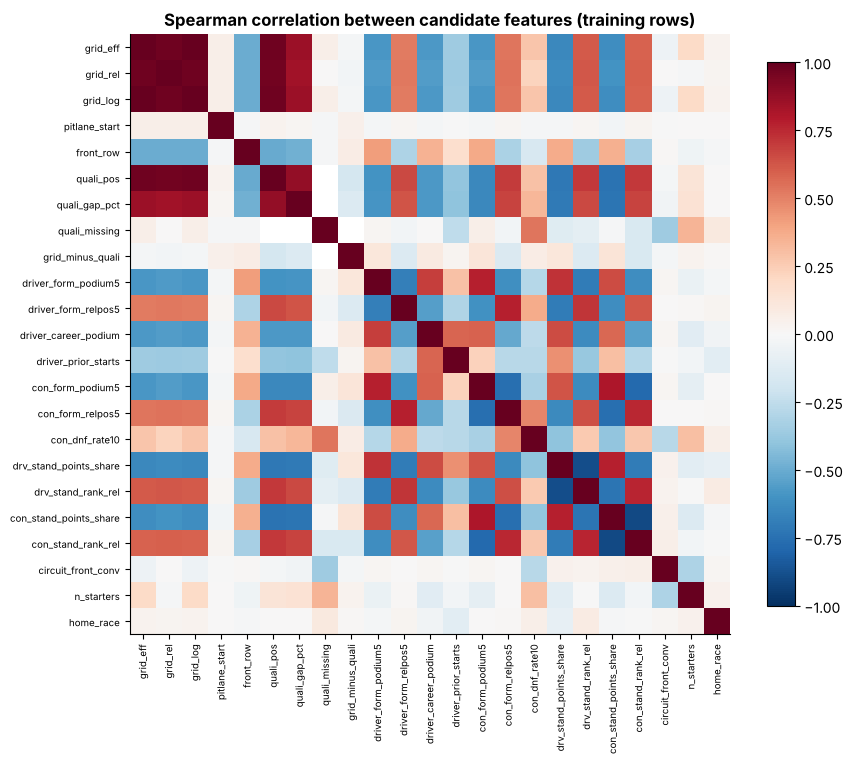

,feature A,feature B,rho,group A,group B
0,grid_eff,grid_log,1.00,grid,grid
1,grid_eff,quali_pos,0.98,grid,qualifying
2,grid_log,quali_pos,0.98,grid,qualifying
3,grid_eff,grid_rel,0.97,grid,grid
4,grid_rel,grid_log,0.97,grid,grid
5,grid_rel,quali_pos,0.96,grid,qualifying
6,con_stand_points_share,con_stand_rank_rel,-0.90,standings,standings
7,drv_stand_points_share,drv_stand_rank_rel,-0.89,standings,standings
8,quali_pos,quali_gap_pct,0.88,qualifying,qualifying
9,grid_eff,quali_gap_pct,0.86,grid,qualifying


In [ ]:
corr = tr[CANDIDATES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(CANDIDATES))); ax.set_xticklabels(CANDIDATES, rotation=90, fontsize=7)
ax.set_yticks(range(len(CANDIDATES))); ax.set_yticklabels(CANDIDATES, fontsize=7); plt.colorbar(im, shrink=.8)
ax.set_title("Spearman correlation between candidate features (training rows)"); plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "feature A", "level_1": "feature B"}))
pairs[["group A", "group B"]] = pairs[["feature A", "feature B"]].map(GROUP_OF.get)
pairs[pairs.rho.abs() > 0.85].sort_values("rho", key=abs, ascending=False).round(2).reset_index(drop=True)

Grid encodings and `quali_pos` form a tight block; standings rank mirrors points-share. We will drop exact duplicates (`grid_log`, rank versions) but keep both `grid_eff` and `quali_pos` because their **difference** is the penalty signal.


## 3.7 Trials: three experiments that decide the feature set

* Defines small model factories: logistic regression pipeline (impute → scale → LR) and gradient boosting.
* **`backtest_*`:** rolling-origin inside train seasons (blocks 2007–09 … 2016–19); each block is predicted only from earlier seasons.
* **`holdout_*`:** fit on train, score on **validation** only (test untouched).
* **`paired_race_bootstrap` / `change_text`:** confidence interval on Δ PR-AUC by resampling whole races (drivers in one race are dependent).

We need both yardsticks because validation is small (~39 races) and noisy.


In [ ]:
# Two yardsticks for feature decisions: the small VALIDATION set, and a ROLLING-ORIGIN BACKTEST inside the training seasons
# (for each block of seasons, train only on the seasons before it and predict the block; ~5,700 pooled rows). Test seasons are never used.
def make_linear(C=1.0):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LogisticRegression(C=C, max_iter=3000))

def make_hgb(**kw):
    # early_stopping=False: above 10,000 rows scikit-learn would otherwise switch it on silently, hold out 10% of the
    # training rows and ignore max_iter, which would make the number of trees in the tuning grid meaningless
    params = dict(max_depth=3, learning_rate=0.05, max_iter=200, early_stopping=False, random_state=SEED); params.update(kw)
    return HistGradientBoostingClassifier(**params)

BLOCKS = [(2007, 2009), (2010, 2012), (2013, 2015), (2016, 2019)]

def backtest_predictions(cols, kind="linear", first_year=1950):
    frames = []
    for a, b in BLOCKS:
        trn = tr[(tr.year >= first_year) & (tr.year < a)]; blk = tr[tr.year.between(a, b)]
        m = make_linear() if kind == "linear" else make_hgb()
        m.fit(trn[cols], trn[TARGET])
        frames.append(blk[["raceId", TARGET]].assign(p=m.predict_proba(blk[cols])[:, 1]))
    return pd.concat(frames)

def backtest(cols, kind="linear", first_year=1950):
    d = backtest_predictions(cols, kind, first_year)
    return {"ROC-AUC": round(roc_auc_score(d[TARGET], d.p), 3), "PR-AUC": round(average_precision_score(d[TARGET], d.p), 3)}

def holdout_predictions(cols, kind="linear", train=None):
    """fit on TRAIN rows, predict VALIDATION rows (test rows are never touched in this section)"""
    train = tr if train is None else train
    m = make_linear() if kind == "linear" else make_hgb()
    return m.fit(train[cols], train[TARGET]).predict_proba(va[cols])[:, 1]

def holdout(cols, kind="linear", train=None):
    p = holdout_predictions(cols, kind, train)
    return {"ROC-AUC": round(roc_auc_score(va[TARGET], p), 3), "PR-AUC": round(average_precision_score(va[TARGET], p), 3)}

def paired_race_bootstrap(race_ids, y, p_new, p_old, n_resamples=1000):
    """Δ PR-AUC (new − old) with a 95% interval. Whole races are resampled (drivers of one race are not independent),
    and both models are scored on the SAME resample, so only their difference varies."""
    y, p_new, p_old = np.asarray(y), np.asarray(p_new), np.asarray(p_old)
    rows_of_race = list(pd.Series(np.arange(len(y))).groupby(np.asarray(race_ids)).indices.values())
    rng = np.random.default_rng(SEED)
    diffs = []
    for _ in range(n_resamples):
        idx = np.concatenate([rows_of_race[i] for i in rng.integers(0, len(rows_of_race), len(rows_of_race))])
        diffs.append(average_precision_score(y[idx], p_new[idx]) - average_precision_score(y[idx], p_old[idx]))
    low, high = np.percentile(diffs, [2.5, 97.5])
    return average_precision_score(y, p_new) - average_precision_score(y, p_old), low, high

def change_text(race_ids, y, p_new, p_old):
    d, low, high = paired_race_bootstrap(race_ids, y, p_new, p_old, n_resamples=500)
    return f"{d:+.3f} [{low:+.3f}, {high:+.3f}]" + ("  clear" if low > 0 or high < 0 else "")

pooled = tr[tr.year.between(BLOCKS[0][0], BLOCKS[-1][1])]
print(f"backtest rows: {len(pooled)} ({int(pooled.podium.sum())} podiums, {pooled.raceId.nunique()} races)  vs  "
      f"validation rows: {len(va)} ({int(va.podium.sum())} podiums, {va.raceId.nunique()} races)")

backtest rows: 5348 (750 podiums, 250 races)  vs  validation rows: 775 (117 podiums, 39 races)


### Trial 1: how to encode the starting slot

Compares five encodings of the grid (raw / log / relative / combinations), using **logistic regression and grid features only**, scored on backtest and validation PR-AUC / ROC-AUC.

We want the simplest encoding that does not lose accuracy.


In [ ]:
# Trial 1: how should the starting slot be encoded? (logistic regression, grid features only)
trial = {"A  raw slot (grid_eff)": ["grid_eff"],
         "B  log slot (grid_log)": ["grid_log"],
         "C  relative slot (grid_rel)": ["grid_rel"],
         "D  raw + relative": ["grid_eff", "grid_rel"],
         "E  raw + relative + log + front_row": ["grid_eff", "grid_rel", "grid_log", "front_row"]}
trial1 = {}
for name, cols in trial.items():
    b = backtest(cols)
    trial1[name] = {"backtest PR-AUC": b["PR-AUC"], "backtest ROC-AUC": b["ROC-AUC"], "validation PR-AUC": holdout(cols)["PR-AUC"]}
pd.DataFrame(trial1).T

,backtest PR-AUC,backtest ROC-AUC,validation PR-AUC
A raw slot (grid_eff),0.668,0.919,0.648
B log slot (grid_log),0.669,0.920,0.648
C relative slot (grid_rel),0.661,0.918,0.650
D raw + relative,0.672,0.919,0.652
E raw + relative + log + front_row,0.672,0.919,0.652


All encodings are within ~0.01 PR-AUC. Extra log/front-row versions add nothing → keep **`grid_eff` + `grid_rel`**, drop `grid_log` and `front_row`.


## 3.8 Trial 2: add one feature group at a time

* Starts from grid only, then appends groups in EDA order: qualifying → constructor form → driver form → standings → circuit → context → home.
* At each step, scores logistic regression **and** gradient boosting on backtest + validation.
* Plots the PR-AUC ladder and a table of **changes vs the previous step** with bootstrap intervals (`clear` = interval excludes 0).

This shows which groups earn their place after the grid is already in the model.


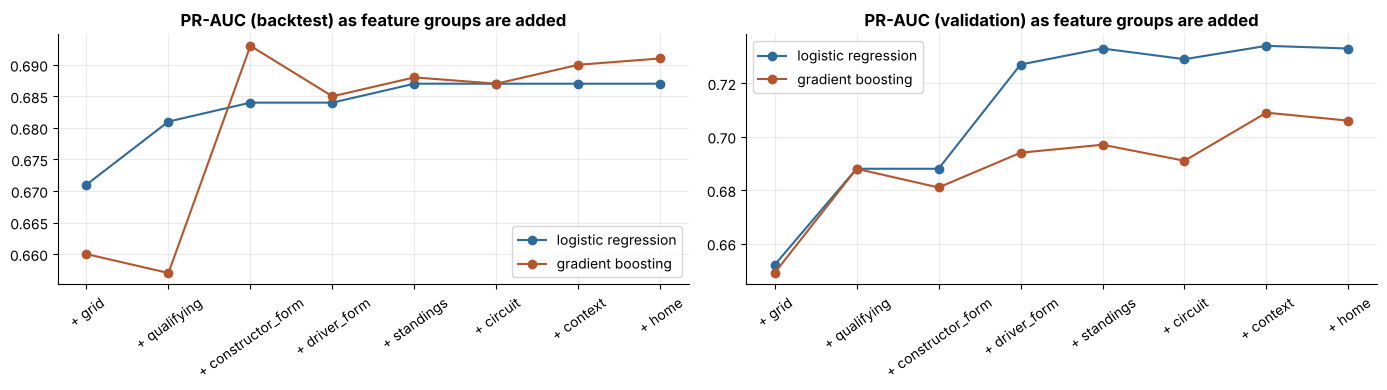

,features,linear backtest PR-AUC,linear validation PR-AUC,hgb backtest PR-AUC,hgb validation PR-AUC
step,,,,,
+ grid,5,0.671,0.652,0.660,0.649
+ qualifying,9,0.681,0.688,0.657,0.688
+ constructor_form,12,0.684,0.688,0.693,0.681
+ driver_form,16,0.684,0.727,0.685,0.694
+ standings,20,0.687,0.733,0.688,0.697
+ circuit,21,0.687,0.729,0.687,0.691
+ context,22,0.687,0.734,0.690,0.709
+ home,23,0.687,0.733,0.691,0.706


Change in PR-AUC vs the previous step  [95% interval, paired race bootstrap]


,linear backtest change,linear validation change,hgb backtest change,hgb validation change
step,,,,
+ qualifying,"+0.010 [+0.005, +0.015] clear","+0.035 [+0.011, +0.059] clear","-0.003 [-0.014, +0.008]","+0.039 [+0.014, +0.063] clear"
+ constructor_form,"+0.003 [-0.015, +0.024]","+0.001 [-0.052, +0.064]","+0.036 [+0.017, +0.055] clear","-0.008 [-0.050, +0.043]"
+ driver_form,"+0.001 [-0.011, +0.013]","+0.039 [+0.010, +0.061] clear","-0.008 [-0.021, +0.007]","+0.013 [-0.009, +0.043]"
+ standings,"+0.002 [-0.004, +0.009]","+0.006 [-0.005, +0.015]","+0.003 [-0.002, +0.008]","+0.003 [-0.009, +0.013]"
+ circuit,"-0.000 [-0.000, +0.000]","-0.004 [-0.010, +0.002]","-0.001 [-0.006, +0.004]","-0.006 [-0.015, +0.002]"
+ context,"+0.000 [-0.002, +0.002]","+0.005 [-0.001, +0.011]","+0.003 [+0.000, +0.006] clear","+0.018 [+0.004, +0.030] clear"
+ home,"-0.000 [-0.001, +0.000]","-0.000 [-0.002, +0.000]","+0.001 [-0.000, +0.002]","-0.002 [-0.006, +0.001]"


In [ ]:
# Trial 2: add one feature group at a time, in the order of our EDA hypothesis (strongest evidence first).
# For every step: the score, and the CHANGE vs the step before with a paired race bootstrap ("clear" = 95% interval excludes 0).
order_of_groups = ["grid", "qualifying", "constructor_form", "driver_form", "standings", "circuit", "context", "home"]
ladder, gains, cols, previous = [], [], [], {}
for g in order_of_groups:
    cols = cols + FEATURE_GROUPS[g]
    score_row, gain_row = {"step": f"+ {g}", "features": len(cols)}, {"step": f"+ {g}"}
    for kind in ["linear", "hgb"]:
        bt, pv = backtest_predictions(cols, kind), holdout_predictions(cols, kind)
        score_row[f"{kind} backtest PR-AUC"] = round(average_precision_score(bt[TARGET], bt.p), 3)
        score_row[f"{kind} validation PR-AUC"] = round(average_precision_score(va[TARGET], pv), 3)
        if kind in previous:
            old_bt, old_pv = previous[kind]
            gain_row[f"{kind} backtest change"] = change_text(bt.raceId, bt[TARGET], bt.p, old_bt.p)
            gain_row[f"{kind} validation change"] = change_text(va.raceId, va[TARGET], pv, old_pv)
        previous[kind] = (bt, pv)
    ladder.append(score_row)
    if g != order_of_groups[0]:
        gains.append(gain_row)
ladder, gains = pd.DataFrame(ladder).set_index("step"), pd.DataFrame(gains).set_index("step")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, split in zip(axes, ["backtest", "validation"]):
    ax.plot(ladder.index, ladder[f"linear {split} PR-AUC"], marker="o", color=AFTER, label="logistic regression")
    ax.plot(ladder.index, ladder[f"hgb {split} PR-AUC"], marker="o", color=BEFORE, label="gradient boosting")
    ax.set_title(f"PR-AUC ({split}) as feature groups are added"); ax.tick_params(axis="x", rotation=35); ax.legend()
plt.tight_layout(); plt.show()
display(ladder)
print("Change in PR-AUC vs the previous step  [95% interval, paired race bootstrap]")
gains

Grid carries most of the score. Qualifying and form groups show clear gains in at least some yardsticks. Standings are small but consistently non-negative. **Circuit and home never help** — they will be dropped. Order matters: later groups only add what earlier ones did not already cover.


## 3.9 Trial 3: how much history to train on

Keeps the same feature list (home already out of the candidate set for this trial) and the same models, but changes the **first training season** to 1950, 1980, 1994, or 2003. Reports training size, qualifying coverage, and backtest/validation PR-AUC for each window.

Question: does cutting early eras (poor qualifying coverage) help modern validation?


In [ ]:
# Trial 3: train on all history, or only on recent eras? Same features and models; only the first training season changes.
FEATS_FOR_WINDOW = [c for g in order_of_groups if g != "home" for c in FEATURE_GROUPS[g]]
window_rows = []
for start in [1950, 1980, 1994, 2003]:
    w = tr[tr.year >= start]
    row = {"first training season": start, "training rows": len(w), "podium %": round(100 * w.podium.mean(), 1),
           "quali available %": round(100 * (1 - w.quali_missing.mean()), 1)}
    for kind in ["linear", "hgb"]:
        b, h = backtest(FEATS_FOR_WINDOW, kind, first_year=start), holdout(FEATS_FOR_WINDOW, kind, train=w)
        row[f"{kind} backtest PR-AUC"], row[f"{kind} validation PR-AUC"] = b["PR-AUC"], h["PR-AUC"]
    window_rows.append(row)
window_trial = pd.DataFrame(window_rows).set_index("first training season")
window_trial

,training rows,podium %,quali available %,linear backtest PR-AUC,linear validation PR-AUC,hgb backtest PR-AUC,hgb validation PR-AUC
first training season,,,,,,,
1950,22459,13.5,36.9,0.687,0.734,0.690,0.709
1980,15671,13.2,52.9,0.684,0.732,0.689,0.702
1994,10093,14.0,82.2,0.686,0.734,0.680,0.701
2003,6783,14.2,99.7,0.687,0.736,0.652,0.701


No window clearly wins; trimming to 2003+ mainly loses training rows for boosting. **Decision: train on 1950–2019.** Missing qualifying must be handled in preprocessing, not by deleting history.


## 3.10 Final feature set

* Builds `FINAL_GROUPS` / `FEATURES` (16 columns) and `TRAIN_START = 1950`.
* Builds `train_df` / `val_df` / `test_df`.
* Asserts no leaky columns and no duplicate names.
* Displays a **dropped** table (feature → reason).
* Compares “all 23 candidates” vs “final 16” on backtest/validation for both model types.

**Rule used:** keep a group if EDA shows signal and trials do not hurt it; drop if both signal and trial gain are absent; remove exact duplicates.


In [ ]:
FINAL_GROUPS = {
    "grid":             ["grid_eff", "grid_rel"],
    "qualifying":       ["quali_pos", "quali_gap_pct", "grid_minus_quali", "quali_missing"],
    "driver_form":      ["driver_form_podium5", "driver_form_relpos5", "driver_career_podium", "driver_prior_starts"],
    "constructor_form": ["con_form_podium5", "con_form_relpos5", "con_dnf_rate10"],
    "standings":        ["drv_stand_points_share", "con_stand_points_share"],
    "context":          ["n_starters"],
}
FEATURES = [c for cols in FINAL_GROUPS.values() for c in cols]
TRAIN_START = 1950                                     # Trial 3: no evidence that trimming old seasons helps, so we keep all history
train_df, val_df, test_df = tr[tr.year >= TRAIN_START], va, te
assert not (set(FEATURES) & LEAKY) and len(FEATURES) == len(set(FEATURES))

dropped = pd.DataFrame([
    ("grid_log, front_row", "grid", "monotone / threshold versions of grid_eff (rho ≈ 1.0); Trial 1: no gain"),
    ("pitlane_start", "grid", "only 34 training rows and AUC 0.50 alone; already encoded as 'behind the whole grid' in grid_eff"),
    ("drv_stand_rank_rel, con_stand_rank_rel", "standings", "rho ≈ −0.9 with the points-share versions, slightly weaker AUC"),
    ("circuit_front_conv", "circuit", "AUC 0.51 alone (no signal), no gain in either evaluation; consistent with Q1 (no stable circuit ranking)"),
    ("home_race", "home", "AUC 0.51 alone; Q2 found no home effect once grid is controlled (odds ratio 0.96); no gain in the ladder"),
], columns=["dropped", "group", "why"])
display(dropped)

subset_compare = {}
for name, cols in [("all 23 candidates", CANDIDATES), (f"final {len(FEATURES)} features", FEATURES)]:
    row = {"features": len(cols)}
    for kind in ["linear", "hgb"]:
        b, h = backtest(cols, kind), holdout(cols, kind)
        row[f"{kind} backtest PR-AUC"], row[f"{kind} validation PR-AUC"] = b["PR-AUC"], h["PR-AUC"]
    subset_compare[name] = row
pd.DataFrame(subset_compare).T

,dropped,group,why
0,"grid_log, front_row",grid,monotone / threshold versions of grid_eff (rho...
1,pitlane_start,grid,only 34 training rows and AUC 0.50 alone; alre...
2,"drv_stand_rank_rel, con_stand_rank_rel",standings,"rho ≈ −0.9 with the points-share versions, sli..."
3,circuit_front_conv,circuit,"AUC 0.51 alone (no signal), no gain in either ..."
4,home_race,home,AUC 0.51 alone; Q2 found no home effect once g...


,features,linear backtest PR-AUC,linear validation PR-AUC,hgb backtest PR-AUC,hgb validation PR-AUC
all 23 candidates,23.0,0.687,0.733,0.691,0.706
final 16 features,16.0,0.686,0.733,0.688,0.705


The 16-feature set matches the full 23-candidate set on PR-AUC while being simpler. Remaining overlap (`grid_eff` ≈ `quali_pos`) is a caveat for XAI. Expect Part 4 models to beat a grid-only baseline only modestly.


## 3.11 Preprocessing

* Fits a pipeline on **train rows only**: median impute (+ missing indicators) → standardise.
* Transforms train features and shows min/max/mean/std **before vs after**.
* Histograms for a few columns (raw vs prepared).
* Counts how many indicator columns were added.

| Model family | Input | Why |
|---|---|---|
| Logistic / neural net | imputed + standardised | no NaNs; comparable scales |
| Trees (RF / boosting) | raw (NaN allowed) | splits do not need scaling; missingness is usable |


,min (raw),max (raw),mean (raw),% missing,mean (prepared),std (prepared)
grid_eff,1.00,34.00,11.92,0.00,-0.0,1.0
grid_rel,0.03,1.00,0.52,0.00,-0.0,1.0
quali_pos,1.00,26.00,11.34,63.08,-0.0,1.0
quali_gap_pct,0.00,37.80,2.50,63.66,0.0,1.0
grid_minus_quali,-9.00,23.00,-0.00,63.08,0.0,1.0
quali_missing,0.00,1.00,0.63,0.00,0.0,1.0
driver_form_podium5,0.00,1.00,0.14,2.98,0.0,1.0
driver_form_relpos5,0.04,1.11,0.52,2.98,0.0,1.0
driver_career_podium,0.00,1.00,0.12,2.98,-0.0,1.0
driver_prior_starts,0.00,321.00,61.45,0.00,0.0,1.0


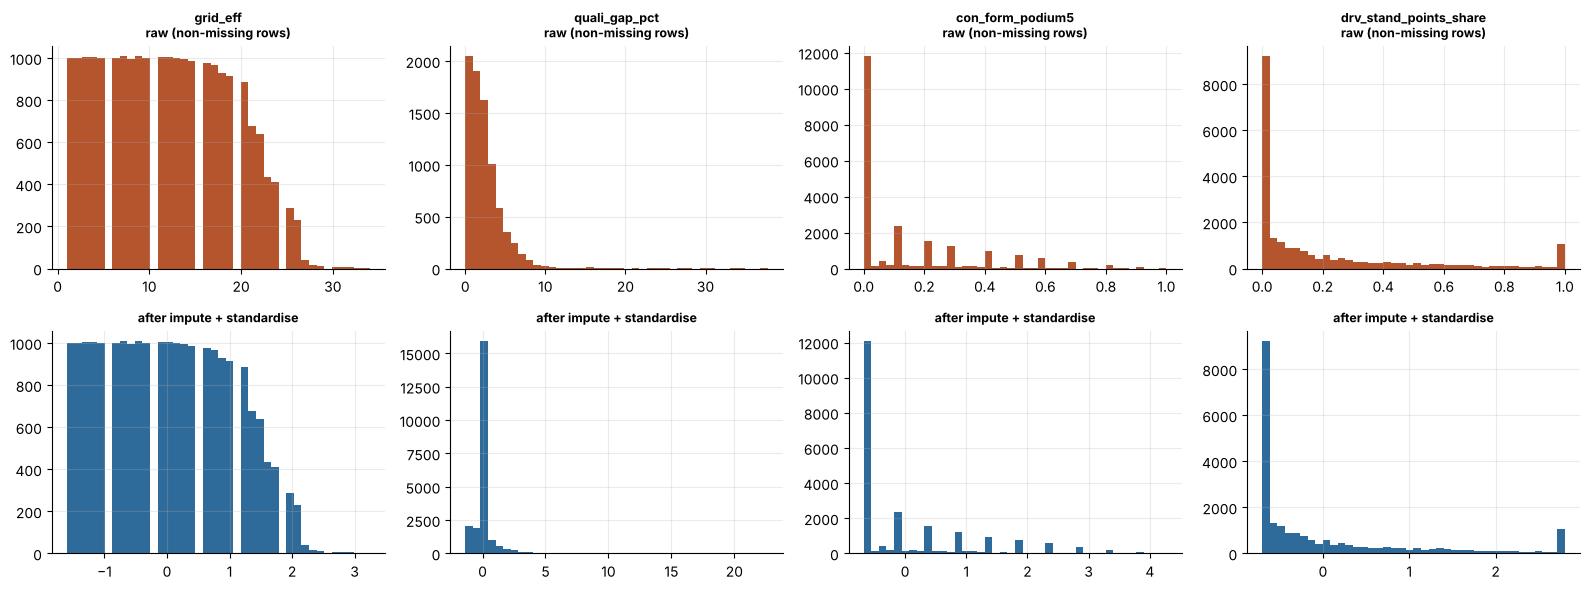

columns after preparation: 27 (11 missing-indicator columns added for features that had gaps in train)


In [ ]:
# Linear models and the neural network need complete, comparable-scale inputs: median-impute (+ a missing indicator), then standardise.
# Tree models (random forest, gradient boosting) take the raw values and handle NaN themselves.
# Both are FITTED ON TRAIN ROWS ONLY and then applied to validation/test (see the order experiments below).
prep = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()).fit(train_df[FEATURES])
prep_names = list(prep.get_feature_names_out(FEATURES))
Z_train = pd.DataFrame(prep.transform(train_df[FEATURES]), columns=prep_names, index=train_df.index)

raw_stats = train_df[FEATURES].agg(["min", "max", "mean", "std"]).T
raw_stats["% missing"] = 100 * train_df[FEATURES].isna().mean()
prepared_stats = Z_train[FEATURES].agg(["min", "max", "mean", "std"]).T
ranges = raw_stats.join(prepared_stats, lsuffix=" (raw)", rsuffix=" (prepared)").round(2)
display(ranges[["min (raw)", "max (raw)", "mean (raw)", "% missing", "mean (prepared)", "std (prepared)"]])

show = ["grid_eff", "quali_gap_pct", "con_form_podium5", "drv_stand_points_share"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, c in enumerate(show):
    axes[0, j].hist(train_df[c].dropna(), bins=40, color=BEFORE); axes[0, j].set_title(f"{c}\nraw (non-missing rows)", fontsize=9)
    axes[1, j].hist(Z_train[c], bins=40, color=AFTER); axes[1, j].set_title("after impute + standardise", fontsize=9)
plt.tight_layout(); plt.show()
print("columns after preparation:", len(prep_names), f"({len(prep_names) - len(FEATURES)} missing-indicator columns added for features that had gaps in train)")

After prep, linear-model features are mean 0 / std 1. Qualifying shows a big spike at the imputed median (~63% missing in train) — that is why indicator columns exist, and why tree models (which see real NaNs) are a useful comparison.


## 3.12 Preprocessing experiments

Three controlled checks (validation + bootstrap; test still untouched):

1. **Where to fit imputer/scaler:** train only (correct) vs train+validation (leaky).
2. **Order for `grid_minus_quali`:** engineer then impute (NaN stays “unknown”) vs impute quali to grid first then subtract (penalty becomes 0 when quali was missing).
3. **Impute→scale vs scale→impute:** checks whether every column really ends at std ≈ 1.

We keep the order that is correct in principle even when score differences are tiny.


In [ ]:
# Experiment 1 (leakage check): WHERE is the imputer / scaler fitted? Train rows only, or train + validation rows?
def logistic_val(fit_rows):
    pre = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()).fit(fit_rows[FEATURES])
    clf = LogisticRegression(max_iter=3000).fit(pre.transform(train_df[FEATURES]), train_df[TARGET])
    p = clf.predict_proba(pre.transform(val_df[FEATURES]))[:, 1]
    return {"val ROC-AUC": round(roc_auc_score(val_df[TARGET], p), 4), "val PR-AUC": round(average_precision_score(val_df[TARGET], p), 4)}

exp1 = pd.DataFrame({"fit on train only (correct)": logistic_val(train_df),
                     "fit on train + validation rows (leaks validation statistics)": logistic_val(pd.concat([train_df, val_df]))}).T

# shared tools: backtest and validation score for any model-making function, on any version of the data
def backtest_df(frame, make_model):
    ys, ps = [], []
    for a, b in BLOCKS:
        trn, blk = frame[frame.year < a], frame[frame.year.between(a, b)]
        m = make_model().fit(trn[FEATURES], trn[TARGET]); ps.append(m.predict_proba(blk[FEATURES])[:, 1]); ys.append(blk[TARGET].values)
    return round(average_precision_score(np.concatenate(ys), np.concatenate(ps)), 3)

def val_predictions(frame_tr, frame_va, make_model):
    return make_model().fit(frame_tr[FEATURES], frame_tr[TARGET]).predict_proba(frame_va[FEATURES])[:, 1]

# Experiment 2: impute BEFORE or AFTER engineering a derived feature?
#   A) engineer first, impute later:  grid_minus_quali = NaN where qualifying is missing, then median-impute
#   B) impute first, engineer later:  quali_pos falls back to the grid slot where missing, THEN grid_minus_quali = grid − quali_pos (= 0)
def impute_first(df):
    d = df.copy(); d["quali_pos"] = d.quali_pos.fillna(d.grid_eff); d["grid_minus_quali"] = d.grid_eff - d.quali_pos
    return d

exp2, p_exp2 = {}, {}
for label, ftr, fva in [("A  engineer first, impute later", train_df, val_df), ("B  impute (fall back to grid) first, engineer later", impute_first(train_df), impute_first(val_df))]:
    p_exp2[label] = {kind: val_predictions(ftr, fva, maker) for kind, maker in [("linear", make_linear), ("hgb", make_hgb)]}
    exp2[label] = {"linear backtest PR-AUC": backtest_df(ftr, make_linear), "linear validation PR-AUC": round(average_precision_score(val_df[TARGET], p_exp2[label]["linear"]), 3),
                   "hgb backtest PR-AUC": backtest_df(ftr, make_hgb), "hgb validation PR-AUC": round(average_precision_score(val_df[TARGET], p_exp2[label]["hgb"]), 3)}
exp2 = pd.DataFrame(exp2).T
a, b = list(p_exp2)
exp2.loc["validation change B − A [95% interval]"] = ["", change_text(val_df.raceId, val_df[TARGET], p_exp2[b]["linear"], p_exp2[a]["linear"]),
                                                      "", change_text(val_df.raceId, val_df[TARGET], p_exp2[b]["hgb"], p_exp2[a]["hgb"])]

# Experiment 3: impute -> scale (ours) versus scale -> impute
ORDERS = {"impute → scale (ours)": lambda: make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
          "scale → impute": lambda: make_pipeline(StandardScaler(), SimpleImputer(strategy="median", add_indicator=True))}
exp3, p_exp3 = {}, {}
for label, make_prep in ORDERS.items():
    Z_check = make_prep().fit(train_df[FEATURES]).transform(train_df[FEATURES])
    make_model = lambda make_prep=make_prep: make_pipeline(make_prep(), LogisticRegression(max_iter=3000))
    p_exp3[label] = val_predictions(train_df, val_df, make_model)
    exp3[label] = {"std of quali_pos after preparation": round(Z_check[:, FEATURES.index("quali_pos")].std(), 2),
                   "std of the 'was missing' columns": round(Z_check[:, len(FEATURES):].std(axis=0).mean(), 2),
                   "linear backtest PR-AUC": backtest_df(train_df, make_model),
                   "linear validation PR-AUC": round(average_precision_score(val_df[TARGET], p_exp3[label]), 3)}
exp3 = pd.DataFrame(exp3).T
a, b = list(p_exp3)
print("Experiment 3, validation change (scale → impute) − (impute → scale):", change_text(val_df.raceId, val_df[TARGET], p_exp3[b], p_exp3[a]))
display(exp1); display(exp2); display(exp3)

Experiment 3, validation change (scale → impute) − (impute → scale): -0.001 [-0.002, +0.000]


,val ROC-AUC,val PR-AUC
fit on train only (correct),0.9324,0.7328
fit on train + validation rows (leaks validation statistics),0.9323,0.7325


,linear backtest PR-AUC,linear validation PR-AUC,hgb backtest PR-AUC,hgb validation PR-AUC
"A engineer first, impute later",0.686,0.733,0.688,0.705
"B impute (fall back to grid) first, engineer later",0.685,0.731,0.688,0.699
validation change B − A [95% interval],,"-0.002 [-0.006, +0.002]",,"-0.006 [-0.014, +0.007]"


,std of quali_pos after preparation,std of the 'was missing' columns,linear backtest PR-AUC,linear validation PR-AUC
impute → scale (ours),1.00,1.00,0.686,0.733
scale → impute,0.61,0.23,0.687,0.732


* Exp 1: leaky fit barely changes the score here, but we still fit on **train only**.
* Exp 2: no clear winner → keep **engineer first, impute later** (unknown stays unknown).
* Exp 3: scale→impute breaks “std = 1” for sparse columns → keep **impute → scale**.


---
# Part 4: Predictive Modeling

**Task:** binary classification. For every driver start, predict whether he finishes on the podium, using only the 16 pre-race features from Part 3. Only about 1 in 7 rows is positive.

**What stays identical for every model (so scores are directly comparable)**
* the **same rows** (`train_df`, `val_df`, `test_df` from 3.10) and the **same 16 features**
* the **same split** (train ≤ 2019, validation 2020–21, test ≥ 2022)
* the **same metrics** and the same way of choosing the probability threshold

**How we avoid touching the test set**
1. Each model family is tuned over a small grid, scored **only on validation PR-AUC**.
2. The chosen configuration is *registered*. Its F1 threshold is picked from **validation** predictions.
3. **Test predictions are computed in 4.7, after everything above is frozen.**

**Models**

| # | Model | Role |
|---|---|---|
| 0 | Rule "grid ≤ 3" | no learning, the floor to beat |
| 1 | Logistic regression, grid only | simplest statistical baseline |
| 2 | Logistic regression, 16 features | statistical model |
| 3 | Random forest | statistical model (non-linear, bagging) |
| 4 | Gradient boosting | statistical model (non-linear, boosting) |
| 5 | Shallow neural network (1–2 hidden layers, Keras) | neural network |

Every configuration we tried is kept in `tune_log` and plotted in 4.6, so the comparison can be checked.

## 4.0 Metrics, threshold and bookkeeping

**Metrics (all computed for every model, on train, validation and test)**

| Metric | What it tells us | Depends on a threshold? |
|---|---|---|
| **PR-AUC** (average precision) | how well the model ranks true podium finishers above everyone else, focused on the positives | no |
| **ROC-AUC** | overall separation of the two classes | no |
| **F1** | balance of precision and recall at the chosen threshold | yes |
| **Precision** | of the drivers we call podium, how many really podium | yes |
| **Recall** | of the real podium finishers, how many we find | yes |

**Primary metric: PR-AUC.** The positive class is rare (≈14%) and it is the class we care about. ROC-AUC gets generous credit for correctly rejecting the many easy negatives (a driver starting 18th), so it stays high even for a weak model. PR-AUC does not. **Secondary: ROC-AUC** (threshold-free overall separation). F1, precision and recall describe *one operating point*, so they are reported but not used to rank models.

Five metrics: ROC-AUC, PR-AUC, F1, precision and recall (the last three at the same threshold).

**Threshold:** the probability cut-off that **maximises F1 on the validation predictions**. Never the test set, never a fixed 0.5 (with a 14% base rate, 0.5 would miss many podium finishers).

**Extra, race-level check (`top-3 per race`):** in each race, take the three drivers the model ranks highest and measure how many are real podium finishers. This is a natural reading of the task (a race has exactly three podium places) and it needs no threshold.

**Is a difference between two models real?** Both are scored on the same races, so we use the **paired race bootstrap** from 3.7 (resample whole races, score both models on the same resample). A difference is "clear" only if its 95% interval excludes 0.

**Caveat about validation:** hyperparameters, the threshold and early stopping all use validation data, so **validation scores are slightly optimistic**. The test scores are the unbiased estimate.

In [ ]:
# ---------- evaluation tools (used by every model) ----------
def pick_threshold(y, p):
    """probability cut-off that maximises F1. Called ONLY with validation labels/predictions."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    return float(thr[np.argmax(f1)])

def score_all(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "F1": f1_score(y, yhat),
            "Precision": precision_score(y, yhat, zero_division=0), "Recall": recall_score(y, yhat)}

def top3_hit_rate(df, p):
    """race-level view: pick the 3 drivers with the highest predicted probability in every race. Share of them who really podiumed."""
    d = df[["raceId", TARGET]].assign(p=np.asarray(p)).sort_values(["raceId", "p"], ascending=[True, False])
    return d.groupby("raceId").head(3)[TARGET].mean()

SPLITS = {"train": train_df, "validation": val_df, "test": test_df}
REGISTRY = {}      # model name -> {"predict": function(df) -> probabilities, "thr": validation-chosen threshold, "family": ...}

def register(name, family, predict, thr=None):
    """Freeze a finished model. Its threshold comes from VALIDATION predictions only. Test predictions are NOT computed here."""
    thr = pick_threshold(val_df[TARGET], predict(val_df)) if thr is None else thr
    REGISTRY[name] = {"predict": predict, "thr": thr, "family": family}

def val_pr(p):
    """the ONLY score used while tuning: validation PR-AUC"""
    return average_precision_score(val_df[TARGET], p)

tune_log = []      # every configuration we tried, for the notebook record
CHOSEN = {}        # model name -> chosen settings (for the summary table)

## 4.1 Baselines

A baseline is the simplest reasonable approach. It tells us whether a complex model **earns** its complexity.

* **Baseline 0, a rule with no learning:** "predict a podium if the driver starts in the top 3". The ranking score is 1 ÷ grid slot.
* **Baseline 1, logistic regression on the grid slot alone.** The simplest statistical model. This is the **required baseline** for the comparison.

In [ ]:
# Baseline 0: a plain rule, no learning. "Predict podium if the driver starts in the top 3". Ranking score = 1 / grid slot.
rule = lambda df: 1.0 / df.grid_eff.values
register("Rule: grid ≤ 3", "baseline", rule, thr=1 / 3)

# Baseline 1: the simplest reasonable statistical model. Logistic regression on the starting slot alone.
lr_grid = make_linear().fit(train_df[["grid_eff"]], train_df[TARGET])
register("Logistic regression (grid only)", "baseline", lambda df: lr_grid.predict_proba(df[["grid_eff"]])[:, 1])
CHOSEN.update({"Rule: grid ≤ 3": "no learning", "Logistic regression (grid only)": "grid_eff only"})

pd.DataFrame({n: {s: round(average_precision_score(d[TARGET], REGISTRY[n]["predict"](d)), 3) for s, d in [("train", train_df), ("validation", val_df)]}
              for n in REGISTRY}).T.rename(columns=lambda c: f"{c} PR-AUC")

,train PR-AUC,validation PR-AUC
Rule: grid ≤ 3,0.5,0.648
Logistic regression (grid only),0.5,0.648


The two baselines score **exactly the same**. This is not a bug: logistic regression on one feature is a monotone function of it, so it ranks drivers exactly like the rule, and its F1-optimal threshold (a probability of 0.435) selects exactly the drivers starting in the top 3. The number to beat is **validation PR-AUC 0.648**. We keep both rows here as a check; the summary table (4.12) lists them once.

## 4.2 Model 1: logistic regression (16 features)

**How it works:** it computes a weighted sum of the (standardised) features, then squashes that sum into a probability between 0 and 1 with the logistic (S-shaped) function. The weights are learned by maximum likelihood. Features that push towards a podium get positive weights.

**Why we include it:** it is fast, stable, and has no random seed. It is the reference every other model must beat. We tune one knob, **C** (inverse regularisation strength): a small C shrinks the weights and gives a simpler model.

**Limitations**
* The effect of each feature is **linear** (in the standardised value). It cannot represent "pole matters more when the team is also fast", and the steep, curved fall of podium chance with grid slot (3.6a) is only approximated.
* Correlated features (`grid_eff` and `quali_pos`, ρ = 0.98) make individual weights unstable. Predictions stay fine, the weights are not a clean ranking of importance.
* Median-imputed qualifying values for 63% of training rows are a rough patch (3.11).

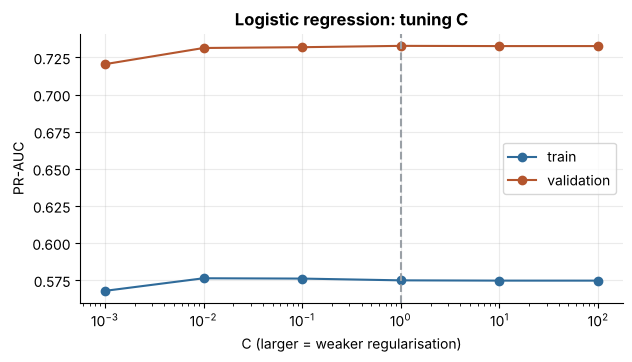

chosen C = 1.0


,model,C,train PR-AUC,val PR-AUC
0,logistic,0.001,0.568,0.720
1,logistic,0.010,0.576,0.731
2,logistic,0.100,0.576,0.732
3,logistic,1.000,0.575,0.733
4,logistic,10.000,0.575,0.733
5,logistic,100.000,0.575,0.733


In [ ]:
# Model 1: logistic regression with all 16 features. One knob: C (inverse regularisation strength). Smaller C = simpler model.
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    m = make_linear(C).fit(train_df[FEATURES], train_df[TARGET])
    rows.append({"model": "logistic", "C": C, "train PR-AUC": average_precision_score(train_df[TARGET], m.predict_proba(train_df[FEATURES])[:, 1]),
                 "val PR-AUC": val_pr(m.predict_proba(val_df[FEATURES])[:, 1])})
lr_tune = pd.DataFrame(rows); tune_log += rows
best_C = lr_tune.loc[lr_tune["val PR-AUC"].idxmax(), "C"]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogx(lr_tune.C, lr_tune["train PR-AUC"], marker="o", color=AFTER, label="train"); ax.semilogx(lr_tune.C, lr_tune["val PR-AUC"], marker="o", color=BEFORE, label="validation")
ax.axvline(best_C, ls="--", color=GREY); ax.set_xlabel("C (larger = weaker regularisation)"); ax.set_ylabel("PR-AUC"); ax.set_title("Logistic regression: tuning C"); ax.legend(); plt.show()

lr_final = make_linear(best_C).fit(train_df[FEATURES], train_df[TARGET])
register("Logistic regression", "statistical", lambda df: lr_final.predict_proba(df[FEATURES])[:, 1])
CHOSEN["Logistic regression"] = f"C = {best_C:g}"
print("chosen C =", best_C)
lr_tune.round(3)

The score is almost flat across C (validation PR-AUC 0.720–0.733), so regularisation barely matters for 16 features and 22,000 rows. C = 1 is chosen (the first of four tied values at 0.733). Train PR-AUC (0.575) is *below* validation: this is not under-fitting but the era effect explained in 4.9.

## 4.3 Model 2a: random forest

**How it works:** it grows 300 decision trees, each on a random sample of the rows and a random subset of the features at each split, and averages their votes. The randomness de-correlates the trees. It captures **non-linearities and interactions** (grid × team form) without any scaling, and it reads NaN directly.

**Tuned:** tree depth {6, 10, unlimited} × minimum rows per leaf {5, 20}.

**Limitations**
* **Deep trees overfit.** An unlimited tree memorises its training rows. That shows as a large gap between train and validation PR-AUC.
* Probabilities from a forest are not well calibrated (they tend to be pulled towards the middle), which matters for the threshold.
* It cannot extrapolate beyond the range of values seen in training.

In [ ]:
# Model 2a: random forest. Many deep, de-correlated trees voting; handles non-linearities and interactions without scaling.
rows = []
for depth in [6, 10, None]:
    for leaf in [5, 20]:
        m = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf, max_features="sqrt", n_jobs=-1, random_state=SEED)
        m.fit(train_df[FEATURES], train_df[TARGET])
        rows.append({"model": "random forest", "max_depth": depth if depth else "none", "min_samples_leaf": leaf,
                     "train PR-AUC": average_precision_score(train_df[TARGET], m.predict_proba(train_df[FEATURES])[:, 1]),
                     "val PR-AUC": val_pr(m.predict_proba(val_df[FEATURES])[:, 1])})
rf_tune = pd.DataFrame(rows); tune_log += rows
best_rf = rf_tune.loc[rf_tune["val PR-AUC"].idxmax()]
rf_final = RandomForestClassifier(n_estimators=300, max_depth=None if best_rf.max_depth == "none" else int(best_rf.max_depth),
                                  min_samples_leaf=int(best_rf.min_samples_leaf), max_features="sqrt", n_jobs=-1,
                                  random_state=SEED).fit(train_df[FEATURES], train_df[TARGET])
register("Random forest", "statistical", lambda df: rf_final.predict_proba(df[FEATURES])[:, 1])
CHOSEN["Random forest"] = f"depth {best_rf.max_depth}, min leaf {int(best_rf.min_samples_leaf)}"
print("chosen:", CHOSEN["Random forest"])
rf_tune.round(3)

chosen: depth 6, min leaf 5


,model,max_depth,min_samples_leaf,train PR-AUC,val PR-AUC
0,random forest,6,5,0.634,0.729
1,random forest,6,20,0.625,0.728
2,random forest,10,5,0.771,0.715
3,random forest,10,20,0.688,0.728
4,random forest,none,5,0.910,0.704
5,random forest,none,20,0.708,0.724


The shallowest forest wins on validation (depth 6, min leaf 5: 0.729), but **four of the six settings are within 0.005 of it**, so the choice is close to a coin flip and can change with the library version or machine. Deeper trees fit the training rows much better (train PR-AUC 0.77 at depth 10, 0.91 unlimited) while validation gets worse (0.715, 0.704): overfitting. There is little structure to find beyond what a smooth model already captures.

## 4.4 Model 2b: gradient boosting

**How it works:** it builds small trees **one after another**, each fitted to the mistakes of the ones before. A small learning rate means each tree only makes a gentle correction. It usually beats a random forest on tabular data, and it handles NaN natively. We use scikit-learn's `HistGradientBoostingClassifier`.

**Tuned:** tree depth {2, 3, 4} × learning rate {0.03, 0.1} × number of trees {100, 300}.

**Limitations**
* More hyperparameters, and more ways to overfit, than logistic regression. On 775 validation rows the "best" configuration is partly luck.
* **Early stopping is switched off** (`early_stopping=False`, asserted in code). Above 10,000 rows scikit-learn would otherwise turn it on by itself, hold out 10% of the training rows and ignore the number of trees, which would make that part of the grid meaningless.
* Also cannot extrapolate beyond training values, and the effect of one feature is hard to read without XAI (Part 6).

In [ ]:
# Model 2b: gradient boosting. Small trees added one after another, each correcting the previous ones' mistakes.
rows = []
for depth in [2, 3, 4]:
    for lr_ in [0.03, 0.1]:
        for n_iter in [100, 300]:
            m = make_hgb(max_depth=depth, learning_rate=lr_, max_iter=n_iter).fit(train_df[FEATURES], train_df[TARGET])
            rows.append({"model": "gradient boosting", "max_depth": depth, "learning_rate": lr_, "n_trees": n_iter,
                         "train PR-AUC": average_precision_score(train_df[TARGET], m.predict_proba(train_df[FEATURES])[:, 1]),
                         "val PR-AUC": val_pr(m.predict_proba(val_df[FEATURES])[:, 1])})
gb_tune = pd.DataFrame(rows); tune_log += rows
best_gb = gb_tune.loc[gb_tune["val PR-AUC"].idxmax()]
gb_final = make_hgb(max_depth=int(best_gb.max_depth), learning_rate=float(best_gb.learning_rate),
                    max_iter=int(best_gb.n_trees)).fit(train_df[FEATURES], train_df[TARGET])
assert gb_final.n_iter_ == int(best_gb.n_trees), "early stopping is off, so every requested tree is built"
register("Gradient boosting", "statistical", lambda df: gb_final.predict_proba(df[FEATURES])[:, 1])
CHOSEN["Gradient boosting"] = f"depth {int(best_gb.max_depth)}, learning rate {best_gb.learning_rate:g}, {int(best_gb.n_trees)} trees"
print("chosen:", CHOSEN["Gradient boosting"])
gb_tune.sort_values("val PR-AUC", ascending=False).round(3).reset_index(drop=True)

chosen: depth 2, learning rate 0.03, 100 trees


,model,max_depth,learning_rate,n_trees,train PR-AUC,val PR-AUC
0,gradient boosting,2,0.03,100,0.587,0.722
1,gradient boosting,3,0.03,100,0.601,0.714
2,gradient boosting,2,0.10,300,0.624,0.707
3,gradient boosting,2,0.10,100,0.601,0.704
4,gradient boosting,2,0.03,300,0.601,0.703
5,gradient boosting,3,0.10,300,0.675,0.703
6,gradient boosting,3,0.10,100,0.623,0.701
7,gradient boosting,4,0.03,100,0.614,0.701
8,gradient boosting,3,0.03,300,0.620,0.697
9,gradient boosting,4,0.03,300,0.645,0.697


Again the **simplest** configuration wins on validation (depth 2, learning rate 0.03, 100 trees: 0.722). The 12 configurations span 0.682–0.722. More trees, deeper trees or a larger learning rate raise the train score (up to 0.754) and lower validation: extra capacity overfits.

## 4.5 Model 3: shallow neural network (Keras)

**How it works:** the same idea as logistic regression, stacked. Each hidden layer is a set of "neurons": every neuron takes a weighted sum of its inputs and passes it through a ReLU (it outputs the sum if positive, otherwise 0). The last layer is one sigmoid neuron that outputs P(podium). Training adjusts all weights with the **Adam** optimiser to minimise **binary cross-entropy**. The hidden layer lets the network bend the relationship, so it is more flexible than logistic regression.

**"Shallow" = 1 or 2 hidden layers.** We try 1 layer (8, 16, 32 units) and 2 layers (16-8, 32-16), each with and without 20% dropout. Dropout randomly switches off neurons while training so the network cannot rely on a single one.

**Choices to know**
* **Input:** the 16 features after the linear-model preparation (impute, indicator, standardise), because networks need complete, same-scale inputs.
* **Regularisation:** L2 penalty (1e-4) on the weights, plus **early stopping**: training stops when validation loss has not improved for 15 epochs, and the best epoch's weights are restored.
* **Library:** Keras.

**Limitations**
* **Random start:** two runs give slightly different scores (measured in 4.5b).
* **Small data, noisy signal:** 22,000 rows with a weak signal beyond the grid. A network has no real advantage over logistic regression here.
* It is the least transparent model: its weights say nothing by themselves (XAI in Part 6).
* **Early stopping uses the validation loss**, so the validation score is mildly optimistic.

chosen: 8 | dropout 0.0 | epochs run 107


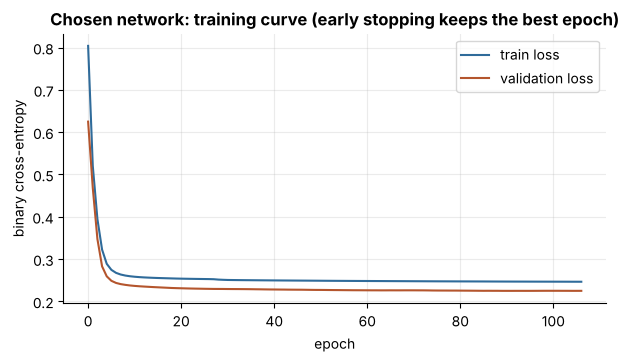

,model,hidden layers,units,dropout,epochs run,train PR-AUC,val PR-AUC
0,neural network,1,8,0.0,107,0.591,0.744
1,neural network,1,16,0.0,160,0.602,0.741
2,neural network,1,32,0.0,78,0.603,0.736
3,neural network,1,16,0.2,57,0.592,0.734
4,neural network,2,32-16,0.2,56,0.600,0.732
5,neural network,2,16-8,0.0,79,0.599,0.732
6,neural network,2,16-8,0.2,66,0.593,0.732
7,neural network,1,8,0.2,67,0.588,0.727
8,neural network,1,32,0.2,84,0.600,0.726
9,neural network,2,32-16,0.0,117,0.617,0.723


In [ ]:
# Model 3: shallow feed-forward neural network (Keras). Inputs = the same 16 features after the linear-model preparation (impute + standardise).
Z = {s: prep.transform(d[FEATURES]) for s, d in SPLITS.items()}          # `prep` was fitted on train rows only (3.11)
y_tr, y_va = train_df[TARGET].values, val_df[TARGET].values

def build_nn(n_in, units, dropout, l2=1e-4, lr=1e-3):
    layers = [keras.Input(shape=(n_in,))]
    for u in units:                                                     # 1 or 2 hidden layers = "shallow"
        layers.append(keras.layers.Dense(u, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)))
        if dropout:
            layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(1, activation="sigmoid"))          # one output = P(podium)
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy")
    return model

def fit_nn(units, dropout, seed=SEED):
    keras.utils.set_random_seed(seed)
    model = build_nn(Z["train"].shape[1], units, dropout)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)   # stops when validation loss stops improving
    hist = model.fit(Z["train"], y_tr, validation_data=(Z["validation"], y_va), epochs=200, batch_size=256, callbacks=[stop], verbose=0)
    return model, hist

rows, nn_models = [], {}
for units in [(8,), (16,), (32,), (16, 8), (32, 16)]:
    for dropout in [0.0, 0.2]:
        model, hist = fit_nn(units, dropout)
        p_tr, p_va = model.predict(Z["train"], verbose=0).ravel(), model.predict(Z["validation"], verbose=0).ravel()
        rows.append({"model": "neural network", "hidden layers": len(units), "units": "-".join(map(str, units)), "dropout": dropout,
                     "epochs run": len(hist.history["loss"]), "train PR-AUC": average_precision_score(y_tr, p_tr), "val PR-AUC": val_pr(p_va)})
        nn_models[(units, dropout)] = (model, hist)
nn_tune = pd.DataFrame(rows); tune_log += rows
best = nn_tune.loc[nn_tune["val PR-AUC"].idxmax()]
best_key = ([k for k in nn_models if "-".join(map(str, k[0])) == best.units and k[1] == best.dropout][0])
nn_final, nn_hist = nn_models[best_key]
print("chosen:", best.units, "| dropout", best.dropout, "| epochs run", best["epochs run"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(nn_hist.history["loss"], color=AFTER, label="train loss"); ax.plot(nn_hist.history["val_loss"], color=BEFORE, label="validation loss")
ax.set_xlabel("epoch"); ax.set_ylabel("binary cross-entropy"); ax.set_title("Chosen network: training curve (early stopping keeps the best epoch)"); ax.legend(); plt.show()

register("Neural network", "neural", lambda df: nn_final.predict(prep.transform(df[FEATURES]), verbose=0).ravel())
CHOSEN["Neural network"] = f"{best.units} units, dropout {best.dropout:g}"
nn_tune.sort_values("val PR-AUC", ascending=False).round(3).reset_index(drop=True)

All 10 variants land within 0.021 PR-AUC of each other on validation (0.723–0.744). The best is **one hidden layer of 8 units, no dropout** (0.744, stopped at epoch 107). The largest network (32-16, no dropout) has the highest train score (0.617) and the lowest validation score (0.723), the same overfitting pattern as the forest and boosting.

### 4.5b How much does the random start matter?

We re-train the chosen architecture with 5 different seeds and look at the spread of the validation score.

In [ ]:
# A network starts from random weights, so its score moves a little from run to run. How much? Re-train the chosen architecture with 5 seeds.
units_best, drop_best = best_key
seed_rows = []
for s in range(5):
    m, _ = fit_nn(units_best, drop_best, seed=SEED + s)
    p = m.predict(Z["validation"], verbose=0).ravel()
    seed_rows.append({"seed": SEED + s, "val ROC-AUC": roc_auc_score(y_va, p), "val PR-AUC": average_precision_score(y_va, p)})
seeds = pd.DataFrame(seed_rows).set_index("seed")
display(seeds.round(3))
print(f"validation PR-AUC over 5 seeds: {seeds['val PR-AUC'].mean():.3f} ± {seeds['val PR-AUC'].std():.3f}")

,val ROC-AUC,val PR-AUC
seed,,
42,0.931,0.744
43,0.933,0.735
44,0.932,0.735
45,0.932,0.746
46,0.930,0.720


validation PR-AUC over 5 seeds: 0.736 ± 0.010


Validation PR-AUC over 5 seeds is **0.736 ± 0.010** (range 0.720–0.746). The registered network (seed 42, 0.744) is one of the better draws. Choosing the best of 10 variants on validation flatters the winner, so **part of its validation score is luck**, and the seed-to-seed spread is as large as the differences between most models.

## 4.6 Every configuration we tried

One dot per configuration, validation PR-AUC. The circle marks the one chosen for each model. In total we compared **34 configurations across 4 model families** (plus the two baselines).

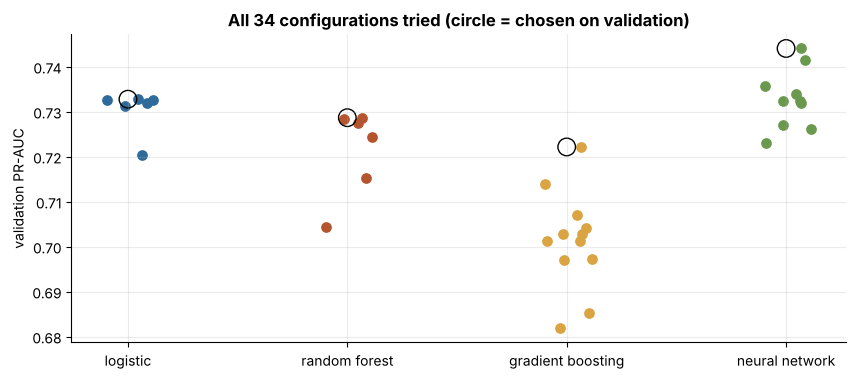

,count,min,max
model,,,
logistic,6,0.720,0.733
random forest,6,0.704,0.729
gradient boosting,12,0.682,0.722
neural network,10,0.723,0.744


In [ ]:
# every configuration we tried, on one chart (validation PR-AUC, higher is better)
tl = pd.DataFrame(tune_log)
fig, ax = plt.subplots(figsize=(10, 4))
for i, (name, g) in enumerate(tl.groupby("model", sort=False)):
    ax.scatter(np.full(len(g), i) + np.random.default_rng(SEED).uniform(-.12, .12, len(g)), g["val PR-AUC"], s=45, color=[AFTER, BEFORE, ACCENT, "#6A994E"][i])
    ax.scatter(i, g["val PR-AUC"].max(), s=160, facecolors="none", edgecolors="k")
ax.set_xticks(range(tl.model.nunique())); ax.set_xticklabels(list(tl.groupby("model", sort=False).groups)); ax.set_ylabel("validation PR-AUC")
ax.set_title(f"All {len(tl)} configurations tried (circle = chosen on validation)"); plt.show()
tl.groupby("model", sort=False)["val PR-AUC"].agg(["count", "min", "max"]).round(3)

The four families overlap (logistic 0.720–0.733, forest 0.704–0.729, boosting 0.682–0.722, network 0.723–0.744). **No family is clearly better on validation.**

## 4.7 Final comparison: train, validation and test

All choices are frozen. **Only now** do we compute predictions on the test seasons. The first table shows the five metrics for every model on every split (F1, precision and recall at the validation-chosen threshold), the thresholds and the race-level top-3 hit rate. The second table tests the test-set differences with the paired race bootstrap (3.7).

In [ ]:
# ---- all choices are frozen above; only now do we compute test predictions ----
PRED = {n: {s: r["predict"](d) for s, d in SPLITS.items()} for n, r in REGISTRY.items()}
rows = []
for n, r in REGISTRY.items():
    for s, d in SPLITS.items():
        rows.append({"model": n, "split": s, **score_all(d[TARGET], PRED[n][s], r["thr"]), "threshold": r["thr"], "top-3 per race": top3_hit_rate(d, PRED[n][s])})
scores = pd.DataFrame(rows)
table = scores.pivot(index="model", columns="split", values=["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"])
table = table.reindex(columns=pd.MultiIndex.from_product([["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"], ["train", "validation", "test"]]))
table = table.loc[list(REGISTRY)].round(3)
thr_table = scores[scores.split == "validation"].set_index("model")["threshold"].round(3)
top3 = scores.pivot(index="model", columns="split", values="top-3 per race").loc[list(REGISTRY), ["train", "validation", "test"]].round(3)
display(table); display(thr_table.to_frame("F1-optimal threshold (chosen on validation)").T)
display(top3.rename(columns=lambda c: f"top-3 per race, {c}"))

PR-AUC                   ROC-AUC             \
                                 train validation   test   train validation   
model                                                                         
Rule: grid ≤ 3                   0.500      0.648  0.647   0.883      0.910   
Logistic regression (grid only)  0.500      0.648  0.647   0.883      0.910   
Logistic regression              0.575      0.733  0.718   0.901      0.932   
Random forest                    0.634      0.729  0.712   0.916      0.931   
Gradient boosting                0.587      0.722  0.704   0.905      0.928   
Neural network                   0.591      0.744  0.715   0.906      0.931   

                                           F1                   Precision  \
                                  test  train validation   test     train   
model                                                                       
Rule: grid ≤ 3                   0.913  0.544      0.695  0.649     0.547   
Logistic regression (grid only)  0.913  0.544      0.695  0.649     0.547   
Logistic regression              0.937  0.570      0.706  0.686     0.567   
Random forest                    0.940  0.613      0.699  0.671     0.543   
Gradient boosting                0.938  0.586      0.710  0.674     0.549   
Neural network                   0.937  0.557      0.710  0.675     0.586   

                                                  Recall                    
                                validation   test  train validation   test  
model                                                                       
Rule: grid ≤ 3                       0.698  0.650  0.541      0.692  0.647  
Logistic regression (grid only)      0.698  0.650  0.541      0.692  0.647  
Logistic regression                  0.694  0.662  0.574      0.718  0.711  
Random forest                        0.659  0.595  0.704      0.744  0.770  
Gradient boosting                    0.719  0.630  0.627      0.701  0.725  
Neural network                       0.719  0.659  0.531      0.701  0.691

model,Rule: grid ≤ 3,Logistic regression (grid only),Logistic regression,Random forest,Gradient boosting,Neural network
F1-optimal threshold (chosen on validation),0.333,0.435,0.375,0.312,0.335,0.42


split,"top-3 per race, train","top-3 per race, validation","top-3 per race, test"
model,,,
Rule: grid ≤ 3,0.547,0.701,0.652
Logistic regression (grid only),0.547,0.701,0.652
Logistic regression,0.557,0.692,0.662
Random forest,0.591,0.692,0.657
Gradient boosting,0.563,0.701,0.652
Neural network,0.563,0.684,0.652


In [ ]:
# Are the test differences bigger than chance? Paired bootstrap over the 68 test races (both models scored on the same resample).
# This only REPORTS; nothing is chosen from it.
cmp_rows = []
for n in [m for m in REGISTRY if REGISTRY[m]["family"] != "baseline"]:
    for ref in ["Logistic regression (grid only)", "Logistic regression"]:
        if n != ref:
            d, low, high = paired_race_bootstrap(test_df.raceId, test_df[TARGET], PRED[n]["test"], PRED[ref]["test"])
            cmp_rows.append({"model": n, "compared with": ref, "Δ test PR-AUC": round(d, 3),
                             "95% interval": f"{low:+.3f} to {high:+.3f}", "clear?": "yes" if low > 0 or high < 0 else "no"})
pd.DataFrame(cmp_rows).set_index(["model", "compared with"])

Δ test PR-AUC  \
model               compared with                                    
Logistic regression Logistic regression (grid only)          0.071   
Random forest       Logistic regression (grid only)          0.064   
                    Logistic regression                     -0.007   
Gradient boosting   Logistic regression (grid only)          0.056   
                    Logistic regression                     -0.014   
Neural network      Logistic regression (grid only)          0.067   
                    Logistic regression                     -0.003   

                                                         95% interval clear?  
model               compared with                                             
Logistic regression Logistic regression (grid only)  +0.022 to +0.119    yes  
Random forest       Logistic regression (grid only)  +0.026 to +0.103    yes  
                    Logistic regression              -0.022 to +0.010     no  
Gradient boosting   Logistic regression (grid only)  +0.015 to +0.095    yes  
                    Logistic regression              -0.038 to +0.005     no  
Neural network      Logistic regression (grid only)  +0.026 to +0.102    yes  
                    Logistic regression              -0.022 to +0.014     no

* **Every model that uses the features beats the grid-only baseline, clearly.** Test PR-AUC is 0.718 (logistic), 0.715 (network), 0.712 (forest) and 0.704 (boosting), against **0.647**: a gain of +0.056 to +0.071, and every 95% interval excludes 0. Test ROC-AUC is 0.937–0.940 against 0.913.
* **The four models cannot be separated.** Their differences from logistic regression are −0.003 to −0.014, and every interval includes 0. We make no claim that one family is better.
* **Validation flattered the network.** It had the highest validation PR-AUC (0.744) but not the highest test score: choosing among noisy candidates on a small validation set flatters the winner (4.5b).
* **F1 at the validation-chosen threshold (test):** 0.671–0.686 against 0.649 for the baseline. The random forest finds the most podium finishers (recall 0.77) but has the lowest precision (0.60). The thresholds (0.31–0.42) are far below 0.5, as expected with a 15% base rate.
* **Race level:** taking each model's top 3 per race hits 0.652–0.662 on test, against **0.652** for the top 3 on the grid. The models rank *probabilities* across all drivers better (PR-AUC, ROC-AUC), but the grid order already holds almost everything needed to name the three most likely finishers.
* **Which model goes forward?** Since none is clearly better, we do not crown a winner by score. **Part 5** uses logistic regression, because retraining it gives identical results, so every change comes from the removed features. **Part 6** explains the neural network, the least transparent model.

## 4.8 Comparison plots

Left: PR-AUC on each split. Middle and right: precision-recall and ROC curves on the **unseen test seasons**. The dashed line in the middle plot is the base rate (what a random guess achieves).

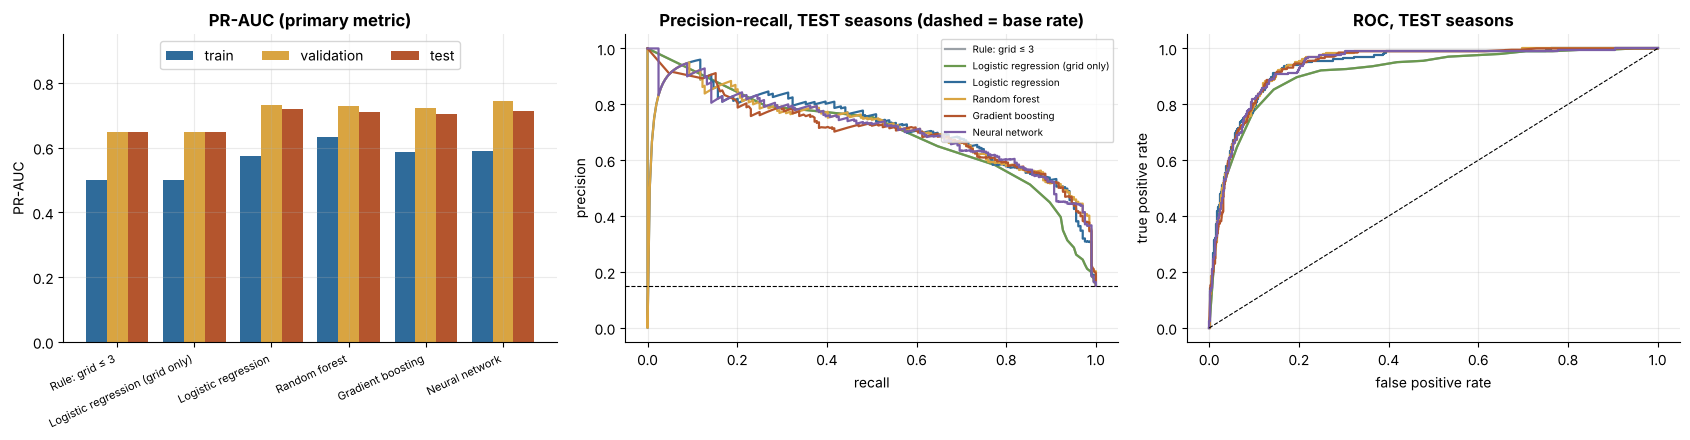

In [ ]:
models = [n for n in REGISTRY if REGISTRY[n]["family"] != "baseline"] + ["Rule: grid ≤ 3"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
x = np.arange(len(REGISTRY)); w = 0.27
for k, s in enumerate(["train", "validation", "test"]):
    axes[0].bar(x + (k - 1) * w, [scores[(scores.model == n) & (scores.split == s)]["PR-AUC"].iloc[0] for n in REGISTRY], w, color=SPLIT_COLORS[s], label=s)
axes[0].set_xticks(x); axes[0].set_xticklabels(list(REGISTRY), rotation=25, ha="right", fontsize=8); axes[0].set_ylabel("PR-AUC"); axes[0].set_title("PR-AUC (primary metric)"); axes[0].set_ylim(0, 0.95); axes[0].legend(ncol=3, loc="upper center")
colors = dict(zip(REGISTRY, [GREY, "#6A994E", AFTER, ACCENT, BEFORE, "#7B5EA7"]))
for n in REGISTRY:
    y, p = test_df[TARGET], PRED[n]["test"]
    pr, rc, _ = precision_recall_curve(y, p); fpr, tpr, _ = roc_curve(y, p)
    axes[1].plot(rc, pr, color=colors[n], label=n, lw=1.6); axes[2].plot(fpr, tpr, color=colors[n], lw=1.6)
axes[1].axhline(test_df[TARGET].mean(), ls="--", color="k", lw=.8); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision-recall, TEST seasons (dashed = base rate)")
axes[2].plot([0, 1], [0, 1], "k--", lw=.8); axes[2].set_xlabel("false positive rate"); axes[2].set_ylabel("true positive rate"); axes[2].set_title("ROC, TEST seasons")
axes[1].legend(fontsize=7, loc="upper right"); plt.tight_layout(); plt.show()

The learned models' curves lie almost on top of each other. The baseline sits below them in both plots, and the rule and the grid-only logistic model have identical curves, so only one of them is visible. All curves stay far above the base rate.

## 4.9 Why is train PR-AUC lower than validation? Scores by era

Train scores (0.50–0.63) sit *below* validation and test (0.65–0.74). That is the opposite of overfitting, so we check the cause: we score one model **era by era** with the same features. If early eras are harder to predict, the training set (which contains them) will look worse.

We use the best non-baseline model on **validation** PR-AUC (chosen in code, before any test number is read).

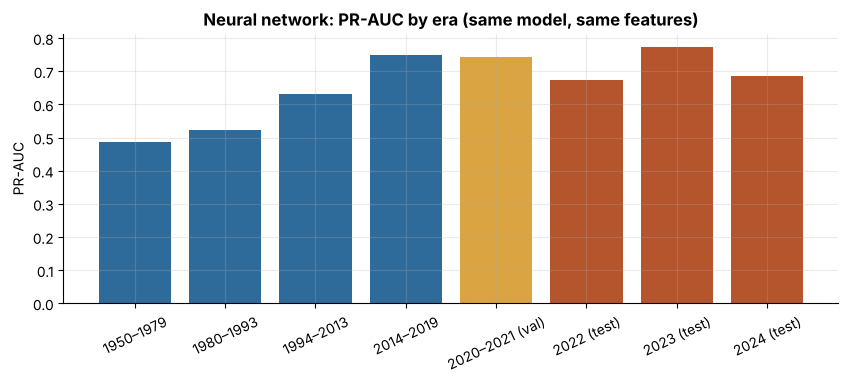

best non-baseline model on VALIDATION PR-AUC: Neural network


,rows,podium %,ROC-AUC,PR-AUC
1950–1979,6788.0,14.3,0.867,0.486
1980–1993,5578.0,11.8,0.904,0.524
1994–2013,7622.0,13.7,0.919,0.632
2014–2019,2471.0,14.7,0.951,0.750
2020–2021 (val),775.0,15.1,0.931,0.744
2022 (test),439.0,15.0,0.943,0.674
2023 (test),437.0,15.1,0.928,0.774
2024 (test),476.0,15.1,0.934,0.686


In [ ]:
# Why is train PR-AUC (≈0.6) lower than validation (≈0.7)? Same model, scored era by era.
best_name = scores[(scores.split == "validation") & ~scores.model.isin(["Rule: grid ≤ 3", "Logistic regression (grid only)"])].sort_values("PR-AUC", ascending=False).model.iloc[0]
d = pd.concat([train_df.assign(p=PRED[best_name]["train"]), val_df.assign(p=PRED[best_name]["validation"]), test_df.assign(p=PRED[best_name]["test"])])
eras = {"1950–1979": (1950, 1979), "1980–1993": (1980, 1993), "1994–2013": (1994, 2013), "2014–2019": (2014, 2019), "2020–2021 (val)": (2020, 2021),
        "2022 (test)": (2022, 2022), "2023 (test)": (2023, 2023), "2024 (test)": (2024, 2024)}
era = pd.DataFrame({k: {"rows": int(m.sum()), "podium %": round(100 * d[m].podium.mean(), 1), "ROC-AUC": round(roc_auc_score(d[m].podium, d[m].p), 3),
                        "PR-AUC": round(average_precision_score(d[m].podium, d[m].p), 3)} for k, (a, b) in eras.items() for m in [d.year.between(a, b)]}).T
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(era.index, era["PR-AUC"], color=[AFTER] * 4 + [ACCENT] + [BEFORE] * 3); ax.tick_params(axis="x", rotation=25)
ax.set_ylabel("PR-AUC"); ax.set_title(f"{best_name}: PR-AUC by era (same model, same features)"); plt.show()
print("best non-baseline model on VALIDATION PR-AUC:", best_name)
era

PR-AUC rises steadily with the era: **0.49 (1950–79), 0.52 (1980–93), 0.63 (1994–2013), 0.75 (2014–19)**, and 0.74 on validation; ROC-AUC follows (0.87 → 0.95). Early F1 was less predictable: cars broke down often, so a good grid slot converted far less reliably (3.6a). **55% of the training rows come from 1950–1993**, which pulls the training score down. This is an era effect, not overfitting.

**The test seasons look like modern F1:** 0.67 (2022), 0.77 (2023), 0.69 (2024). One season has only ~440–480 rows, so single-year numbers move a lot and should not be over-read.

## 4.10 What the predictions look like on the test seasons

Counts of correct and incorrect calls at each model's threshold on the 1,352 test rows (204 real podium finishers).

In [ ]:
# What do the thresholded predictions look like on the unseen test seasons? (race-level reading in the last column of the table above)
rows = {}
for n in [x for x in REGISTRY if x != "Rule: grid ≤ 3"][:]:
    yhat = (PRED[n]["test"] >= REGISTRY[n]["thr"]).astype(int); y = test_df[TARGET].values
    rows[n] = {"true podium found": int(((yhat == 1) & (y == 1)).sum()), "podium missed": int(((yhat == 0) & (y == 1)).sum()),
               "false alarms": int(((yhat == 1) & (y == 0)).sum()), "correct non-podium": int(((yhat == 0) & (y == 0)).sum())}
rows["Rule: grid ≤ 3"] = {"true podium found": int(((test_df.grid_eff <= 3) & (test_df[TARGET] == 1)).sum()), "podium missed": int(((test_df.grid_eff > 3) & (test_df[TARGET] == 1)).sum()),
                          "false alarms": int(((test_df.grid_eff <= 3) & (test_df[TARGET] == 0)).sum()), "correct non-podium": int(((test_df.grid_eff > 3) & (test_df[TARGET] == 0)).sum())}
pd.DataFrame(rows).T

,true podium found,podium missed,false alarms,correct non-podium
Logistic regression (grid only),132,72,71,1077
Logistic regression,145,59,74,1074
Random forest,157,47,107,1041
Gradient boosting,148,56,87,1061
Neural network,141,63,73,1075
Rule: grid ≤ 3,132,72,71,1077


Of the **204** real podium finishers in the test seasons, logistic regression finds 145 (missing 59) with 74 false alarms: **13 more hits than the rule for 3 more false alarms**. The random forest finds the most (157) but raises 107 false alarms; boosting finds 148 (87 false alarms) and the network 141 (73), the most conservative learned model. The rule finds 132 with 71 false alarms.

## 4.11 Export for the next part

Saves the modeling table (with the split column) and the final feature configuration, so the ablation and explainability sections can start from exactly this setup.

In [ ]:
os.makedirs(OUT_DIR, exist_ok=True)
M.to_pickle(f"{OUT_DIR}/modeling_table.pkl")                                   # full table incl. split column, for the next part
with open(f"{OUT_DIR}/feature_config.json", "w") as f:
    json.dump({"features": FEATURES, "groups": FINAL_GROUPS, "train_start": TRAIN_START, "splits": {"train": "<=2019", "validation": "2020-2021", "test": ">=2022"},
               "thresholds": {n: r["thr"] for n, r in REGISTRY.items()}}, f, indent=2)
print("saved:", f"{OUT_DIR}/modeling_table.pkl", "and", f"{OUT_DIR}/feature_config.json")

saved: ./clean/modeling_table.pkl and ./clean/feature_config.json


## 4.12 Summary of Part 4

**Test-set results** (F1, precision and recall at each model's validation-chosen threshold).

In [ ]:
# Test-set results, generated from 4.7 so the table always matches the run
summary_rows = []
for n in REGISTRY:
    if n == "Rule: grid ≤ 3":
        continue                           # identical to the grid-only logistic regression (4.1)
    s = scores[(scores.model == n) & (scores.split == "test")].iloc[0]
    label = "Baseline: grid only (= rule 'grid ≤ 3')" if n == "Logistic regression (grid only)" else n
    summary_rows.append({"model": label, "chosen settings": CHOSEN[n],
                         **{m: round(s[m], 3) for m in ["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"]},
                         "top-3 per race": round(s["top-3 per race"], 3)})
pd.DataFrame(summary_rows).set_index("model")

,chosen settings,PR-AUC,ROC-AUC,F1,Precision,Recall,top-3 per race
model,,,,,,,
Baseline: grid only (= rule 'grid ≤ 3'),grid_eff only,0.647,0.913,0.649,0.650,0.647,0.652
Logistic regression,C = 1,0.718,0.937,0.686,0.662,0.711,0.662
Random forest,"depth 6, min leaf 5",0.712,0.940,0.671,0.595,0.770,0.657
Gradient boosting,"depth 2, learning rate 0.03, 100 trees",0.704,0.938,0.674,0.630,0.725,0.652
Neural network,"8 units, dropout 0",0.715,0.937,0.675,0.659,0.691,0.652


**What we can claim**
* Feature-based models beat the grid-only baseline on the unseen 2022–24 seasons by **+0.06 to +0.07 PR-AUC** and +0.02 to +0.03 ROC-AUC, and the paired race bootstrap shows every gain is clear. A real but **modest** gain.
* **The grid carries most of the signal** (Part 3); qualifying, team form and driver form add small gains.

**What we cannot claim**
* That any model family beats another: all differences from logistic regression have intervals that include 0.
* That the models name the three podium finishers per race better than the grid order (hit rate 0.652–0.662 vs 0.652).

**Limitations**
1. **Small evaluation sets:** 39 validation races and 68 test races. Only differences confirmed by the paired race bootstrap are treated as real.
2. **Validation is used three times** (hyperparameters, threshold, the network's early stopping), so validation scores are mildly optimistic; the test scores are the unbiased estimate. **Refitting on train + validation** before scoring test would add the two most recent seasons. We did not, because the threshold and the early stopping were chosen on validation rows the model had not been fitted on; a refit would change the model those choices were made for.
3. **Era sensitivity:** 55% of the training rows come from 1950–1993, when podiums were much less predictable (4.9). Trimming did not help (3.9).
4. **Qualifying is missing for 63% of training rows.** The two preparations handle it differently (imputation + indicator vs native NaN); 3.12 found no measurable difference.
5. **Selection noise:** the network depends on its seed (±0.010), and several forest settings are within 0.005 of each other, so the chosen settings can differ on another machine or library version. The conclusions above do not depend on which one wins.
6. **Calibration is not checked.** The F1 threshold comes from 775 rows, so it is itself noisy.
7. **Correlated features** (`grid_eff`/`quali_pos`, ρ = 0.98) will split credit in the XAI section.

---
# Part 5: Feature-Group Ablation

## 5.0 Purpose, baseline and model choice

**What is feature-group ablation?** We take the full model, **remove one group of features**, retrain it from scratch, and measure how much the scores change.
* **A big drop:** the model needed that group.
* **No drop:** the group added nothing the model could not get from the other features.

**Why the project needs it.** Part 3 chose the features *before* training, from EDA and the incremental trials. Ablation is the check *after* training: it measures what each group actually contributes to the final model.

**Baseline = the Part 4 logistic regression:** the 16 features in `FEATURES`, the same `make_linear` pipeline, C = `best_C` (chosen on validation in 4.2), the same rows, split and threshold rule. The code asserts that our baseline reproduces Part 4's predictions exactly.

**Why logistic regression, and not the network with the best validation score?**
1. **It is deterministic.** Retraining gives exactly the same model, so any score change comes from the removed features alone.
2. **The network is not stable enough for this.** 4.5b measured its seed-to-seed spread at about ±0.010 validation PR-AUC, as large as most of the effects we want to measure.
3. **The four models are statistically tied** (paired bootstrap in 4.7), so the simplest one is a fair representative. Choosing by test score would be test-set selection.
4. **Its weakness:** it is linear and handles missing qualifying values by imputation. So 5.8 repeats every experiment with **gradient boosting** (Part 4's configuration), which is non-linear and reads missing values directly. That is a robustness check, not a second full study.

## 5.1 Feature groups

We use the six groups exactly as defined in Part 3 (`FINAL_GROUPS`, 3.10), so ablation measures the same groups the feature decisions were made on. The code asserts that they cover the 16 features exactly once.

| Group | Columns | Why they belong together |
|---|---|---|
| **grid** | `grid_eff`, `grid_rel` | the actual starting slot after penalties, raw and as a share of the field |
| **qualifying** | `quali_pos`, `quali_gap_pct`, `grid_minus_quali`, `quali_missing` | everything derived from the qualifying session, including the penalty signal and the "no qualifying data" flag |
| **driver_form** | `driver_form_podium5`, `driver_form_relpos5`, `driver_career_podium`, `driver_prior_starts` | the driver's results in **past** starts |
| **constructor_form** | `con_form_podium5`, `con_form_relpos5`, `con_dnf_rate10` | the team's results and reliability in **past** races |
| **standings** | `drv_stand_points_share`, `con_stand_points_share` | championship standing **before** this race |
| **context** | `n_starters` | field size, which sets the base rate (3 podium places ÷ starters) |

**Plus two composite experiments**, because some groups carry the same information (3.6d). If one is removed, the other can stand in, which would hide its value.
* **Starting position (grid + qualifying):** `grid_eff` and `quali_pos` correlate at ρ = 0.98.
* **All history (driver form + constructor form + standings):** three ways of measuring "how good are this driver and car lately".

In [ ]:
ABLATION_GROUPS = {name: list(cols) for name, cols in FINAL_GROUPS.items()}
COMPOSITES = {
    "starting position (grid + qualifying)": FINAL_GROUPS["grid"] + FINAL_GROUPS["qualifying"],
    "all history (driver form + constructor form + standings)":
        FINAL_GROUPS["driver_form"] + FINAL_GROUPS["constructor_form"] + FINAL_GROUPS["standings"],
}

# Check: every feature sits in exactly one group (none missing, none counted twice)
grouped = [col for cols in ABLATION_GROUPS.values() for col in cols]
assert sorted(grouped) == sorted(FEATURES), "the groups must cover every feature exactly once"

mapping = pd.DataFrame(
    [{"group": name, "kind": "single group", "n features": len(cols), "columns": ", ".join(cols)} for name, cols in ABLATION_GROUPS.items()] +
    [{"group": name, "kind": "composite", "n features": len(cols), "columns": ", ".join(cols)} for name, cols in COMPOSITES.items()])
mapping

,group,kind,n features,columns
0,grid,single group,2,"grid_eff, grid_rel"
1,qualifying,single group,4,"quali_pos, quali_gap_pct, grid_minus_quali, qu..."
2,driver_form,single group,4,"driver_form_podium5, driver_form_relpos5, driv..."
3,constructor_form,single group,3,"con_form_podium5, con_form_relpos5, con_dnf_ra..."
4,standings,single group,2,"drv_stand_points_share, con_stand_points_share"
5,context,single group,1,n_starters
6,starting position (grid + qualifying),composite,6,"grid_eff, grid_rel, quali_pos, quali_gap_pct, ..."
7,all history (driver form + constructor form + ...,composite,9,"driver_form_podium5, driver_form_relpos5, driv..."


## 5.2 Experimental procedure

The same steps run for the baseline and for every experiment:
1. **Choose the columns:** all 16 for the baseline; all 16 minus the group otherwise.
2. **Fit a fresh copy of the Part 4 pipeline on the training rows only:** median imputation, missing-indicator columns, standardisation and logistic regression. Because they live in one pipeline, the preprocessing is **refitted for every column set**; nothing is reused from another experiment.
3. **Predict** probabilities for train, validation and test.
4. **Choose the F1 threshold on validation** (`pick_threshold`, as in 4.0) and apply it to train and test.
5. **Score** ROC-AUC, PR-AUC, F1, precision and recall on all three splits.
6. **Change = ablated score − baseline score.** Negative means the score fell without the group.

**What changes between experiments: only the columns.** The rows, split, model settings (an exact `clone` of the Part 4 model) and threshold rule stay the same.

**Why the threshold is re-chosen per experiment.** Removing features shifts the model's probabilities, so the baseline's threshold would not fit an ablated model. Re-choosing it on validation is the same protocol the baseline had. As a result, **F1 changes mix a ranking effect with a threshold effect**, so PR-AUC and ROC-AUC (threshold-free) are the main evidence.

## 5.3 Fairness and leakage checks

| Concern | How it is controlled |
|---|---|
| Same rows | `train_df`, `val_df`, `test_df` from 3.10 are reused unchanged; the code checks they are disjoint, in time order, and cover the modeling table |
| Split | chronological (train ≤ 2019, validation 2020–21, test 2022–24), justified in 3.2: the model predicts the future from the past, and no race is split across sets |
| Preprocessing | inside the pipeline, fitted on training rows only; the code asserts the scaler saw exactly `len(train_df)` rows in every experiment |
| Same model | `clone(lr_final)` copies Part 4's settings exactly; no re-tuning |
| Randomness | none in logistic regression; the gradient-boosting check and the bootstrap use fixed seeds |
| No test-set decisions | C and every threshold come from validation; the test set is only reported |
| Post-race leakage | the banned list from 3.4 is asserted against the features; 3.5 already proved the history features use only earlier races (0 mismatches) |

In [ ]:
# 1. No post-race column in the features (banned list from 3.4)
assert not set(FEATURES) & LEAKY, "a post-race column is in FEATURES"

# 2. Same rows: three disjoint splits, in time order, covering the whole modeling table
assert set(train_df.raceId).isdisjoint(val_df.raceId) and set(val_df.raceId).isdisjoint(test_df.raceId)
assert train_df.year.max() < val_df.year.min() and val_df.year.max() < test_df.year.min()
assert len(train_df) + len(val_df) + len(test_df) == len(M)

SPLIT_FRAMES = {"train": train_df, "validation": val_df, "test": test_df}
pd.DataFrame({split: {"seasons": f"{d.year.min()}–{d.year.max()}", "rows": len(d), "podiums": int(d[TARGET].sum())}
              for split, d in SPLIT_FRAMES.items()}).T

,seasons,rows,podiums
train,1950–2019,22459,3038
validation,2020–2021,775,117
test,2022–2024,1352,204


## 5.4 Running the experiments

In [ ]:
def run_experiment(cols, base_model=lr_final):
    # Fresh, unfitted copy of the Part 4 model; the whole pipeline is fitted on TRAIN rows only
    model = clone(base_model).fit(train_df[cols], train_df[TARGET])
    probs = {split: model.predict_proba(d[cols])[:, 1] for split, d in SPLIT_FRAMES.items()}
    threshold = pick_threshold(val_df[TARGET], probs["validation"])          # chosen on validation only
    scores = {split: score_all(d[TARGET], probs[split], threshold) for split, d in SPLIT_FRAMES.items()}
    return {"cols": cols, "n": len(cols), "model": model, "thr": threshold, "p": probs, "scores": scores}

BASE = "Full model (baseline)"
EXPERIMENTS = {BASE: FEATURES}
for name, cols in {**ABLATION_GROUPS, **COMPOSITES}.items():
    EXPERIMENTS[f"− {name}"] = [c for c in FEATURES if c not in cols]

ABL = {name: run_experiment(cols) for name, cols in EXPERIMENTS.items()}
ABLATED = [name for name in ABL if name != BASE]

# Check: each experiment removed exactly its group
for name, cols in {**ABLATION_GROUPS, **COMPOSITES}.items():
    assert set(ABL[f"− {name}"]["cols"]) == set(FEATURES) - set(cols)

# Check: preprocessing was fitted on the training rows only, in every experiment
for exp in ABL.values():
    assert exp["model"].named_steps["standardscaler"].n_samples_seen_ == len(train_df)

# Check: the baseline reproduces the Part 4 logistic regression exactly
for split in SPLIT_FRAMES:
    assert np.allclose(ABL[BASE]["p"][split], PRED["Logistic regression"][split])
assert np.isclose(ABL[BASE]["thr"], REGISTRY["Logistic regression"]["thr"])

print("all checks passed: baseline = Part 4 logistic regression; each experiment removed exactly its group")
print("validation-chosen thresholds:", {name: round(e["thr"], 3) for name, e in ABL.items()})

all checks passed: baseline = Part 4 logistic regression; each experiment removed exactly its group
validation-chosen thresholds: {'Full model (baseline)': 0.375, '− grid': 0.205, '− qualifying': 0.325, '− driver_form': 0.277, '− constructor_form': 0.225, '− standings': 0.258, '− context': 0.371, '− starting position (grid + qualifying)': 0.247, '− all history (driver form + constructor form + standings)': 0.372}


## 5.5 Results

**How to read the tables**
* One row per experiment. `removed` = the columns taken out; `features` = how many are left.
* **Δ = ablated − baseline.** Negative = the score **fell** without the group (the group was useful). Positive = the model did as well or better without it. The charts below colour the same numbers (red = fell, blue = rose).
* **Test** is the table to report. **Validation** shows whether the story holds in a second period. **Train** is for completeness.

In [ ]:
METRICS = ["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]

def ablation_table(split):
    # One row per experiment; Δ = ablated score − baseline score
    base_scores = ABL[BASE]["scores"][split]
    rows = []
    for name, exp in ABL.items():
        scores = exp["scores"][split]
        row = {"experiment": name,
               "removed": ", ".join(c for c in FEATURES if c not in exp["cols"]) or "—",
               "features": exp["n"]}
        for m in METRICS:
            row[m] = scores[m]
        for m in ["ROC-AUC", "PR-AUC", "F1"]:
            row[f"Δ {m}"] = scores[m] - base_scores[m]
        rows.append(row)
    return pd.DataFrame(rows).set_index("experiment")

SHOW = ["removed", "features", "ROC-AUC", "Δ ROC-AUC", "PR-AUC", "Δ PR-AUC", "F1", "Δ F1", "Precision", "Recall"]
DELTAS = [c for c in SHOW if c.startswith("Δ")]

ABL_TABLES = {split: ablation_table(split) for split in SPLIT_FRAMES}
print("TEST set (reporting only). Negative Δ = the score fell without the group"); display(ABL_TABLES["test"][SHOW].round(3))
print("VALIDATION set");                                                            display(ABL_TABLES["validation"][SHOW].round(3))
print("TRAIN set");                                                                 display(ABL_TABLES["train"][SHOW].round(3))

TEST set (reporting only). Negative Δ = the score fell without the group


,removed,features,ROC-AUC,Δ ROC-AUC,PR-AUC,Δ PR-AUC,F1,Δ F1,Precision,Recall
experiment,,,,,,,,,,
Full model (baseline),—,16,0.937,0.000,0.718,0.000,0.686,0.000,0.662,0.711
− grid,"grid_eff, grid_rel",14,0.936,-0.001,0.701,-0.018,0.657,-0.029,0.527,0.873
− qualifying,"quali_pos, quali_gap_pct, grid_minus_quali, qu...",12,0.936,-0.001,0.717,-0.001,0.672,-0.013,0.606,0.755
− driver_form,"driver_form_podium5, driver_form_relpos5, driv...",12,0.937,-0.000,0.720,0.002,0.673,-0.012,0.572,0.819
− constructor_form,"con_form_podium5, con_form_relpos5, con_dnf_ra...",13,0.935,-0.002,0.707,-0.011,0.673,-0.013,0.544,0.882
− standings,"drv_stand_points_share, con_stand_points_share",14,0.936,-0.001,0.717,-0.001,0.676,-0.010,0.562,0.848
− context,n_starters,15,0.937,0.000,0.718,-0.000,0.686,0.000,0.662,0.711
− starting position (grid + qualifying),"grid_eff, grid_rel, quali_pos, quali_gap_pct, ...",10,0.896,-0.041,0.579,-0.139,0.584,-0.102,0.488,0.725
− all history (driver form + constructor form + standings),"driver_form_podium5, driver_form_relpos5, driv...",7,0.917,-0.020,0.658,-0.060,0.659,-0.026,0.604,0.725


VALIDATION set


,removed,features,ROC-AUC,Δ ROC-AUC,PR-AUC,Δ PR-AUC,F1,Δ F1,Precision,Recall
experiment,,,,,,,,,,
Full model (baseline),—,16,0.932,0.000,0.733,0.000,0.706,0.000,0.694,0.718
− grid,"grid_eff, grid_rel",14,0.929,-0.004,0.724,-0.008,0.698,-0.008,0.638,0.769
− qualifying,"quali_pos, quali_gap_pct, grid_minus_quali, qu...",12,0.926,-0.006,0.728,-0.005,0.703,-0.003,0.689,0.718
− driver_form,"driver_form_podium5, driver_form_relpos5, driv...",12,0.931,-0.002,0.718,-0.015,0.704,-0.002,0.654,0.761
− constructor_form,"con_form_podium5, con_form_relpos5, con_dnf_ra...",13,0.933,0.000,0.743,0.010,0.711,0.005,0.627,0.821
− standings,"drv_stand_points_share, con_stand_points_share",14,0.931,-0.001,0.728,-0.004,0.704,-0.002,0.654,0.761
− context,n_starters,15,0.932,-0.000,0.732,-0.000,0.706,0.000,0.694,0.718
− starting position (grid + qualifying),"grid_eff, grid_rel, quali_pos, quali_gap_pct, ...",10,0.893,-0.040,0.647,-0.086,0.694,-0.012,0.664,0.726
− all history (driver form + constructor form + standings),"driver_form_podium5, driver_form_relpos5, driv...",7,0.923,-0.009,0.689,-0.044,0.707,0.001,0.674,0.744


TRAIN set


,removed,features,ROC-AUC,Δ ROC-AUC,PR-AUC,Δ PR-AUC,F1,Δ F1,Precision,Recall
experiment,,,,,,,,,,
Full model (baseline),—,16,0.901,0.000,0.575,0.000,0.570,0.000,0.567,0.574
− grid,"grid_eff, grid_rel",14,0.875,-0.026,0.535,-0.040,0.551,-0.020,0.462,0.681
− qualifying,"quali_pos, quali_gap_pct, grid_minus_quali, qu...",12,0.900,-0.001,0.570,-0.004,0.585,0.015,0.540,0.638
− driver_form,"driver_form_podium5, driver_form_relpos5, driv...",12,0.900,-0.001,0.572,-0.003,0.585,0.015,0.506,0.693
− constructor_form,"con_form_podium5, con_form_relpos5, con_dnf_ra...",13,0.901,-0.001,0.574,-0.001,0.584,0.014,0.475,0.758
− standings,"drv_stand_points_share, con_stand_points_share",14,0.900,-0.001,0.572,-0.003,0.587,0.017,0.495,0.723
− context,n_starters,15,0.901,-0.000,0.575,-0.000,0.572,0.001,0.564,0.579
− starting position (grid + qualifying),"grid_eff, grid_rel, quali_pos, quali_gap_pct, ...",10,0.866,-0.035,0.495,-0.080,0.525,-0.046,0.468,0.598
− all history (driver form + constructor form + standings),"driver_form_podium5, driver_form_relpos5, driv...",7,0.887,-0.014,0.540,-0.035,0.546,-0.024,0.535,0.558


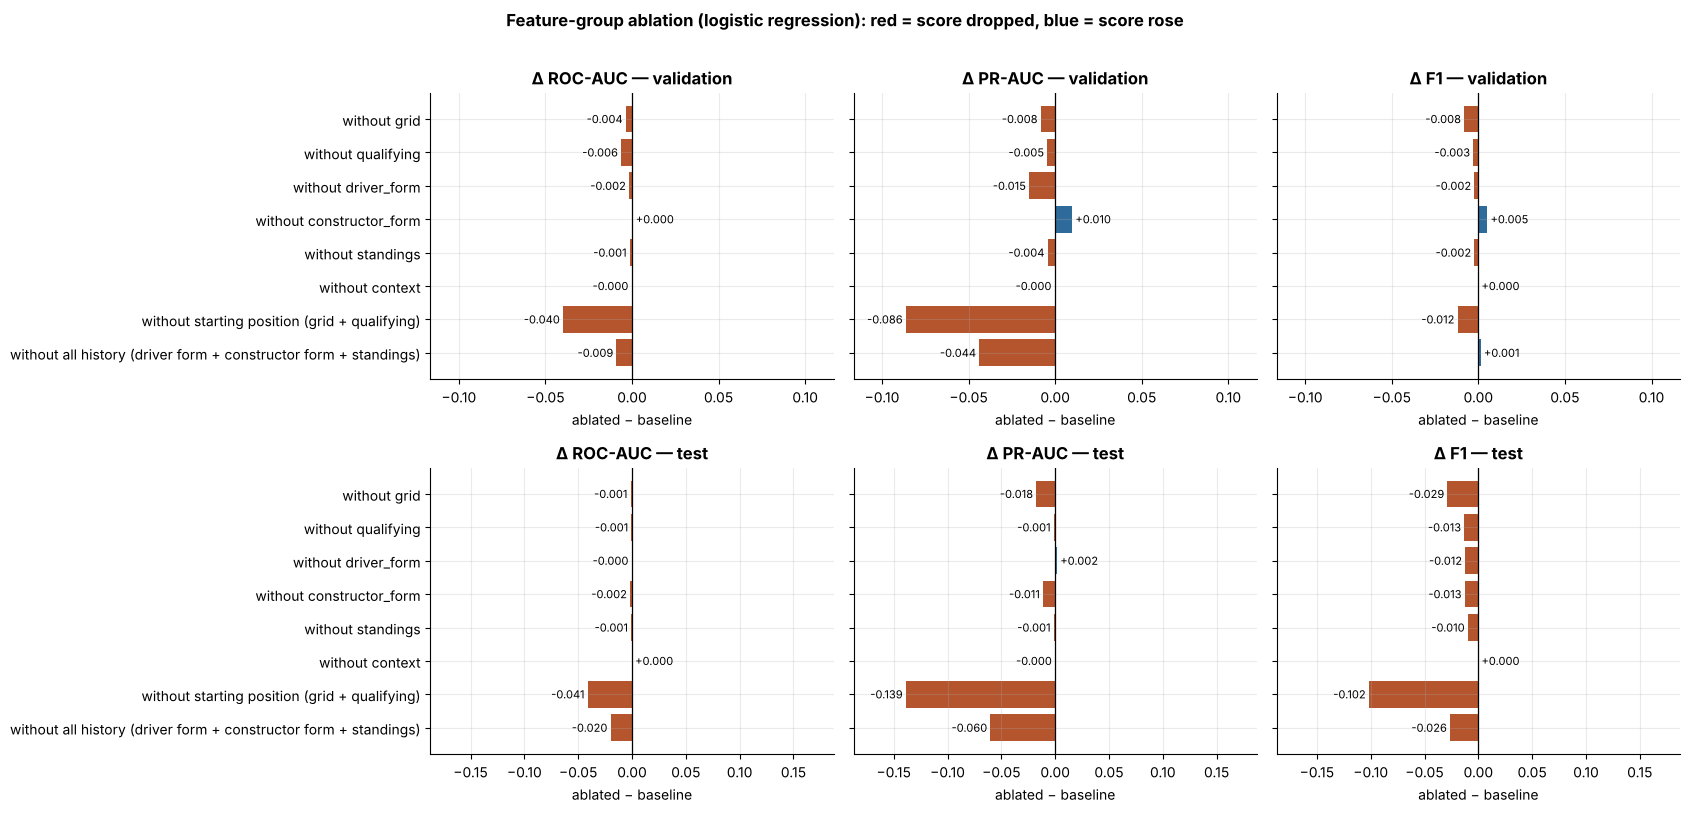

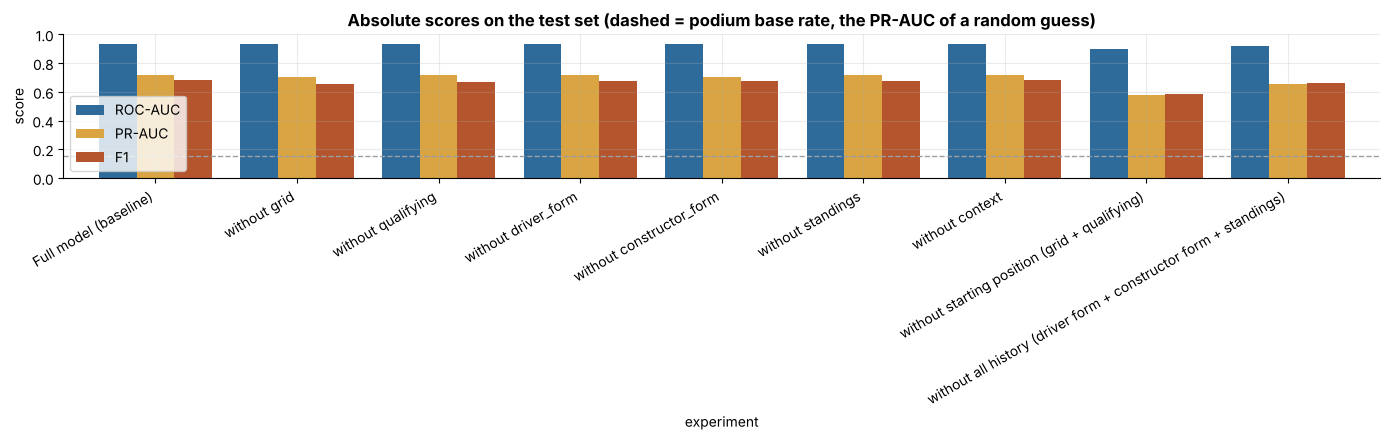

In [ ]:
# Chart 1: change vs the baseline (red = score dropped, blue = score rose)
labels = [name.replace("− ", "without ") for name in ABLATED]

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey=True)
for row, split in enumerate(["validation", "test"]):
    biggest = ABL_TABLES[split].loc[ABLATED, DELTAS].abs().max().max()
    limit = max(0.02, biggest * 1.35)                        # same x-range for all three metrics in a row
    for col, metric in enumerate(["ROC-AUC", "PR-AUC", "F1"]):
        ax = axes[row, col]
        deltas = ABL_TABLES[split].loc[ABLATED, f"Δ {metric}"].values
        ax.barh(labels, deltas, color=[BEFORE if d < 0 else AFTER for d in deltas])
        ax.axvline(0, color="black", lw=0.9)
        for i, d in enumerate(deltas):
            ax.text(d, i, f" {d:+.3f} ", va="center", ha="left" if d >= 0 else "right", fontsize=8)
        ax.set_xlim(-limit, limit)
        ax.set_title(f"Δ {metric} — {split}")
        ax.set_xlabel("ablated − baseline")
axes[0, 0].invert_yaxis()                                     # same top-to-bottom order as the tables
fig.suptitle("Feature-group ablation (logistic regression): red = score dropped, blue = score rose", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

# Chart 2: absolute test scores, so the changes can be judged against the scores themselves
scores_test = ABL_TABLES["test"][["ROC-AUC", "PR-AUC", "F1"]].rename(index=lambda n: n.replace("− ", "without "))
ax = scores_test.plot(kind="bar", color=[AFTER, ACCENT, BEFORE], rot=30, width=0.8, figsize=(14, 4.5))
ax.axhline(test_df[TARGET].mean(), ls="--", color=GREY, lw=1)
ax.set_ylim(0, 1); ax.set_ylabel("score"); ax.set_title("Absolute scores on the test set (dashed = podium base rate, the PR-AUC of a random guess)")
ax.set_xticklabels(ax.get_xticklabels(), ha="right"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

## 5.6 Are the differences bigger than chance?

The test set has 68 races and 204 podiums, so a change of 0.005 could easily be luck. We use a **paired bootstrap over races**:
* resample **whole races** with replacement, 1,000 times (rows inside one race are not independent);
* score **every** experiment on the same resample;
* look at the spread of the **difference** from the baseline.

Nothing is refitted and no threshold is re-tuned. **"Clear"** means the 95% interval excludes 0.

In [ ]:
def bootstrap_deltas(split, n_resamples=1000):
    frame = SPLIT_FRAMES[split].reset_index(drop=True)
    y = frame[TARGET].values
    rows_of_race = list(frame.groupby("raceId").indices.values())
    rng = np.random.default_rng(SEED)

    draws = {name: {m: [] for m in ["ROC-AUC", "PR-AUC", "F1"]} for name in ABL}
    for _ in range(n_resamples):
        picked = rng.choice(len(rows_of_race), len(rows_of_race), replace=True)
        idx = np.concatenate([rows_of_race[i] for i in picked])
        for name, exp in ABL.items():
            p = exp["p"][split][idx]
            draws[name]["ROC-AUC"].append(roc_auc_score(y[idx], p))
            draws[name]["PR-AUC"].append(average_precision_score(y[idx], p))
            draws[name]["F1"].append(f1_score(y[idx], (p >= exp["thr"]).astype(int)))

    rows = []
    for name in ABLATED:
        row = {"experiment": name}
        for m in ["ROC-AUC", "PR-AUC", "F1"]:
            diff = np.array(draws[name][m]) - np.array(draws[BASE][m])
            low, high = np.percentile(diff, [2.5, 97.5])
            observed = ABL[name]["scores"][split][m] - ABL[BASE]["scores"][split][m]
            row[f"Δ {m} [95% CI]"] = f"{observed:+.3f}  [{low:+.3f}, {high:+.3f}]"
            row[f"{m} clear?"] = "yes" if (low > 0 or high < 0) else "no"
        rows.append(row)
    return pd.DataFrame(rows).set_index("experiment")

BOOT = {split: bootstrap_deltas(split) for split in ["validation", "test"]}
print("TEST: change vs baseline, 95% interval over resampled races ('clear?' = interval excludes 0)")
display(BOOT["test"])
print("VALIDATION")
display(BOOT["validation"])

TEST: change vs baseline, 95% interval over resampled races ('clear?' = interval excludes 0)


,Δ ROC-AUC [95% CI],ROC-AUC clear?,Δ PR-AUC [95% CI],PR-AUC clear?,Δ F1 [95% CI],F1 clear?
experiment,,,,,,
− grid,"-0.001 [-0.006, +0.004]",no,"-0.018 [-0.035, -0.002]",yes,"-0.029 [-0.063, +0.013]",no
− qualifying,"-0.001 [-0.005, +0.003]",no,"-0.001 [-0.014, +0.008]",no,"-0.013 [-0.040, +0.014]",no
− driver_form,"-0.000 [-0.003, +0.003]",no,"+0.002 [-0.014, +0.017]",no,"-0.012 [-0.047, +0.024]",no
− constructor_form,"-0.002 [-0.004, -0.000]",yes,"-0.011 [-0.023, -0.002]",yes,"-0.013 [-0.053, +0.030]",no
− standings,"-0.001 [-0.003, +0.001]",no,"-0.001 [-0.013, +0.009]",no,"-0.010 [-0.046, +0.030]",no
− context,"+0.000 [-0.000, +0.000]",no,"-0.000 [-0.002, +0.001]",no,"+0.000 [-0.005, +0.005]",no
− starting position (grid + qualifying),"-0.041 [-0.054, -0.028]",yes,"-0.139 [-0.190, -0.093]",yes,"-0.102 [-0.138, -0.064]",yes
− all history (driver form + constructor form + standings),"-0.020 [-0.030, -0.010]",yes,"-0.060 [-0.103, -0.015]",yes,"-0.026 [-0.065, +0.012]",no


VALIDATION


,Δ ROC-AUC [95% CI],ROC-AUC clear?,Δ PR-AUC [95% CI],PR-AUC clear?,Δ F1 [95% CI],F1 clear?
experiment,,,,,,
− grid,"-0.004 [-0.009, +0.002]",no,"-0.008 [-0.024, +0.007]",no,"-0.008 [-0.044, +0.039]",no
− qualifying,"-0.006 [-0.016, +0.001]",no,"-0.005 [-0.016, +0.006]",no,"-0.003 [-0.022, +0.017]",no
− driver_form,"-0.002 [-0.005, +0.001]",no,"-0.015 [-0.033, -0.000]",yes,"-0.002 [-0.034, +0.036]",no
− constructor_form,"+0.000 [-0.001, +0.002]",no,"+0.010 [-0.005, +0.025]",no,"+0.005 [-0.039, +0.054]",no
− standings,"-0.001 [-0.004, +0.001]",no,"-0.004 [-0.013, +0.006]",no,"-0.002 [-0.032, +0.035]",no
− context,"-0.000 [-0.001, +0.000]",no,"-0.000 [-0.003, +0.002]",no,"+0.000 [+0.000, +0.000]",no
− starting position (grid + qualifying),"-0.040 [-0.061, -0.022]",yes,"-0.086 [-0.141, -0.042]",yes,"-0.012 [-0.042, +0.019]",no
− all history (driver form + constructor form + standings),"-0.009 [-0.022, +0.002]",no,"-0.044 [-0.109, +0.015]",no,"+0.001 [-0.050, +0.052]",no


In [ ]:
# Groups ranked by how much test PR-AUC (primary metric) is lost without them
ablation_rank = ABL_TABLES["test"].loc[ABLATED, ["features", "Δ PR-AUC", "Δ ROC-AUC", "Δ F1"]]
ablation_rank["Δ PR-AUC (validation)"] = ABL_TABLES["validation"].loc[ABLATED, "Δ PR-AUC"]
ablation_rank["test PR-AUC clear?"] = BOOT["test"]["PR-AUC clear?"]
ablation_rank.sort_values("Δ PR-AUC").round(3)

,features,Δ PR-AUC,Δ ROC-AUC,Δ F1,Δ PR-AUC (validation),test PR-AUC clear?
experiment,,,,,,
− starting position (grid + qualifying),10,-0.139,-0.041,-0.102,-0.086,yes
− all history (driver form + constructor form + standings),7,-0.060,-0.020,-0.026,-0.044,yes
− grid,14,-0.018,-0.001,-0.029,-0.008,yes
− constructor_form,13,-0.011,-0.002,-0.013,0.010,yes
− standings,14,-0.001,-0.001,-0.010,-0.004,no
− qualifying,12,-0.001,-0.001,-0.013,-0.005,no
− context,15,-0.000,0.000,0.000,-0.000,no
− driver_form,12,0.002,-0.000,-0.012,-0.015,no


## 5.7 Interpretation

### What the measurements show

**1. Starting position is the most important information, but grid and qualifying cover for each other.**
* Removing **grid and qualifying together** lowers PR-AUC from **0.718 to 0.579 (−0.139)**, ROC-AUC by 0.041 and F1 by 0.102. Clear on test **and** validation (−0.086).
* Removing **only the grid** costs −0.018 (clear on test, not on validation).
* Removing **only qualifying** costs −0.001 (not clear).
* Each half alone looks minor because the other half carries the same information.

**2. Past form matters as a block, not group by group.**
* Removing **all history** (driver form + constructor form + standings) costs **−0.060** PR-AUC and −0.020 ROC-AUC on test (both clear). On validation the drop is −0.044, with an interval that includes 0.
* Removed **one at a time**, the history groups barely matter, and their signs flip between periods:
  * constructor form: −0.011 on test (clear), but +0.010 on validation;
  * driver form: −0.015 on validation (clear), but +0.002 on test;
  * standings: about 0 in both.
* So they cannot be ranked individually: when one is missing, the others take over.

**3. Context (`n_starters`) contributes nothing** to logistic regression (0.000 in every metric on both splits).

**4. A second model family agrees** (5.8).

### Possible explanations (hypotheses, not tested here)
* **Grid vs qualifying.** In the validation and test seasons almost every driver has a qualifying position, and it equals the grid slot unless there is a penalty (ρ = 0.98, 3.6d). With one of them present, the other adds little.
* **The three history groups** all measure "how strong have this driver and car been recently" from different angles (last 5 results, reliability, season points). Overlap is expected.
* **Context.** `grid_rel` already divides the grid slot by `n_starters`, and in modern seasons the field is almost always 20 cars.

### Which groups look useful, redundant or harmful?
| Group | Reading |
|---|---|
| grid + qualifying (together) | **Clearly useful**: the largest drop, on both splits |
| all history (together) | **Useful**: clear drop on test, the same direction on validation |
| grid alone | **Useful but partly replaceable** by qualifying (small, clear drop on test) |
| qualifying alone | **Not separable** from the grid in this setup |
| driver form, constructor form, standings (each alone) | **Not separable from each other**: small effects whose sign flips between validation and test |
| context | **Redundant here** for logistic regression. Not harmful |

A score that *rises* after removing a group (e.g. driver form on test, +0.002) only says the model did not need that group *in this setup*. It does not prove the group is useless.

## 5.8 Robustness check: gradient boosting

**Why this is here.** Logistic regression is linear and fills missing qualifying values by imputation (63% of training rows). Gradient boosting is non-linear and reads missing values directly. If both models tell the same story, the conclusions do not depend on the model family.

**What is held fixed:** the same experiments, rows and threshold rule, with an exact `clone` of the Part 4 gradient-boosting model (not re-tuned). The baseline row is asserted to equal Part 4's predictions.

Baselines (test PR-AUC): logistic regression 0.718 | gradient boosting 0.704


,validation ΔPR-AUC LR,validation ΔPR-AUC GB,validation ΔROC-AUC LR,validation ΔROC-AUC GB,test ΔPR-AUC LR,test ΔPR-AUC GB,test ΔROC-AUC LR,test ΔROC-AUC GB
experiment,,,,,,,,
− grid,-0.008,-0.012,-0.004,-0.007,-0.018,-0.019,-0.001,-0.004
− qualifying,-0.005,-0.012,-0.006,-0.002,-0.001,0.011,-0.001,-0.001
− driver_form,-0.015,-0.001,-0.002,0.000,0.002,-0.020,-0.000,-0.001
− constructor_form,0.010,0.008,0.000,0.000,-0.011,-0.002,-0.002,-0.001
− standings,-0.004,-0.004,-0.001,-0.003,-0.001,-0.006,-0.001,-0.002
− context,-0.000,0.000,-0.000,0.000,-0.000,0.000,0.000,0.000
− starting position (grid + qualifying),-0.086,-0.087,-0.040,-0.040,-0.139,-0.114,-0.041,-0.040
− all history (driver form + constructor form + standings),-0.044,-0.050,-0.009,-0.011,-0.060,-0.046,-0.020,-0.018


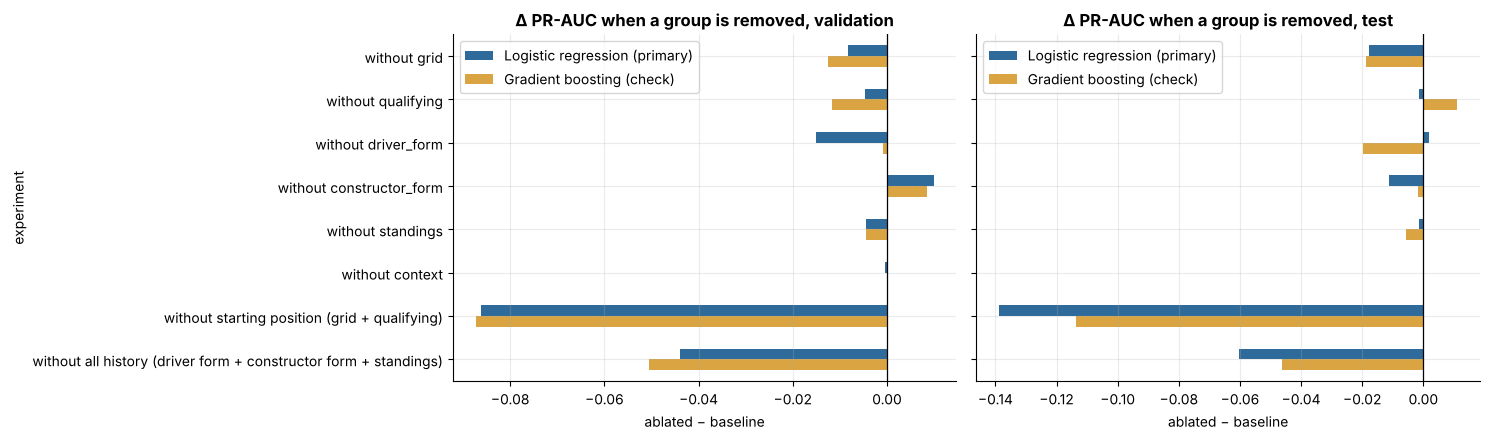

In [ ]:
ABL_GB = {name: run_experiment(cols, base_model=gb_final) for name, cols in EXPERIMENTS.items()}
for split in SPLIT_FRAMES:
    assert np.allclose(ABL_GB[BASE]["p"][split], PRED["Gradient boosting"][split])     # baseline = Part 4 model

def delta(results, name, split, metric):
    return results[name]["scores"][split][metric] - results[BASE]["scores"][split][metric]

rows = []
for name in ABLATED:
    row = {"experiment": name}
    for split in ["validation", "test"]:
        for metric in ["PR-AUC", "ROC-AUC"]:
            row[f"{split} Δ{metric} LR"] = delta(ABL, name, split, metric)
            row[f"{split} Δ{metric} GB"] = delta(ABL_GB, name, split, metric)
    rows.append(row)
cmp_models = pd.DataFrame(rows).set_index("experiment")

print(f"Baselines (test PR-AUC): logistic regression {ABL[BASE]['scores']['test']['PR-AUC']:.3f} | gradient boosting {ABL_GB[BASE]['scores']['test']['PR-AUC']:.3f}")
display(cmp_models.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, split in zip(axes, ["validation", "test"]):
    both = cmp_models[[f"{split} ΔPR-AUC LR", f"{split} ΔPR-AUC GB"]]
    both.columns = ["Logistic regression (primary)", "Gradient boosting (check)"]
    both.rename(index=lambda n: n.replace("− ", "without ")).plot(kind="barh", ax=ax, color=[AFTER, ACCENT])
    ax.axvline(0, color="black", lw=0.9)
    ax.set_title(f"Δ PR-AUC when a group is removed, {split}"); ax.set_xlabel("ablated − baseline")
axes[0].invert_yaxis()
plt.tight_layout(); plt.show()

**The two models agree on the main pattern:**
* **Starting position:** removing grid + qualifying is the largest loss for both (test PR-AUC −0.139 for logistic regression, −0.114 for gradient boosting; validation −0.086 and −0.087).
* **All history:** the second largest for both (test −0.060 and −0.046).
* **Single groups:** small for both (within ±0.02).

**Where they differ.** Single groups change sign between the models: removing **qualifying** *raises* boosting's test PR-AUC (+0.011) but lowers it on validation (−0.012), and **driver form** costs boosting −0.020 on test but logistic regression nothing. Boosting can split on the *missingness* of qualifying, which follows the era (§1.2.7), and that pattern may transfer less well to the test seasons. This is a hypothesis; the gradient-boosting differences were not bootstrapped. The overall conclusion does not depend on the model being linear.

## 5.9 Limitations

* **Correlated features.** `grid_eff` and `quali_pos` correlate at ρ = 0.98, and the three history groups overlap (3.6d). When one group is removed, correlated features absorb part of its information, so **single-group drops understate how much information a group holds**. That is why the two composite experiments are included.
* **Interactions.** Removing one group at a time cannot show combined effects such as "good grid slot **and** strong team". Logistic regression has no interaction terms; only the gradient-boosting check can see some of them.
* **One split, small evaluation sets.**
  * Validation has 39 races and test 68. The bootstrap measures the sampling noise within these sets, but not how results would change with other cut-off years.
  * The test set covers one rules era (2022–24).
* **Fixed settings.** C and the gradient-boosting settings are not re-tuned per experiment. This keeps the comparison controlled, but an ablated model might do slightly better with its own settings.
* **F1 depends on the threshold,** which is re-chosen on a small validation set for each experiment. F1 changes are therefore noisier than PR-AUC and ROC-AUC changes.
* **Historical data.**
  * Qualifying is missing for 63% of training rows (§1.2.7), so the qualifying group can only help where data exists, mostly from 2003.
  * Team history follows renamed teams only for the renames listed in Q3 (2010 onwards).
  * Eras differ strongly (4.9), so a group's contribution is an average over 70 years.
* **Drop-one only.** We removed groups from the full model. Part 3's Trial 2 (adding groups one at a time) is the complementary view, and it can rank overlapping groups differently.
* **Predictive contribution, not causation.** Ablation shows how much the *model's predictions* rely on a group. It does **not** show that a starting slot or past form *causes* a podium; both may reflect car speed.

## 5.10 Summary

**Method.** We retrained the Part 4 logistic regression (16 features, C chosen on validation) with **one feature group removed at a time**. Everything else stayed identical: rows, chronological split (train 1950–2019, validation 2020–21, test 2022–24), the preprocessing pipeline (refitted on training rows for each experiment), the model settings and the validation-based F1 threshold. We removed each of the six Part 3 groups, plus two composites for groups that carry the same information. Changes were tested with a paired race-level bootstrap, and gradient boosting served as a robustness check. The code asserts that the baseline reproduces Part 4 exactly and that no post-race column is used.

**Result.**
* **Starting position is the dominant signal.** Removing grid and qualifying together lowers test PR-AUC from 0.718 to 0.579 (−0.139; ROC-AUC −0.041, F1 −0.102).
* **Past form adds a clear second layer.** Removing driver form, constructor form and standings together costs −0.060 PR-AUC.
* **Single groups matter little, because they cover for each other** (grid alone −0.018; each history group within ±0.02, with signs that differ between validation and test). Field size adds nothing.
* Gradient boosting shows the same pattern.

**Limitations.** Correlated groups make single-group drops understate a group's information. Validation (39 races) and test (68 races) are small, and only one rules era is tested. Qualifying is missing for 63% of training rows. Ablation measures **predictive contribution, not causation**.

Test-set table (generated by code):

In [ ]:
# Compact test-set table for the report
report_tbl = ABL_TABLES["test"][["removed", "features", "ROC-AUC", "Δ ROC-AUC", "PR-AUC", "Δ PR-AUC", "F1", "Δ F1"]].round(3)
report_tbl["PR-AUC change clear?"] = ["—"] + list(BOOT["test"]["PR-AUC clear?"])
report_tbl.index.name = "experiment (test set)"
report_tbl

,removed,features,ROC-AUC,Δ ROC-AUC,PR-AUC,Δ PR-AUC,F1,Δ F1,PR-AUC change clear?
experiment (test set),,,,,,,,,
Full model (baseline),—,16,0.937,0.000,0.718,0.000,0.686,0.000,—
− grid,"grid_eff, grid_rel",14,0.936,-0.001,0.701,-0.018,0.657,-0.029,yes
− qualifying,"quali_pos, quali_gap_pct, grid_minus_quali, qu...",12,0.936,-0.001,0.717,-0.001,0.672,-0.013,no
− driver_form,"driver_form_podium5, driver_form_relpos5, driv...",12,0.937,-0.000,0.720,0.002,0.673,-0.012,no
− constructor_form,"con_form_podium5, con_form_relpos5, con_dnf_ra...",13,0.935,-0.002,0.707,-0.011,0.673,-0.013,yes
− standings,"drv_stand_points_share, con_stand_points_share",14,0.936,-0.001,0.717,-0.001,0.676,-0.010,no
− context,n_starters,15,0.937,0.000,0.718,-0.000,0.686,0.000,no
− starting position (grid + qualifying),"grid_eff, grid_rel, quali_pos, quali_gap_pct, ...",10,0.896,-0.041,0.579,-0.139,0.584,-0.102,yes
− all history (driver form + constructor form + standings),"driver_form_podium5, driver_form_relpos5, driv...",7,0.917,-0.020,0.658,-0.060,0.659,-0.026,yes


---
# Part 6: Model Explainability (XAI)

## 6.0 Purpose, model choice and what we explain

**Why explain the model?** Part 4 shows *how well* the models predict, and Part 5 shows which feature groups they need. Neither shows *how* the model turns a driver's features into a probability. Explanations let us check that predictions rest on sensible **pre-race** information (starting slot, recent form), and see how each feature pushes a prediction up or down.

**Which model? The shallow neural network from 4.5 (`nn_final`; its settings are printed in 4.5 and 4.12).**
* **We choose by purpose, not by score.** The four models are statistically tied on test (paired bootstrap, 4.7), so picking the "best" score would pick noise.
* **It is the least transparent of the four.** Logistic regression can be read from its weights, and Part 5 already measured feature groups with it. The network cannot be read directly.
* **It is not retrained.** We use the fitted `nn_final` and `prep` from Part 4, with the network's validation-chosen threshold.
* These explanations describe *this* model, not "the best model".

**What exactly is explained: the 16 original features.** The network does not see them directly. `prep` (fitted on train in 3.11) turns them into 27 columns: 16 imputed and standardised values plus 11 "was missing" flags. We explain the function

> `predict_podium(16 features) = network(prep(16 features))` → P(podium)

so every plot uses the real feature names in their real units. The effect of a "was missing" flag is credited to the feature it was built from.

| Method | Question it answers | Scope |
|---|---|---|
| Permutation importance | How much does test performance fall if this feature's information is destroyed? | Global |
| SHAP | How much does each feature push *each* prediction above or below the average prediction? | Global and local |
| LIME | Which simple local rule best mimics the model around *one* driver-race? | Local |

>  Everything below describes **how the model uses** the features to predict. A feature being important to the model does **not** show that it **causes** podium finishes. Grid slot, qualifying pace and team form may all simply reflect how fast the car is.

In [ ]:
XAI_MODEL = "Neural network"
xai_threshold = REGISTRY[XAI_MODEL]["thr"]      # its validation-chosen F1 threshold (Part 4)

def predict_podium(X):
    # P(podium) for rows of the 16 original features: Part 3 `prep` (fitted on train) -> Part 4 network
    X = pd.DataFrame(np.asarray(X, dtype=float), columns=FEATURES)
    return nn_final(prep.transform(X), training=False).numpy().ravel()

# Feature types: some columns are pandas nullable types (Int64 / Float64); explainers need plain floats
X_test = test_df[FEATURES].astype(float)
X_val = val_df[FEATURES].astype(float)
y_test, y_val = test_df[TARGET].values, val_df[TARGET].values
p_test = predict_podium(X_test)

# Checks: feature order, valid probabilities, and the same predictions as Part 4
assert list(X_test.columns) == FEATURES
assert ((p_test >= 0) & (p_test <= 1)).all()
assert np.allclose(p_test, PRED[XAI_MODEL]["test"], atol=1e-5), "not the Part 4 model's predictions"
assert roc_auc_score(y_test, p_test) > 0.5, "output is not P(podium)"

print(f"model: {XAI_MODEL} | threshold {xai_threshold:.3f} | test PR-AUC {average_precision_score(y_test, p_test):.3f} (same as 4.7)")
print("missing values in the test rows (handled inside `prep`):",
      {c: f"{v:.1%}" for c, v in X_test.isna().mean().items() if v > 0})

model: Neural network | threshold 0.420 | test PR-AUC 0.715 (same as 4.7)
missing values in the test rows (handled inside `prep`): {'quali_gap_pct': '1.0%', 'driver_form_podium5': '0.6%', 'driver_form_relpos5': '0.6%', 'driver_career_podium': '0.6%'}


## 6.1 Global explanation A: permutation importance

**Idea.** If the model relies on a feature, scrambling that feature should hurt its predictions. For each feature:
1. Score the model on the untouched rows (the baseline).
2. **Shuffle that one column** across the rows, which breaks its link to the target, and keep every other column as it is.
3. Score again. **Importance = baseline score − shuffled score.**
4. Repeat **30 times** with a fixed seed and report the mean and spread, since one shuffle can be lucky.

**Metric: PR-AUC**, the project's primary metric (4.0). Podiums are only ~15% of rows, and PR-AUC measures how well the real podium finishers are ranked at the top. ROC-AUC also gives credit for the many easy non-podium rows (a driver starting 18th), so its drops look smaller.

**Rows: the test set (2022–24, 1,352 rows).** These rows were never used to fit the model or `prep`, and the same rows are used for the baseline and every shuffle. We only explain here and choose nothing, so this is not test-set selection. Validation is run as a stability check.

Shuffling happens on the **16 original features**, before `prep`, so the names shown are exactly the columns that were shuffled.

In [ ]:
def permutation_importance_pr(X, y, columns_to_shuffle, n_repeats=30):
    # Importance = baseline PR-AUC − PR-AUC after shuffling the given column(s); other columns unchanged
    rng = np.random.default_rng(SEED)
    baseline = average_precision_score(y, predict_podium(X))
    drops = []
    for _ in range(n_repeats):
        shuffled = X.copy()
        order = rng.permutation(len(X))
        shuffled[columns_to_shuffle] = X[columns_to_shuffle].values[order]      # the same shuffle for all given columns
        drops.append(baseline - average_precision_score(y, predict_podium(shuffled)))
    return baseline, np.array(drops)

perm_rows = []
for feature in FEATURES:
    _, d_test = permutation_importance_pr(X_test, y_test, [feature])
    _, d_val = permutation_importance_pr(X_val, y_val, [feature])
    perm_rows.append({"feature": feature, "group": GROUP_OF[feature], "importance (test)": d_test.mean(),
                      "std over 30 shuffles": d_test.std(), "importance (validation)": d_val.mean()})
perm = pd.DataFrame(perm_rows).set_index("feature").sort_values("importance (test)", ascending=False)
perm.insert(0, "rank", range(1, len(perm) + 1))

print(f"baseline PR-AUC: test {average_precision_score(y_test, p_test):.3f} | validation {average_precision_score(y_val, predict_podium(X_val)):.3f}")
perm.round(4)

baseline PR-AUC: test 0.715 | validation 0.744


,rank,group,importance (test),std over 30 shuffles,importance (validation)
feature,,,,,
grid_rel,1,grid,0.0880,0.0210,0.0711
quali_pos,2,qualifying,0.0742,0.0197,0.0685
grid_eff,3,grid,0.0548,0.0171,0.0487
con_stand_points_share,4,standings,0.0200,0.0099,0.0128
con_form_relpos5,5,constructor_form,0.0162,0.0066,0.0076
driver_form_podium5,6,driver_form,0.0145,0.0104,0.0264
quali_gap_pct,7,qualifying,0.0135,0.0088,0.0197
driver_career_podium,8,driver_form,0.0126,0.0074,0.0257
drv_stand_points_share,9,standings,0.0075,0.0031,0.0043


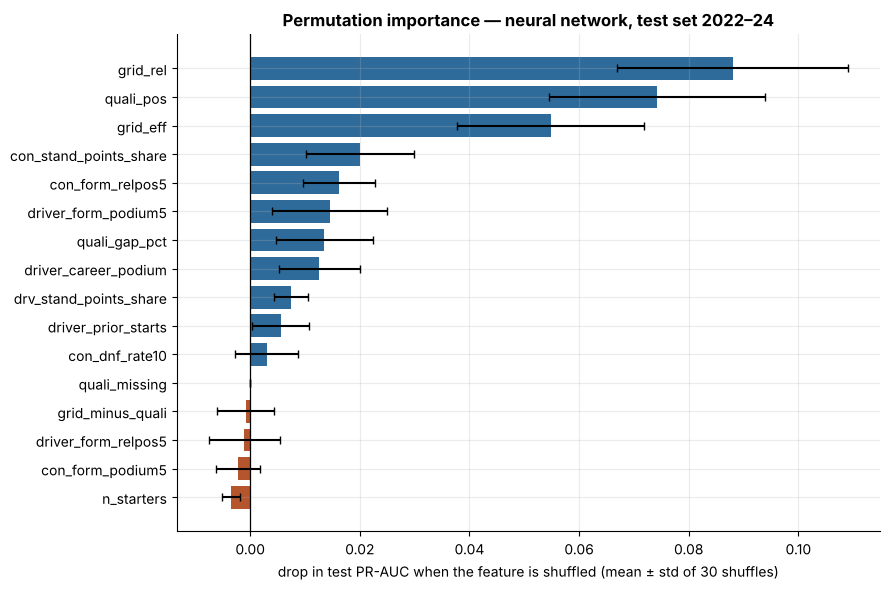

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
shown = perm.iloc[::-1]
ax.barh(shown.index, shown["importance (test)"], xerr=shown["std over 30 shuffles"], capsize=3,
        color=[AFTER if v >= 0 else BEFORE for v in shown["importance (test)"]])
ax.axvline(0, color="black", lw=0.9)
ax.set_xlabel("drop in test PR-AUC when the feature is shuffled (mean ± std of 30 shuffles)")
ax.set_title("Permutation importance — neural network, test set 2022–24")
plt.tight_layout(); plt.show()

**How to read it**
* **Large drop:** the model relies on that feature; scrambling it removes information the model cannot get elsewhere.
* **Near zero:** the model barely uses it, **or** another feature carries the same information and covers for it.
* **Negative (red):** the score *improved* when the feature was scrambled: the model's use of it does not hold up on these seasons.

**What we found**
* **Starting position dominates.** `grid_rel` (0.088), `quali_pos` (0.074) and `grid_eff` (0.055) are far ahead of everything else. Validation gives the same top three.
* **Form and standings come next, but small:** team points share (0.020), team finishing form (0.016), driver podium form (0.015), gap to pole (0.014) and career podium rate (0.013).
* **`quali_missing` is exactly 0** because it is 0 for every test row (qualifying always exists in 2022–24); shuffling a constant changes nothing.
* **Around zero:** `grid_minus_quali`, `driver_form_relpos5` and `con_form_podium5` (error bars cross 0). **`n_starters` is slightly but consistently negative** (−0.003 ± 0.002): whatever the network learned from field size does not transfer to 2022–24, where the field is always about 20 cars.

**Main limitation: correlated features.** `grid_eff`, `grid_rel` and `quali_pos` describe the same starting slot (ρ ≈ 0.96–0.98). Shuffling one leaves the others intact, so **each looks less important than the information it holds**. That is why the next table shuffles whole groups.

### The same test, one feature **group** at a time

Single features hide behind their correlated partners: with `quali_pos` intact, shuffling `grid_eff` loses little. So we also shuffle **all columns of a group together** (same row order for every column in the group), using the Part 3 groups and the two Part 5 composites. The last column repeats the Part 5 ablation result for comparison.

In [ ]:
GROUP_SETS = {**ABLATION_GROUPS, **COMPOSITES}
group_rows = []
for name, cols in GROUP_SETS.items():
    _, d = permutation_importance_pr(X_test, y_test, cols)
    group_rows.append({"group": name, "features": len(cols), "importance (test)": d.mean(), "std": d.std(),
                       "Part 5 ablation Δ PR-AUC (logistic regression, retrained)": ABL_TABLES["test"].loc[f"− {name}", "Δ PR-AUC"]})
perm_groups = pd.DataFrame(group_rows).set_index("group").sort_values("importance (test)", ascending=False)
perm_groups.round(4)

,features,importance (test),std,"Part 5 ablation Δ PR-AUC (logistic regression, retrained)"
group,,,,
starting position (grid + qualifying),6,0.3366,0.0264,-0.1388
all history (driver form + constructor form + standings),9,0.2255,0.0272,-0.0602
grid,2,0.1903,0.0250,-0.0176
qualifying,4,0.0845,0.0202,-0.0013
driver_form,4,0.0334,0.0135,0.0019
standings,2,0.0234,0.0103,-0.0013
constructor_form,3,0.0065,0.0055,-0.0113
context,1,-0.0034,0.0016,-0.0002


**What we found**
* **Shuffling a whole block shows its real weight.** The starting-position block (grid + qualifying) costs **0.337** PR-AUC, almost four times its strongest single feature. The history block (driver form + constructor form + standings) costs **0.226**.
* **The two blocks come in the same order as in the Part 5 ablation** (−0.139 and −0.060). The numbers are larger because the methods do different things:
  * **permutation** destroys the information *without retraining*, so the network cannot adapt;
  * **ablation** retrains without the group, and the remaining features partly take over.
* **Within the blocks the order differs.** Qualifying costs 0.084 here but only −0.001 in the ablation: retrained without qualifying, logistic regression gets the same information from the grid, while the trained network does use qualifying and is hurt when it is scrambled.
* Both methods agree on the big picture: **starting position first, recent form second, field size nothing.**

## 6.2 Global explanation B: SHAP

**What a SHAP value means here.** Start from the **average predicted podium probability** over a background sample of drivers (the *base value*). For one driver-race, each of the 16 features gets a SHAP value: how much it moves *this* prediction above or below that average. The values add up exactly:

> base value + sum of the 16 SHAP values = the model's predicted P(podium) for that row.

`predict_podium` returns a **probability**, so the SHAP values are in **probability points** (+0.10 = 10 percentage points more likely to podium). They are not log-odds.

**Choosing the explainer (checked against our model)**
* **TreeExplainer:** only for tree models. Not applicable.
* **LinearExplainer:** only for linear models. Not applicable.
* **DeepExplainer / GradientExplainer:** work on Keras networks, but they would explain the **27 prepared columns** (standardised values and "was missing" flags) in the network's raw output. They also have known TensorFlow-version problems.
* **Exact explainer:** with 16 features, it needs 2¹⁶ = 65,536 feature combinations per row, which is too slow for a Keras model.
* **Our choice: `shap.explainers.Permutation`** (model-agnostic).
  * It treats `predict_podium` as a black box, so it explains the 16 real features in probability units.
  * It walks through random **orderings** of the features and records how the prediction changes as each feature is revealed. We use **10 orderings per row** (`max_evals = 330`, each ordering run forwards and backwards), with a fixed seed.
  * The values add up exactly to each prediction by construction. The split between features is an estimate, so we measure its stability below.

**Samples**
* **Background ("average driver"):** 100 random **training** rows from **2014–2019** with no missing values (fixed seed).
  * Modern seasons, because the explained rows are 2022–24. Mixing in 1950s rows would make "average driver" a car from another era.
  * Complete rows, so hidden features are never filled in with "missing".
* **Explained rows:** all **1,352 test rows**. These are not the rows the network was trained on.

**Class check.** The model outputs a single number, P(podium), so there is no "which class column" ambiguity. We still **assert** that base value + SHAP values reproduces P(podium) for every row. If SHAP were explaining "no podium", the sum would equal 1 − P(podium) instead.

In [ ]:
background = (train_df[train_df.year.between(2014, 2019)][FEATURES].astype(float)
              .dropna().sample(100, random_state=SEED))
masker = shap.maskers.Independent(background, max_samples=100)
explainer = shap.explainers.Permutation(predict_podium, masker, seed=SEED)
sv = explainer(X_test, max_evals=330, silent=True)                 # one SHAP value per test row and feature

# Checks: shape, feature order, base value, and additivity to P(podium)
assert sv.values.shape == (len(X_test), len(FEATURES))
assert list(sv.feature_names) == FEATURES
assert np.allclose(sv.base_values, predict_podium(background).mean(), atol=1e-5)
assert np.allclose(sv.base_values + sv.values.sum(axis=1), p_test, atol=1e-4), "SHAP values do not add up to P(podium)"
print(f"base value (average P(podium) over the 2014–19 background): {sv.base_values[0]:.3f}")
print(f"largest additivity error: {np.abs(sv.base_values + sv.values.sum(axis=1) - p_test).max():.1e}")

# Stability: explain 50 rows again with a different seed and compare
check_rows = X_test.sample(50, random_state=SEED).index
sv_again = shap.explainers.Permutation(predict_podium, masker, seed=SEED + 1)(X_test.loc[check_rows], max_evals=330, silent=True)
idx = [X_test.index.get_loc(i) for i in check_rows]
change = np.abs(sv_again.values - sv.values[idx]).mean()
print(f"stability: mean |change| with another seed = {change:.4f} probability points "
      f"({change / np.abs(sv.values[idx]).mean():.0%} of the mean |SHAP value|)")

base value (average P(podium) over the 2014–19 background): 0.164
largest additivity error: 6.7e-10


stability: mean |change| with another seed = 0.0014 probability points (10% of the mean |SHAP value|)


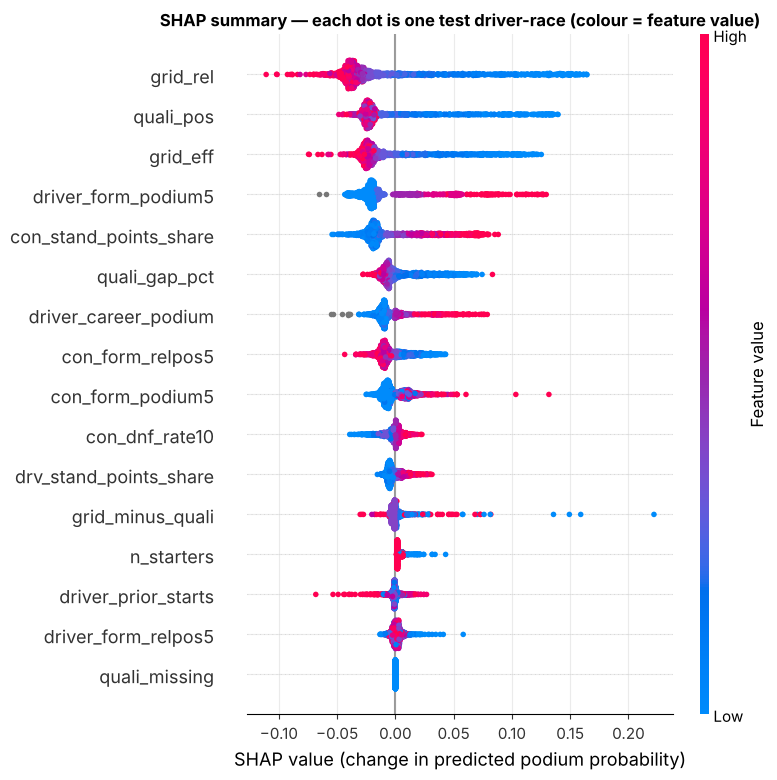

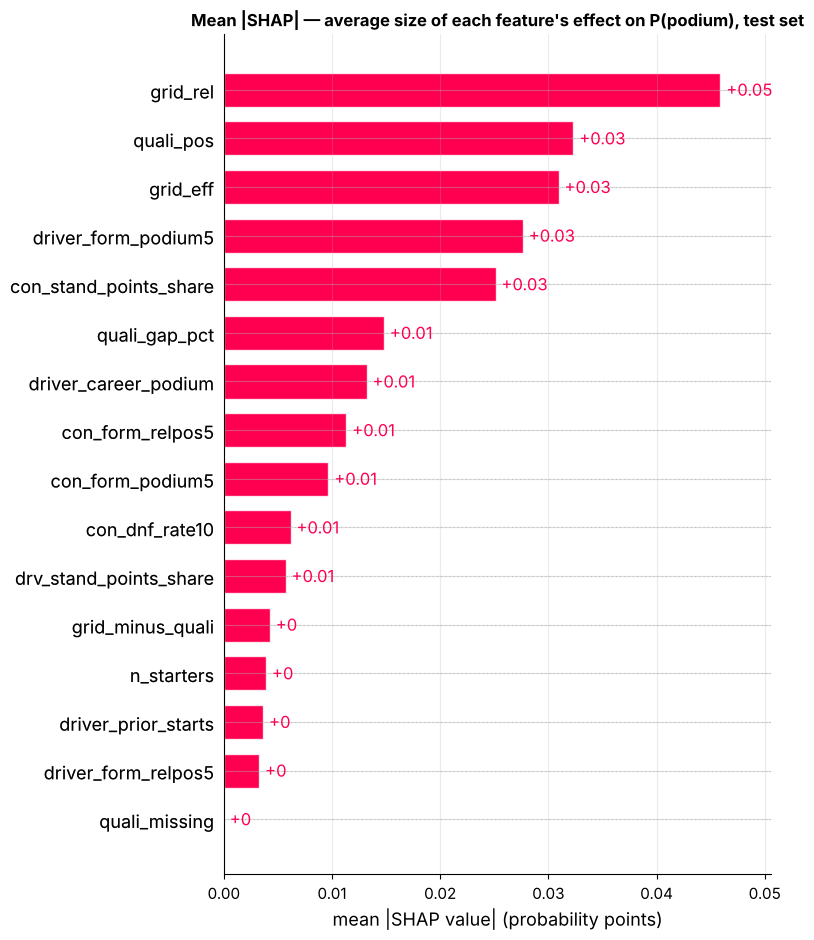

,mean |SHAP|,"direction: Spearman(value, SHAP)"
grid_rel,0.0459,-0.94
quali_pos,0.0323,-0.72
grid_eff,0.0309,-0.91
driver_form_podium5,0.0276,0.83
con_stand_points_share,0.0251,0.80
quali_gap_pct,0.0148,-0.95
driver_career_podium,0.0132,0.74
con_form_relpos5,0.0113,-0.87
con_form_podium5,0.0097,0.81
con_dnf_rate10,0.0062,0.90


In [ ]:
shap.plots.beeswarm(sv, max_display=len(FEATURES), show=False)
plt.title("SHAP summary — each dot is one test driver-race (colour = feature value)")
plt.xlabel("SHAP value (change in predicted podium probability)")
plt.tight_layout(); plt.show()

shap.plots.bar(sv, max_display=len(FEATURES), show=False)
plt.title("Mean |SHAP| — average size of each feature's effect on P(podium), test set")
plt.xlabel("mean |SHAP value| (probability points)")
plt.tight_layout(); plt.show()

# The same information as numbers: size of the effect, and its direction
# (Spearman between a feature's value and its SHAP value: + = higher value pushes towards a podium)
shap_size = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES)
shap_direction = pd.Series({f: X_test[f].corr(pd.Series(sv[:, f].values, index=X_test.index), method="spearman") for f in FEATURES})
pd.DataFrame({"mean |SHAP|": shap_size.round(4), "direction: Spearman(value, SHAP)": shap_direction.round(2)}).sort_values("mean |SHAP|", ascending=False)

**How to read the plots**
* **Summary (beeswarm):** one row per feature, one dot per test driver-race. The x-position is the SHAP value: right = pushes towards a podium, left = away from it. The colour is the feature's value (red = high, blue = low). Grey dots are missing values.
* **Bar plot:** the average size of each feature's push, ignoring direction. This is SHAP's global ranking.
* **Table:** the same as numbers. "Direction" is the rank correlation between a feature's value and its SHAP value: **negative** = lower values push towards a podium (e.g. a lower grid slot), **positive** = higher values do.

**What we found**
* **Starting position has the biggest effects:** `grid_rel` (mean |SHAP| 0.046), `quali_pos` (0.032), `grid_eff` (0.031) and the gap to pole (0.015). All have strongly negative directions (−0.72 to −0.95): starting and qualifying near the front pushes towards a podium.
* **Recent form and standings come next, in the expected direction:** a high recent podium rate (`driver_form_podium5`, 0.028, +0.83), team points share (0.025, +0.80), career podium rate (+0.74) and team podium form (+0.81) push up; a poor recent team finish (`con_form_relpos5`, −0.87) pushes down.
* **Grid penalty:** `grid_minus_quali` (−0.50): starting behind where one qualified pushes down, the penalty effect from Q1.
* **One effect has the wrong sign:** for `con_dnf_rate10` the direction is **+0.90**, so a *higher* team DNF rate pushes the prediction *up*. This is checked after the local explanations (6.3).
* `n_starters`, `driver_prior_starts`, `driver_form_relpos5` and `quali_missing` barely move predictions (mean |SHAP| ≤ 0.004).

In [ ]:
# SHAP per feature GROUP: share of the total |SHAP|, next to the group permutation result and the Part 5 ablation
shap_by_group = pd.Series({name: np.abs(sv[:, cols].values).sum(axis=1).mean() for name, cols in ABLATION_GROUPS.items()})
group_cmp = pd.DataFrame({
    "mean |SHAP| (sum over group)": shap_by_group.round(3),
    "share of total |SHAP| %": (100 * shap_by_group / shap_by_group.sum()).round(0),
    "permutation importance (group shuffled)": perm_groups.loc[list(ABLATION_GROUPS), "importance (test)"].round(3),
    "Part 5 ablation Δ PR-AUC": perm_groups.loc[list(ABLATION_GROUPS), "Part 5 ablation Δ PR-AUC (logistic regression, retrained)"].round(3),
}).sort_values("mean |SHAP| (sum over group)", ascending=False)
group_cmp

,mean |SHAP| (sum over group),share of total |SHAP| %,permutation importance (group shuffled),Part 5 ablation Δ PR-AUC
grid,0.077,32.0,0.190,-0.018
qualifying,0.051,22.0,0.084,-0.001
driver_form,0.048,20.0,0.033,0.002
standings,0.031,13.0,0.023,-0.001
constructor_form,0.027,11.0,0.006,-0.011
context,0.004,2.0,-0.003,-0.000


**Grouped view.** Adding up the |SHAP| values within each group:
* **grid ≈ 32%**, **qualifying ≈ 22%**;
* **driver form ≈ 20%**, **standings ≈ 13%**, **constructor form ≈ 11%**;
* **context ≈ 2%**.

So the starting-position block accounts for a little over half of the network's total effect, and the recent-form block for most of the rest. The permutation and ablation columns rank the blocks the same way.

These measure different things:
* **SHAP** says how much a group *moves the predictions*.
* **Permutation and ablation** say how much *ranking quality* is lost without it.

A group can move many predictions a little (form) or decide the few rows that matter most (starting position).

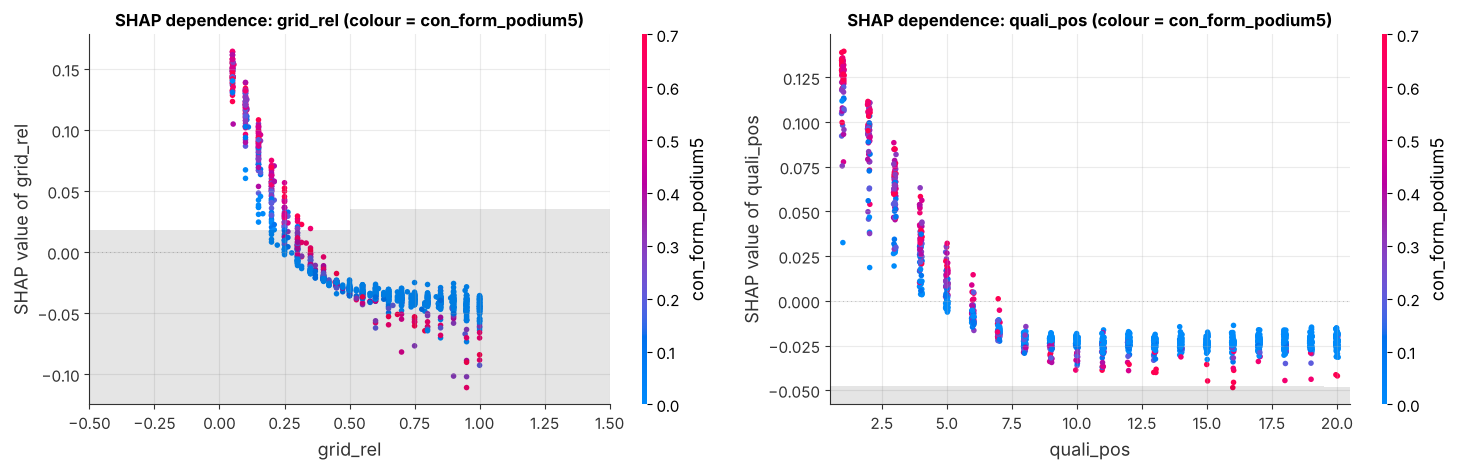

features plotted (largest mean |SHAP|): ['grid_rel', 'quali_pos']


quali_pos,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
mean SHAP of quali_pos,0.121,0.089,0.059,0.028,0.009,-0.008,-0.017,-0.022,-0.024,-0.025,-0.025,-0.024,-0.025,-0.024,-0.024,-0.025,-0.023,-0.024,-0.023,-0.023
test rows,68.000,67.000,68.000,68.000,68.000,68.000,67.000,68.000,68.000,67.000,68.000,67.000,68.000,67.000,68.000,68.000,68.000,68.000,68.000,65.000


In [ ]:
# Dependence plots for the two features with the largest mean |SHAP| (chosen from the results above)
top_two = list(pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).nlargest(2).index)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, feature in zip(axes, top_two):
    colour_by = "con_form_podium5" if feature != "con_form_podium5" else "grid_eff"
    shap.plots.scatter(sv[:, feature], color=sv[:, colour_by], ax=ax, show=False)
    ax.set_title(f"SHAP dependence: {feature} (colour = {colour_by})")
    ax.set_ylabel(f"SHAP value of {feature}")
plt.tight_layout(); plt.show()
print("features plotted (largest mean |SHAP|):", top_two)

# The same curve as numbers: average SHAP value of quali_pos for each qualifying position in the test rows
shap_quali = pd.Series(sv[:, "quali_pos"].values, index=X_test.index)
curve = shap_quali.groupby(X_test.quali_pos).agg(["mean", "size"]).loc[1:20]
curve.columns = ["mean SHAP of quali_pos", "test rows"]
display(curve.round(3).T)

**Why these two:** they have the largest mean |SHAP|. Each dot is a test row: the feature's value (x) against its SHAP value (y), coloured by the team's recent podium rate. The table under the plots gives the `quali_pos` curve as numbers.

**What we found**
* **The effect is steep and curved.** From the table: qualifying P1 adds **+0.12** on average, P2 +0.09, P3 +0.06, P4 +0.03, P5 +0.01. From about **P7 on it is flat at −0.02 to −0.025**: being 9th or 19th makes no real difference.
* `grid_rel` has the same shape in the plot. The network learned the non-linear "front of the grid" curve from Part 3 (3.6a), which logistic regression can only approximate with a straight line.
* **Interaction (visible in the colours):** the slot matters more for strong teams. At the front, rows from teams with a high recent podium rate (red) sit higher; at the back of the grid, they sit lower. For a team without recent podiums (blue) the slot moves the prediction less. The effect is modest next to the slot itself.

## 6.3 Local explanations: two real driver-races

**Global** explanations describe the model over all rows. A **local** explanation answers: *why did the model give **this** driver **this** probability in **this** race?*

**How the examples are chosen (rules written in code, not hand-picked)**
* **Example A: a typical case.** The **winner of the last race in the test set**. It is neutral and reproducible, and shows how the model treats a strong, normal prediction.
* **Example B: the model's biggest miss.** The **test-set podium finisher with the lowest predicted probability**. Picking the worst failure on purpose shows the model's limits instead of hiding them.

Both use the network's validation-chosen threshold for the predicted class.

In [ ]:
scored = test_df.assign(p_podium=p_test, predicted=(p_test >= xai_threshold).astype(int))
names = clean["drivers"][["driverId", "forename", "surname"]]
race_names = clean["races"][["raceId", "name"]].rename(columns={"name": "race_name"})
scored = scored.merge(names, on="driverId", how="left").merge(race_names, on="raceId", how="left").set_index(test_df.index)

last_race = scored.sort_values(["year", "round"]).raceId.iloc[-1]
example_a = scored[(scored.raceId == last_race) & (scored.positionOrder == 1)].index[0]
example_b = scored[scored[TARGET] == 1].p_podium.idxmin()
EXAMPLES = {"A: last test race winner": example_a, "B: biggest missed podium": example_b}

facts = pd.DataFrame({
    label: {"driver": f"{scored.at[i, 'forename']} {scored.at[i, 'surname']}",
            "race": f"{scored.at[i, 'year']} {scored.at[i, 'race_name']}",
            "started (grid)": int(scored.at[i, "grid_eff"]),
            "finished": int(scored.at[i, "positionOrder"]),
            "true label": "podium" if scored.at[i, TARGET] == 1 else "no podium",
            "predicted P(podium)": round(float(scored.at[i, "p_podium"]), 3),
            "predicted class": f"{'podium' if scored.at[i, 'predicted'] else 'no podium'} (threshold {xai_threshold:.3f})",
            "correct?": "yes" if scored.at[i, "predicted"] == scored.at[i, TARGET] else "no"}
    for label, i in EXAMPLES.items()})
display(facts)
display(X_test.loc[list(EXAMPLES.values())].set_axis(list(EXAMPLES), axis=0).round(3))

,A: last test race winner,B: biggest missed podium
driver,Lando Norris,Pierre Gasly
race,2024 Abu Dhabi Grand Prix,2024 São Paulo Grand Prix
started (grid),1,13
finished,1,3
true label,podium,podium
predicted P(podium),0.697,0.002
predicted class,podium (threshold 0.420),no podium (threshold 0.420)
correct?,yes,no


,grid_eff,grid_rel,quali_pos,quali_gap_pct,grid_minus_quali,quali_missing,driver_form_podium5,driver_form_relpos5,driver_career_podium,driver_prior_starts,con_form_podium5,con_form_relpos5,con_dnf_rate10,drv_stand_points_share,con_stand_points_share,n_starters
A: last test race winner,1.0,0.050,1.0,0.000,0.0,0.0,0.2,0.287,0.197,127.0,0.2,0.303,0.00,0.814,1.000,20.0
B: biggest missed podium,13.0,0.722,15.0,7.212,-2.0,0.0,0.0,0.660,0.027,149.0,0.0,0.695,0.05,0.025,0.025,18.0


### Local SHAP (waterfall plots)
Each plot starts at the **base value** E[f(X)] at the bottom: the average predicted podium probability over the 2014–19 background drivers. Each bar adds one feature's SHAP value (**red = pushes towards a podium, blue = pushes away**), ending at f(x), the model's probability for this driver-race. The grey numbers are this row's feature values.

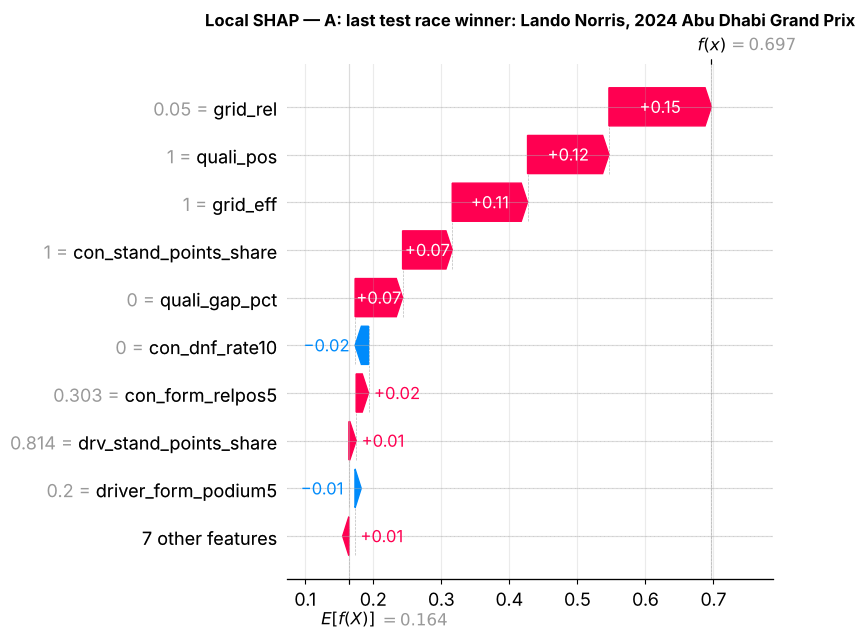

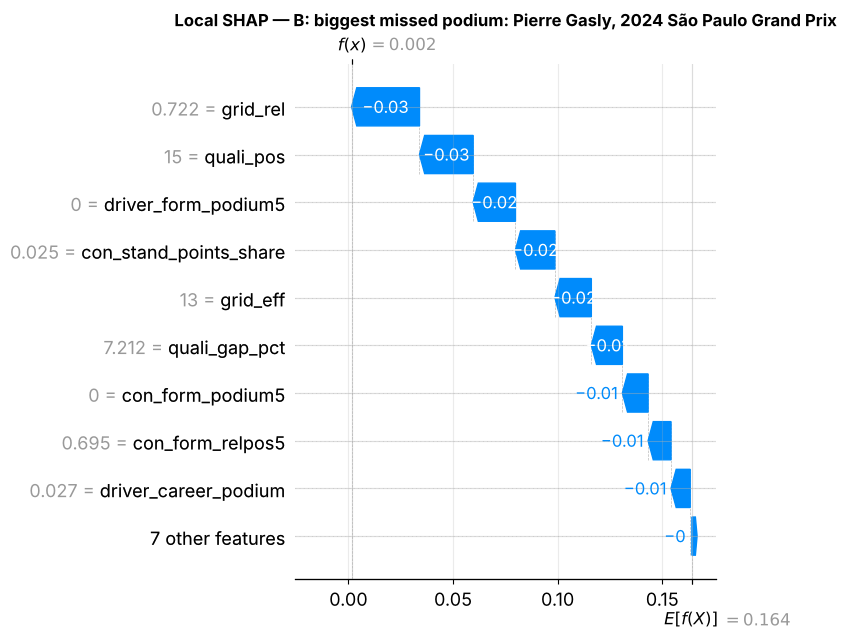

In [ ]:
for label, i in EXAMPLES.items():
    k = X_test.index.get_loc(i)
    assert np.isclose(sv.base_values[k] + sv.values[k].sum(), p_test[k], atol=1e-4)     # explains this row's P(podium)
    shap.plots.waterfall(sv[k], max_display=10, show=False)
    plt.title(f"Local SHAP — {label}: {facts.at['driver', label]}, {facts.at['race', label]}")
    plt.tight_layout(); plt.show()

**What the waterfalls show** (the numbers are in the SHAP-vs-LIME table further down)
* **Example A (pole-sitter who won, predicted 0.697).**
  * The starting-position features add about **+0.45** to the 0.164 base value: `grid_rel` +0.151, `quali_pos` +0.120, `grid_eff` +0.111, gap to pole of 0 +0.070.
  * His team leading the constructors' standings (`con_stand_points_share = 1`) adds +0.073.
  * One push goes the "wrong" way: a team DNF rate of **0** *lowers* the prediction (−0.020). This is suspicious and is checked below.
* **Example B (podium from P13, predicted 0.002).**
  * Every main feature pushes **down**: starting 13th, qualifying 15th and 7% off pole, no recent podiums for the driver, and a team with almost no points.
  * The model is not confused here: nothing known before the start pointed to a podium. The result came from what happened **during** the race (a wet race with many incidents), which no pre-race feature can contain. **This is the correct behaviour for a pre-race model**, and the kind of miss it will always make.

### LIME (same two examples)
**What LIME does.** It creates **5,000 slightly changed copies** of the driver-race, asks our model for P(podium) on each, and fits a **simple weighted linear model** that mimics our model *only near this one row*. Its weights show which feature conditions support (positive) or oppose (negative) a podium **locally**.

**Settings (fixed for reproducibility)**
* `random_state = SEED`, `num_samples = 5000`.
* Continuous features are split into quartile bins (LIME's default), so conditions read like "grid_eff ≤ 5".
* `quali_missing` is declared **categorical** (0/1).
* **Reference data:** the same complete 2014–19 training rows that SHAP's background is drawn from. LIME needs data without gaps to learn the feature distributions, and modern rows match the explained test rows.

The prediction function returns **[P(no podium), P(podium)]**; the cell asserts that column 1 is our model's P(podium).

**LIME is an approximation.** We report its **local fit (R²)** and its own prediction next to the model's. A low R² means the simple surrogate does not mimic the model well around that row, so its weights deserve less trust. LIME can also change with the random sample and the binning.

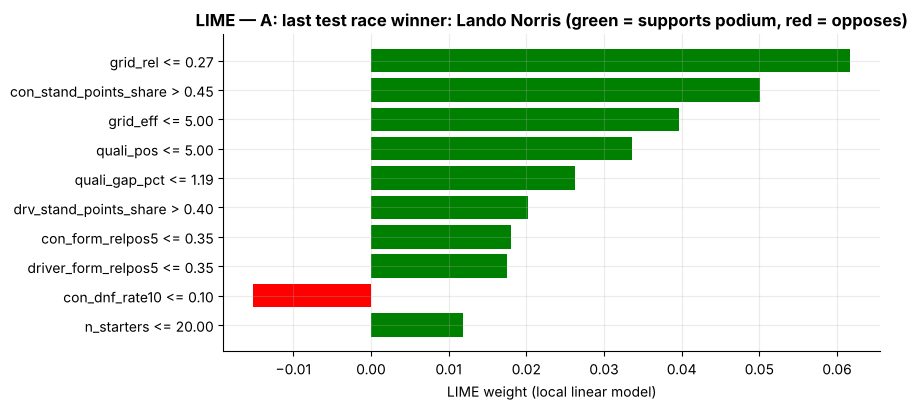

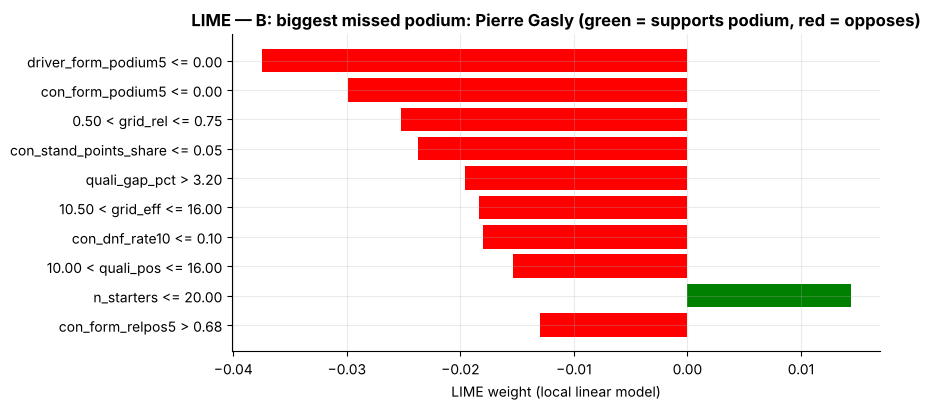

,A: last test race winner,B: biggest missed podium
model P(podium),0.697,0.002
LIME surrogate prediction,0.258,-0.050
LIME local fit (R²),0.380,0.220
row had missing values filled for LIME,0.000,0.000


In [ ]:
def predict_both_classes(X):
    p = predict_podium(X)
    return np.column_stack([1 - p, p])                       # column 1 = podium

check = predict_both_classes(X_test.values[:5])
assert np.allclose(check.sum(axis=1), 1) and np.allclose(check[:, 1], p_test[:5], atol=1e-5)

lime_reference = train_df[train_df.year.between(2014, 2019)][FEATURES].astype(float).dropna()
lime_explainer = LimeTabularExplainer(
    lime_reference.values, feature_names=FEATURES, class_names=["no podium", "podium"], mode="classification",
    categorical_features=[FEATURES.index("quali_missing")], discretize_continuous=True, random_state=SEED)

LIME, fidelity = {}, {}
for label, i in EXAMPLES.items():
    k = X_test.index.get_loc(i)
    row = X_test.loc[i].fillna(lime_reference.median())       # LIME cannot perturb a missing value; fill with the reference median
    exp = lime_explainer.explain_instance(row.values, predict_both_classes, num_features=10, num_samples=5000, labels=(1,))
    LIME[label] = exp
    fidelity[label] = {"model P(podium)": round(float(p_test[k]), 3),
                       "LIME surrogate prediction": round(float(exp.local_pred[0]), 3),
                       "LIME local fit (R²)": round(float(exp.score), 2),
                       "row had missing values filled for LIME": int(X_test.loc[i].isna().sum())}
    fig = exp.as_pyplot_figure(label=1)
    fig.set_size_inches(9, 4.2)
    plt.title(f"LIME — {label}: {facts.at['driver', label]} (green = supports podium, red = opposes)")
    plt.xlabel("LIME weight (local linear model)")
    plt.tight_layout(); plt.show()

pd.DataFrame(fidelity)

**What LIME shows**
* **Example A.** The supporting conditions match SHAP's: front grid slot, front qualifying slot, a team leading the standings, small gap to pole, good team form. A low team DNF rate is again shown as *opposing* a podium, so LIME reproduces the same suspicious effect: it describes the model, not reality.
* **Example B.** Every condition opposes a podium. LIME puts **recent form first** (no podiums lately for driver or team), with grid and qualifying further down.
* **The local fit is weak (R² 0.38 and 0.22),** and LIME's surrogate prediction is far from the model's (0.26 vs 0.70 for example A). The network's probability changes steeply near the front of the grid, and a straight line around one point cannot follow that curve. So LIME is a **rough sketch of direction**, not precise weights.

In [ ]:
# SHAP vs LIME for the same rows: rank of each feature by the size of its local effect (1 = largest)
def lime_weights(exp):
    # LIME labels look like "grid_eff <= 5.00"; map each back to its feature name (longest name first, so
    # "driver_form_podium5" is not mistaken for a shorter name it contains)
    weights = {}
    for condition, w in exp.as_list(label=1):
        feature = next(f for f in sorted(FEATURES, key=len, reverse=True) if f in condition)
        weights[feature] = w
    return pd.Series(weights).reindex(FEATURES).fillna(0.0)

for label, i in EXAMPLES.items():
    k = X_test.index.get_loc(i)
    local = pd.DataFrame({"SHAP value": sv.values[k], "LIME weight": lime_weights(LIME[label])}, index=FEATURES)
    local["SHAP rank"] = local["SHAP value"].abs().rank(ascending=False).astype(int)
    local["LIME rank"] = local["LIME weight"].abs().rank(ascending=False, method="min").astype(int)
    local = local.sort_values("SHAP rank").head(8)
    print(f"{label}: same top feature -> {local.index[0] == local.sort_values('LIME rank').index[0]}")
    display(local.round(3))

A: last test race winner: same top feature -> True


,SHAP value,LIME weight,SHAP rank,LIME rank
grid_rel,0.151,0.062,1,1
quali_pos,0.120,0.034,2,4
grid_eff,0.111,0.040,3,3
con_stand_points_share,0.073,0.050,4,2
quali_gap_pct,0.070,0.026,5,5
con_dnf_rate10,-0.020,-0.015,6,9
con_form_relpos5,0.018,0.018,7,7
drv_stand_points_share,0.011,0.020,8,6


B: biggest missed podium: same top feature -> False


,SHAP value,LIME weight,SHAP rank,LIME rank
grid_rel,-0.032,-0.025,1,3
quali_pos,-0.026,-0.015,2,8
driver_form_podium5,-0.020,-0.038,3,1
con_stand_points_share,-0.019,-0.024,4,4
grid_eff,-0.017,-0.018,5,6
quali_gap_pct,-0.015,-0.020,6,5
con_form_podium5,-0.012,-0.030,7,2
con_form_relpos5,-0.011,-0.013,8,10


**A suspicious effect, checked.**

In [ ]:
# con_dnf_rate10 = share of the team's cars that did NOT finish in its last 10 races (any cause).
# Common sense: higher = less reliable = LOWER podium chance. Does the network agree, over all test rows?
dnf_value, dnf_shap = X_test.con_dnf_rate10, pd.Series(sv[:, "con_dnf_rate10"].values, index=X_test.index)
print(f"Spearman(feature value, its SHAP value) over the test rows: {dnf_value.corr(dnf_shap, method='spearman'):+.2f}  "
      "(negative = the expected direction)")
bins = pd.cut(dnf_value, [-0.01, 0.0, 0.1, 0.2, 1.0], labels=["0 (no DNF)", "≤ 10%", "10–20%", "> 20%"])
pd.DataFrame({"test rows": bins.value_counts().sort_index(),
              "mean SHAP of con_dnf_rate10": dnf_shap.groupby(bins, observed=True).mean().round(3),
              "real podium rate %": (100 * test_df[TARGET].groupby(bins, observed=True).mean()).round(1),
              "mean team podium form (con_form_podium5)": X_test.con_form_podium5.groupby(bins, observed=True).mean().round(2)})

Spearman(feature value, its SHAP value) over the test rows: +0.90  (negative = the expected direction)


,test rows,mean SHAP of con_dnf_rate10,real podium rate %,mean team podium form (con_form_podium5)
con_dnf_rate10,,,,
0 (no DNF),90,-0.021,52.2,0.49
≤ 10%,542,-0.006,15.5,0.16
10–20%,494,-0.000,10.7,0.11
> 20%,226,0.008,8.8,0.08


**Reading.** The network's use of `con_dnf_rate10` is **counter-intuitive**:
* Over all test rows, a **higher** team DNF rate goes with a **higher** SHAP value (Spearman +0.90): the network treats unreliability as a small *plus*.
* Reality runs the other way: teams with no DNF in their last 10 races podium **52%** of the time, teams above 20% only **9%**.
* So the network is not using this feature as "reliability". It already knows a team is strong from its form and standings (mean recent podium rate 0.49 for the no-DNF teams), and *given that*, it gives a DNF rate the opposite sign.
* **Likely cause (a hypothesis):** in the training seasons, high DNF rates belong to old eras with heavy attrition, where any car that survived had a better podium chance. The feature then partly acts as an "era" signal, not a team signal.
* **Consequence:** it hardly matters for performance (permutation importance 0.003 ± 0.006, within noise), but its local explanations, such as Norris's −0.020, should be read as a model artefact, not as "reliable teams podium less". A cleaner feature (mechanical failures only, or a DNF rate relative to the season's average) is a candidate for the next milestone.

**SHAP vs LIME on the same rows**
* **Example A:** both put **`grid_rel` first** and agree on the sign of every feature shown; the order below that differs (LIME ranks the team's standings second, SHAP fourth).
* **Example B:** they agree that every main feature opposes a podium, but **not on the order**: SHAP ranks the starting slot first, LIME the driver's recent podiums.
* **Why they can disagree:**
  * **SHAP** splits *this exact prediction* among the features, relative to an average 2014–19 driver, and its parts add up to the model's output.
  * **LIME** fits a straight line to the model in a *neighbourhood* of the row, using **binned** conditions. With a fit this weak, its order is not reliable.
  * For example B the prediction is already near 0, so many features each push a little and small differences decide the order.
* For detailed attribution we rely on **SHAP**; LIME confirms the direction.

## 6.4 Comparison of the methods (global)

In [ ]:
shap_mean = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES)
method_compare = pd.DataFrame({
    "group": [GROUP_OF[f] for f in FEATURES],
    "permutation importance (test)": perm["importance (test)"].reindex(FEATURES),
    "permutation rank": perm["importance (test)"].reindex(FEATURES).rank(ascending=False).astype(int),
    "mean |SHAP|": shap_mean,
    "SHAP rank": shap_mean.rank(ascending=False).astype(int),
}, index=FEATURES).sort_values("SHAP rank")
print(f"rank agreement (Spearman) between permutation importance and SHAP: "
      f"{method_compare['permutation rank'].corr(method_compare['SHAP rank'], method='spearman'):.2f}")
method_compare.round(4)

rank agreement (Spearman) between permutation importance and SHAP: 0.85


,group,permutation importance (test),permutation rank,mean |SHAP|,SHAP rank
grid_rel,grid,0.0880,1,0.0459,1
quali_pos,qualifying,0.0742,2,0.0323,2
grid_eff,grid,0.0548,3,0.0309,3
driver_form_podium5,driver_form,0.0145,6,0.0276,4
con_stand_points_share,standings,0.0200,4,0.0251,5
quali_gap_pct,qualifying,0.0135,7,0.0148,6
driver_career_podium,driver_form,0.0126,8,0.0132,7
con_form_relpos5,constructor_form,0.0162,5,0.0113,8
con_form_podium5,constructor_form,-0.0022,15,0.0097,9
con_dnf_rate10,constructor_form,0.0030,11,0.0062,10


**Do the methods agree?**
* **On the big picture, yes.**
  * Permutation importance and SHAP rank the features similarly (rank agreement 0.85).
  * Both put **`grid_rel`, `quali_pos` and `grid_eff` first**, form and standings in the middle, and `n_starters` and `quali_missing` near the bottom.
  * LIME agrees on the top feature for the typical example.
  * Part 5's ablation and the group permutation agree on the blocks: **starting position first, recent form second, field size nothing**.
* **In the middle the order differs, and it should.** The methods measure different things:

| Method | Measures | Sensitive to |
|---|---|---|
| Permutation importance | Loss of **test PR-AUC** when a feature is scrambled (model not retrained) | Correlated features covering for each other; can be negative |
| SHAP | Size of each feature's **contribution to the predictions** | The background sample; correlated features sharing credit; measures *use*, not accuracy |
| LIME | Weights of a **local straight-line** surrogate | Sampling, binning and fit quality (R² 0.22–0.38 here) |
| Ablation (Part 5) | Performance lost after **retraining without** a group | Other groups taking over the information |

**Example:** `con_form_podium5` has a visible SHAP effect (rank 9) but slightly *negative* permutation importance (rank 15). The network uses it to move predictions, but that use does not improve the ranking on 2022–24. We do not force the rankings to agree.

## 6.5 Limitations of these explanations

* **Correlated features.**
  * `grid_eff` and `quali_pos` correlate at ρ = 0.98, and the form and standings features overlap (3.6d).
  * Permutation importance **understates** each one, because its partner still carries the information.
  * SHAP **splits** credit between them, sometimes unevenly.
  * Read them as groups (6.1 group table, 6.2 group SHAP).
* **Interactions.** SHAP divides an interaction (good slot **and** strong team) between features. The dependence plots show interactions exist, but one number per feature cannot fully describe them.
* **Era signals inside features.** `con_dnf_rate10` gets a counter-intuitive sign (checked in 6.3), most likely because it also carries information about the era. Effects like this describe the model, not the sport.
* **Eras and regulations.** The network is trained on 1950–2019 and explained on 2022–24, a new rules era. The explanations describe its behaviour on *these* seasons. Older seasons, where cars broke down often, could be explained differently.
* **Missing history.**
  * Qualifying is missing for 63% of *training* rows but almost never in the test rows, so the explanations mostly show how the model uses qualifying *when it is present*. `quali_missing` is always 0 in the test rows and therefore gets zero importance there.
  * Missing values are filled inside `prep`; their effect is credited to the original feature.
* **Explainer assumptions.**
  * SHAP's `Independent` masker fills hidden features from 100 background drivers *independently*. This can create unrealistic combinations, such as pole position with a backmarker team's form.
  * The base value depends on the background, which here is 2014–19.
  * The Permutation explainer's split between features is estimated from 10 orderings per row; the stability check reports how much it moves.
  * LIME depends on its sampling, binning and fit quality, and it needs a complete row, so missing values were filled with the reference median.
* **Sampling and cost.** Permutation importance uses 30 shuffles (spread shown). SHAP explains all test rows with a 100-row background. All of it uses fixed seeds and runs in a few minutes.
* **One model, one seed.** These are explanations of *this* network (seed 42). 4.5b showed other seeds give somewhat different networks, which could be explained differently in the details.
* **Not causal.** Importance shows what the model **relies on** to predict, not what **causes** a podium.

## 6.6 Summary
**Model explained.** The shallow neural network from Part 4 (one hidden layer of 8 units), used exactly as trained, through one function that maps the 16 pre-race features (real units) via the fitted `prep` to P(podium). The four models are statistically tied on test, so we chose the least transparent one to explain.

**Global.**
* **Permutation importance** on the 2022–24 test set (PR-AUC, 30 shuffles) ranks the relative grid slot, qualifying position and grid slot far above the rest (0.088, 0.074, 0.055). Shuffled as whole blocks, starting position costs 0.34 PR-AUC and recent form 0.23: the same order as the Part 5 ablation.
* **SHAP** (model-agnostic Permutation explainer, probability scale, 100 complete 2014–19 training rows as background, all 1,352 test rows, additivity verified) gives the same top features and shows the **direction**:
  * a front slot raises the podium probability steeply (qualifying P1 +0.12 on average) and the effect is flat beyond about P7;
  * good recent form and a strong championship position raise it;
  * the starting-position block accounts for about 54% of the total effect, recent form for about 44%.

**Local.**
* **2024 Abu Dhabi winner (Norris, pole, predicted 0.70, correct):** the starting-position features add about +0.45 to the 0.16 base value; his team leading the championship adds +0.07.
* **The model's biggest miss (Gasly, podium from P13 in 2024 São Paulo, predicted 0.002):** every pre-race feature pointed away from a podium. The result was decided during the race, which a pre-race model cannot see.
* **LIME** agreed on the direction, but its local fit was weak (R² 0.22–0.38), so we rely on SHAP for the details.

**Flagged.** The team DNF rate (`con_dnf_rate10`) has a counter-intuitive sign: higher DNF rates push predictions *up*, although unreliable teams podium far less. It most likely carries era information, adds nothing measurable (permutation importance 0.003 ± 0.006), and its effects are a model artefact, not a finding about reliability.

**Caveats.**
* Correlated starting-position features share credit, so read them as a block.
* The explanations describe one network (one seed) on the 2022–24 seasons.
* The methods measure different things and are not forced to agree.
* **These describe how the model uses the features, not causal effects.** A feature being important to the model does not mean it causes podium finishes.

---
# Part 7: Inference function

## 7.1 The function

**What it does.** `predict_podium_for(record)` takes **one driver before one race**, as a dictionary of the 16 pre-race features, and returns P(podium), the predicted class at the model's validation-chosen threshold, and the list of inputs that were missing.

**How it handles missing inputs** (the same way the model was trained, so nothing new is invented):
1. Every missing key or `None` becomes NaN.
2. Values that can be **derived** are filled with the Part 3 formulas: `grid_rel` = grid slot ÷ starters, `grid_minus_quali` = grid slot − qualifying position, and `quali_missing` always follows the data.
3. Everything else is passed to the model's own preprocessing, fitted on the training rows: median + "was missing" flag for logistic regression and the network, native NaN for the tree models.

**Safety checks.** Post-race columns (the banned list from 3.4) and unknown names are **rejected** with an error instead of being silently ignored.

**Default model:** the network explained in Part 6 (any model in `REGISTRY` can be passed).

In [ ]:
def predict_podium_for(record, model_name=XAI_MODEL):
    """P(podium) for ONE driver before ONE race.
    record: dict with any of the 16 pre-race FEATURES. Missing keys or None are allowed (the model's preprocessing fills them).
    Returns the probability, the predicted class at the model's validation-chosen threshold, and the inputs that were missing."""
    leaky = set(record) & LEAKY
    if leaky:
        raise ValueError(f"post-race information is not allowed as input: {sorted(leaky)}")
    unknown = set(record) - set(FEATURES)
    if unknown:
        raise ValueError(f"unknown inputs: {sorted(unknown)}. Expected some of: {FEATURES}")

    row = pd.DataFrame([{f: record.get(f) for f in FEATURES}], dtype=float)      # None -> NaN
    # fill what can be derived from the other inputs, with the same formulas as Part 3
    if np.isnan(row.at[0, "grid_rel"]):
        row.at[0, "grid_rel"] = min(row.at[0, "grid_eff"] / row.at[0, "n_starters"], 1.0)   # stays NaN if either is missing
    if np.isnan(row.at[0, "grid_minus_quali"]):
        row.at[0, "grid_minus_quali"] = row.at[0, "grid_eff"] - row.at[0, "quali_pos"]
    row.at[0, "quali_missing"] = float(np.isnan(row.at[0, "quali_pos"]))           # the flag always follows the data
    missing = [f for f in FEATURES if np.isnan(row.at[0, f])]

    p = float(REGISTRY[model_name]["predict"](row)[0])
    threshold = REGISTRY[model_name]["thr"]
    return {"model": model_name, "P(podium)": round(p, 3), "threshold": round(threshold, 3),
            "prediction": "podium" if p >= threshold else "no podium",
            "missing inputs (filled by the model's preprocessing)": ", ".join(missing) or "none"}

## 7.2 Demonstration: a complete and a partially-missing record

* **Complete record:** example A from Part 6 (Lando Norris, 2024 Abu Dhabi GP), all 16 inputs known. The code asserts that the function returns exactly the Part 4 prediction for that row.
* **Partially-missing record:** the same driver-race, but with **qualifying and the championship tables not available**, a realistic case when only the grid and the team's recent results are at hand. Five inputs are missing (qualifying position, gap to pole, penalty, both standings); the function sets `quali_missing` = 1 itself.

In [ ]:
# Record 1, COMPLETE: example A from Part 6 (a real 2024 test row), all 16 inputs known
complete = X_test.loc[example_a].to_dict()

# Record 2, PARTIALLY MISSING: the same driver-race, but qualifying and the championship tables are not available yet
partial = {k: v for k, v in complete.items()
           if k not in ["quali_pos", "quali_gap_pct", "grid_minus_quali", "quali_missing", "drv_stand_points_share", "con_stand_points_share"]}

display(pd.DataFrame({"complete record": complete, "partially missing record": partial}).round(3))

results = pd.DataFrame([{"record": name, **predict_podium_for(rec)} for name, rec in [("complete", complete), ("partially missing", partial)]]).set_index("record")
display(results)

# Check: on the complete record the function gives exactly the Part 4 prediction for that row
assert np.isclose(results.loc["complete", "P(podium)"], round(float(PRED[XAI_MODEL]["test"][X_test.index.get_loc(example_a)]), 3), atol=1e-3)

,complete record,partially missing record
grid_eff,1.000,1.000
grid_rel,0.050,0.050
quali_pos,1.000,NaN
quali_gap_pct,0.000,NaN
grid_minus_quali,0.000,NaN
quali_missing,0.000,NaN
driver_form_podium5,0.200,0.200
driver_form_relpos5,0.287,0.287
driver_career_podium,0.197,0.197
driver_prior_starts,127.000,127.000


,model,P(podium),threshold,prediction,missing inputs (filled by the model's preprocessing)
record,,,,,
complete,Neural network,0.697,0.42,podium,none
partially missing,Neural network,0.348,0.42,no podium,"quali_pos, quali_gap_pct, grid_minus_quali, dr..."


**Result.** With every input known, the network gives **0.697 → podium**, identical to Part 4. Without qualifying and standings it gives **0.348 → no podium**, although he still starts from pole.

**Why the big drop?** "Qualifying missing" never happens in modern seasons. In the training data it means mostly **1950–2002** (§1.2.7), when pole converted to a podium far less often (3.6a). So for the network, a missing qualifying record makes the row look like an old-era start, and the median fill (P11 for `quali_pos`) contradicts his pole slot. The table below shows how the models differ:

In [ ]:
# The same two records through every learned model (each with its own validation-chosen threshold)
all_models = [n for n in REGISTRY if REGISTRY[n]["family"] != "baseline"]
pd.DataFrame({name: {m: predict_podium_for(rec, m)["P(podium)"] for m in all_models}
              for name, rec in [("complete: P(podium)", complete), ("partially missing: P(podium)", partial)]})

,complete: P(podium),partially missing: P(podium)
Logistic regression,0.640,0.615
Random forest,0.735,0.526
Gradient boosting,0.606,0.495
Neural network,0.697,0.348


In [ ]:
# Guard: post-race information is rejected instead of silently used
try:
    predict_podium_for({**complete, "points": 25})
except ValueError as error:
    print("rejected:", error)

rejected: post-race information is not allowed as input: ['points']


**Reading.** All four models still give the pole-sitter a high probability when the inputs are complete (0.61–0.74). With five inputs missing, **logistic regression barely moves (0.640 → 0.615)**, while the forest, boosting and especially the network drop (to 0.35–0.53). The more flexible models learned more from the *pattern* of missingness, and in training that pattern means "old era".

## 7.3 Notes for using the function
* **It works with missing inputs, but the prediction is only as good as what is known.** For a modern race, missing qualifying data is unusual and the models read it as an old-era start. If qualifying is genuinely unknown, logistic regression is the most stable choice.
* **Only pre-race information is accepted.** Post-race columns raise an error (shown above), so the function cannot leak the result into its own prediction.
* **The output is a ranking score, not a calibrated probability** (4.12, limitation 6). Comparing drivers in the same race is safer than reading 0.70 as "70%".